# Preditor de qualidade de rede (RIPE Atlas): classe da próxima medição de um fluxo

**Disciplina / Turma:** 4º Semestre, CC  
**Equipe:** Grupo 7  
**Integrantes:** Isaac William Braz, Fernanda Akemi Martins Sanpei, Geziel de Andrade, Hendrick Ambriola, Davi Gabriel Borges dos Santos
 **Repositório GitHub:** _https://github.com/GzTop1/Redes-Projeto_  
**Modelo:** árvore de decisão (CART) na Tarefa 3; na Tarefa 4 compara Naive Bayes, árvore e **Random Forest** e fica com o melhor na validação  
**Referência metodológica:** pipeline da professora (`preditor_redes-main`, etapas 1 a 8). A etapa 9 (monitoramento) e a pasta `producao/` **não** fazem parte deste trabalho.

> Este notebook reúne as **5 tarefas** do projeto, na ordem em que dependem uma da outra. Cada seção diz o que foi **corrigido** em relação à primeira versão e a **fonte no modelo da professora**.
> Os números do texto são gerados por código a partir das variáveis da execução.

| Tarefa | Entrega | Scrum Master |
|---|---|---|
| 1. Problema e coleta bruta (sem rótulo) | `config/`, `data/raw/`, relatório de qualidade, dicionário v0.1 | _Isaac William Braz_ |
| 2. Baseline e rotulagem | `baseline_por_fluxo.csv`, dataset rotulado, corte temporal, dicionário v0.2 | _Davi Gabriel Borges dos Santos_ |
| 3. Primeira árvore | árvore, regras, matriz 3×3, árvore de contraste | _Fernanda Akemi Martins Sanpei_ |
| 4. Ajuste do modelo | modelo ajustado, tabela T3 → T4, dicionário v0.3 | _Hendrick Ambriola_ |
| 5. Modelo final e teste único | teste único, fluxo não visto, ficha do modelo, dicionário v0.4 | _Geziel de Andrade_ |

**Fontes das regras:** `Guia_Coleta_RIPE_Atlas.md`, `RFC_Preditor_Degradacao_Rede.md`, diários `Tarefa1` a `Tarefa5`, manual REST v2 do RIPE Atlas e o **modelo da professora** (`preditor_redes-main`).

### Índice
- **Quadro de correções** (abaixo) e **Parte 0:** configuração
- **Tarefa 1:** seções 1.1 a 1.8 · **Tarefa 2:** 2.1 a 2.6 · **Tarefa 3:** 3.1 a 3.4 · **Tarefa 4:** 4.1 a 4.4 · **Tarefa 5:** 5.1 a 5.5
- **Fechamento:** registro de correções, contribuições individuais e checklist

> **Como executar:** *Ambiente de execução → Reiniciar e executar tudo*, de cima para baixo.
> A coleta é idempotente (o que já está em `data/raw/` não é baixado de novo), as respostas da API ficam em `cache/` por 24 h e o log de evidências não repete entradas idênticas.
> O teste da Tarefa 5 é aberto **uma vez**: nas execuções seguintes o notebook só lê `teste_unico.json`.

## Quadro de correções, com fonte no modelo da professora

Cada linha abaixo vira uma **evidência com data e hora UTC** em `config/evidencias.jsonl` (célula `registrar_correcao` da seção indicada) e o fechamento do notebook confere que **todas** foram registradas (`config/correcoes_com_fonte_professora.csv`).

| Código | Onde | Antes (primeira versão) | Fonte no modelo da professora |
|---|---|---|---|
| C01 | 1.1 | alvo era o estado atual / +12 min; fluxo `probe|IP` | `pipeline/07_rotulagem/src/rotular_e_gerar_final.py: preparar_serie() (alvo t+1); pipeline/06_baseline/src/config.py: FORMATO_ID_FLUXO = {probe_id}_{anchor_id}` |
| C02 | 1.2 | 7 países fixos, 2 âncoras por país, menor `id` | `pipeline/01_anchors/src/selecionar_anchors.py: preparar_anchors(), selecionar(), validar(); pipeline/01_anchors/src/config.py: FAIXAS_KM, COTAS_CONTINENTE, MAX_ANCHORS_POR_ASN, SEED` |
| C03 | 1.3 | filtro pelo texto "Anchoring Mesh"; quebrava com 2 medições | `pipeline/01_anchors/src/selecionar_anchors.py: indexar_medicoes(), medicao_ping_ipv4_publica(); pipeline/02_medicoes/src/buscar_medicoes.py: compativel(), processar()` |
| C04 | 1.4 | 4 âncoras do país de origem, menor `id`, só BR e DE | `pipeline/03_probes/src/selecionar_probes.py: ids_participantes(), escolher(), selecionar(); pipeline/03_probes/src/config.py: MIN_PROBES=3, MAX_PROBES=5` |
| C05 | Parte 0 | repetia erro 404; sem cache | `pipeline/03_probes/src/selecionar_probes.py: obter_json() com cache e repetição só em 429/5xx; pipeline/03_probes/src/config.py: MAX_TENTATIVAS, CACHE_TTL_HORAS` |
| C06 | Parte 0 | início 04:32, sem alinhamento à hora cheia | `pipeline/05_periodos/src/config.py: PERIODOS (janelas fixas em hora cheia UTC, A termina onde B começa)` |
| C07 | 1.6 | sem `ttl`; jitter amostral (ddof=1) | `pipeline/05_periodos/src/processar_dataset.py: feature_jitter_ms() (pstdev), feature_ttl(), feature_perda_pct()` |
| C08 | 1.6 / 1.6-A | piso de 1.500 RTT; troca de destinos depois de coletar | `pipeline/05_periodos/src/coletar_periodos.py: classificar_periodo(), classe_do_fluxo(); pipeline/05_periodos/src/config.py: COBERTURA_MINIMA_PERCENT = 80` |
| C09 | 2.2 | mediana/MAD/IQR, piso de 1.500 | `pipeline/06_baseline/src/construir_baseline.py: estatisticas_rtt(); pipeline/06_baseline/src/config.py: MIN_AMOSTRAS_BASELINE = 30, PERCENTIS = (95, 99)` |
| C10 | 2.4 | z-robusto, perda ≥ 10 %, janelas n5_* | `pipeline/07_rotulagem/src/config.py: LIM_PERDA_RISCO, LIM_PERDA_FALHA, MAX_FRAC_FALHA_LATENCIA; rotular_e_gerar_final.py: juntar_e_rotular()` |
| C11 | 2.5 | recorte 50/20/30 por fração, horizonte de 12 min | `pipeline/07_rotulagem/src/rotular_e_gerar_final.py: calcular_features(), preparar_serie(), atribuir_split(); config: JANELAS, GAP_MAX_S, CORTE_TREINO_DIAS, CORTE_VAL_DIAS, EMBARGO_MIN` |
| C12 | 3.2 | árvore com grade própria e alvo = classe atual | `pipeline/08_treino/src/treinar_modelos.py: criar_modelo(), candidatos_da_grade(), chave_desempate(); config: GRADES['arvore_decisao']` |
| C13 | 4.2 | só árvore CART | `pipeline/08_treino/src/treinar_modelos.py: treinar_familia(), fatia_metricas(), avaliar_fatias(); config: ALGORITMOS, GRADES, METRICA_SELECAO = macro_f1` |
| C14 | 5.2 | teste sem trava de reabertura | `pipeline/08_treino/src/treinar_modelos.py: avaliar_teste(forcar) (teste em comando separado, uma vez)` |
| C15 | 5.4 | comparação só com a classe majoritária | `pipeline/08_treino/src/treinar_modelos.py: conferencia_persistencia(); classe atual como previsão da próxima` |
| C16 | Fechamento | sem verificação automática contra o código dela | `pipeline/*/src/config.py e funções (selecionar, aplicar_regra, calcular_features, motivos_de_descarte, atribuir_split, avaliar_fatias, chave_desempate): célula de equivalência que roda o código dela e o do notebook nos mesmos dados` |

## Parte 0 — Configuração e bibliotecas

**Corrigido:** períodos fixos em hora cheia UTC, cobertura mínima de 80 %, `get_com_retentativa` só repete 429/5xx/rede (404 falha na hora) e `obter_json`/`paginar` com cache de 24 h. **Fonte:** C05 e C06 no quadro acima.

### Bibliotecas e para que servem

| Biblioteca / módulo | Papel no pipeline |
| --- | --- |
| `pathlib.Path` | Caminhos de arquivos portáteis (Colab, Windows, Linux) |
| `requests` | Chamadas `GET` à API pública do RIPE Atlas |
| `numpy` | Vetores numéricos, percentis e sementes |
| `pandas` | Tabelas (`DataFrame`): leitura dos CSVs, filtros por `split`, janelas por fluxo |
| `matplotlib` | Gráficos: distribuição das classes, árvore, melhores combinações, matrizes, importância das variáveis |
| `scikit-learn` | Modelos e métricas: `DecisionTreeClassifier` (CART), `RandomForestClassifier`, `GaussianNB`, `plot_tree`, `export_text`, `confusion_matrix`, `ConfusionMatrixDisplay`, `balanced_accuracy_score` |
| `joblib` | Salvar e carregar os modelos treinados |

In [1]:
import hashlib, itertools, json, math, random, time, urllib.parse, warnings
from collections import Counter
from datetime import datetime, timedelta, timezone
from pathlib import Path
from google.colab import drive
from IPython.display import display, Markdown

import numpy as np
import pandas as pd
import requests
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
drive.mount("/content/drive")
print("pandas", pd.__version__, "| numpy", np.__version__, "| requests", requests.__version__)

Mounted at /content/drive
pandas 2.2.3 | numpy 2.1.3 | requests 2.32.4


In [2]:
BASE_URL = "https://atlas.ripe.net/api/v2"
SEED = 42
ADDRESS_FAMILY = 4
INTERVALO_S = 240                      # um ping de 3 pacotes a cada 240 s

# Destinos (etapa 1) e sondas de origem (etapa 3)
TOTAL_ANCHORS = 30                     # 1 no Brasil + 29 países distintos
PAIS_BRASIL = "BR"
MIN_PROBES, MAX_PROBES = 3, 5          # sondas por destino

# Períodos em UTC, sempre em hora cheia. O fim de A é o início de B (sem sobreposição).
INICIO_PERIODO_A = datetime(2026, 9, 21, 18, 0, tzinfo=timezone.utc)
DIAS_PERIODO_A = 7
DIAS_PERIODO_B = 7
INICIO_PERIODO_B = INICIO_PERIODO_A + timedelta(days=DIAS_PERIODO_A)
FIM_PERIODO_B = INICIO_PERIODO_B + timedelta(days=DIAS_PERIODO_B)

# Cobertura mínima: 80% das execuções esperadas em 7 dias (2.520 -> 2.016)
EXECUCOES_ESPERADAS = DIAS_PERIODO_A * 86400 // INTERVALO_S
COBERTURA_MINIMA_PERCENT = 80
MIN_EXECUCOES_VALIDAS = math.ceil(EXECUCOES_ESPERADAS * COBERTURA_MINIMA_PERCENT / 100)

# Rede
TIMEOUT_HTTP = 120
TENTATIVAS = 5
BACKOFF_S = 2.0
CACHE_TTL_HORAS = 24
USER_AGENT = "projeto-preditor-redes (uso academico)"

# Pastas
PASTA_PROJETO = Path("/content/drive/MyDrive/ripe_atlas_fluxos")
PASTA_CONFIG  = PASTA_PROJETO / "config"
PASTA_RAW     = PASTA_PROJETO / "data" / "raw"
PASTA_INTERIM = PASTA_PROJETO / "data" / "interim"
PASTA_PROCESSED = PASTA_PROJETO / "data" / "processed"
PASTA_MODELOS = PASTA_PROJETO / "modelos"
PASTA_CACHE   = PASTA_PROJETO / "cache"
PASTA_FIGURAS = PASTA_MODELOS / "figuras"       # gráficos em JPG
for p in (PASTA_CONFIG, PASTA_RAW, PASTA_INTERIM, PASTA_PROCESSED, PASTA_MODELOS, PASTA_CACHE, PASTA_FIGURAS):
    p.mkdir(parents=True, exist_ok=True)

print(f"Período A: {INICIO_PERIODO_A:%d/%m %H:%M} -> {INICIO_PERIODO_B:%d/%m %H:%M} UTC")
print(f"Período B: {INICIO_PERIODO_B:%d/%m %H:%M} -> {FIM_PERIODO_B:%d/%m %H:%M} UTC")
print(f"Execuções esperadas em 7 dias: {EXECUCOES_ESPERADAS} | mínimo válido ({COBERTURA_MINIMA_PERCENT}%): {MIN_EXECUCOES_VALIDAS}")

# Classes, sementes e parâmetros de rotulagem/modelo (valores do modelo da professora)
CLASSES = ["OK", "RISCO", "FALHA"]
SEMENTE = SEED
MIN_AMOSTRAS_BASELINE = 30            # execuções com RTT válido no período A
LIM_PERDA_RISCO = 100 / 3             # 1 de 3 pacotes perdido
LIM_PERDA_FALHA = 200 / 3             # 2 de 3 pacotes perdidos
MAX_FRAC_FALHA_LATENCIA = 0.5         # >= 50% das linhas acima do P99 => baseline desatualizado
JANELAS = (3, 6, 12)
GAP_MAX_S = 600
CORTE_TREINO_DIAS, CORTE_VAL_DIAS, EMBARGO_MIN = 5, 6, 60
FRACAO_NAO_VISTOS = 0.10              # fluxos guardados fora do treino (Tarefa 5.3)
MODO_RAPIDO = False                   # True: grades reduzidas, só para testar o notebook rápido

def milhar(n):
    return f"{int(n):,}".replace(",", ".")

# Fonte de cada correção: arquivo e função/constante do modelo da professora (preditor_redes-main)
FONTES = {
 "C01": "pipeline/07_rotulagem/src/rotular_e_gerar_final.py: preparar_serie() (alvo t+1); pipeline/06_baseline/src/config.py: FORMATO_ID_FLUXO = {probe_id}_{anchor_id}",
 "C02": "pipeline/01_anchors/src/selecionar_anchors.py: preparar_anchors(), selecionar(), validar(); pipeline/01_anchors/src/config.py: FAIXAS_KM, COTAS_CONTINENTE, MAX_ANCHORS_POR_ASN, SEED",
 "C03": "pipeline/01_anchors/src/selecionar_anchors.py: indexar_medicoes(), medicao_ping_ipv4_publica(); pipeline/02_medicoes/src/buscar_medicoes.py: compativel(), processar()",
 "C04": "pipeline/03_probes/src/selecionar_probes.py: ids_participantes(), escolher(), selecionar(); pipeline/03_probes/src/config.py: MIN_PROBES=3, MAX_PROBES=5",
 "C05": "pipeline/03_probes/src/selecionar_probes.py: obter_json() com cache e repetição só em 429/5xx; pipeline/03_probes/src/config.py: MAX_TENTATIVAS, CACHE_TTL_HORAS",
 "C06": "pipeline/05_periodos/src/config.py: PERIODOS (janelas fixas em hora cheia UTC, A termina onde B começa)",
 "C07": "pipeline/05_periodos/src/processar_dataset.py: feature_jitter_ms() (pstdev), feature_ttl(), feature_perda_pct()",
 "C08": "pipeline/05_periodos/src/coletar_periodos.py: classificar_periodo(), classe_do_fluxo(); pipeline/05_periodos/src/config.py: COBERTURA_MINIMA_PERCENT = 80",
 "C09": "pipeline/06_baseline/src/construir_baseline.py: estatisticas_rtt(); pipeline/06_baseline/src/config.py: MIN_AMOSTRAS_BASELINE = 30, PERCENTIS = (95, 99)",
 "C10": "pipeline/07_rotulagem/src/config.py: LIM_PERDA_RISCO, LIM_PERDA_FALHA, MAX_FRAC_FALHA_LATENCIA; rotular_e_gerar_final.py: juntar_e_rotular()",
 "C11": "pipeline/07_rotulagem/src/rotular_e_gerar_final.py: calcular_features(), preparar_serie(), atribuir_split(); config: JANELAS, GAP_MAX_S, CORTE_TREINO_DIAS, CORTE_VAL_DIAS, EMBARGO_MIN",
 "C12": "pipeline/08_treino/src/treinar_modelos.py: criar_modelo(), candidatos_da_grade(), chave_desempate(); config: GRADES['arvore_decisao']",
 "C13": "pipeline/08_treino/src/treinar_modelos.py: treinar_familia(), fatia_metricas(), avaliar_fatias(); config: ALGORITMOS, GRADES, METRICA_SELECAO = macro_f1",
 "C14": "pipeline/08_treino/src/treinar_modelos.py: avaliar_teste(forcar) (teste em comando separado, uma vez)",
 "C15": "pipeline/08_treino/src/treinar_modelos.py: conferencia_persistencia(); classe atual como previsão da próxima",
 "C16": "pipeline/*/src/config.py e funções (selecionar, aplicar_regra, calcular_features, motivos_de_descarte, atribuir_split, avaliar_fatias, chave_desempate): célula de equivalência que roda o código dela e o do notebook nos mesmos dados",
}
AUTOR = "Grupo 7"

def registrar_correcao(secao, codigo, o_que_foi_corrigido):
    """Evidência de correção: grava em config/evidencias.jsonl com a fonte no modelo da professora."""
    registrar_evidencia(secao, f"CORREÇÃO {codigo}: {o_que_foi_corrigido} | Fonte no modelo da professora: {FONTES[codigo]}", AUTOR)

Período A: 21/09 18:00 -> 28/09 18:00 UTC
Período B: 28/09 18:00 -> 05/10 18:00 UTC
Execuções esperadas em 7 dias: 2520 | mínimo válido (80%): 2016


In [3]:
def registrar_evidencia(secao, descricao, autor=""):
    """(igual à sua) Grava uma linha em config/evidencias.jsonl, sem repetir entradas idênticas."""
    arq = PASTA_CONFIG / "evidencias.jsonl"
    if arq.exists():
        with arq.open(encoding="utf-8") as f:
            for l in f:
                e = json.loads(l)
                if e["secao"] == secao and e["descricao"] == descricao:
                    print("Evidência já registrada em", e["quando_utc"], "| não repetida:", secao)
                    return
    linha = {"quando_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
             "secao": secao, "autor": autor, "descricao": descricao}
    with arq.open("a", encoding="utf-8") as f:
        f.write(json.dumps(linha, ensure_ascii=False) + "\n")
    print("Evidência registrada:", linha["quando_utc"], "|", secao)


def get_com_retentativa(url, params=None):
    """GET que repete SÓ erro transitório (429, 5xx, queda de rede). Erro 4xx falha na hora."""
    for t in range(1, TENTATIVAS + 1):
        try:
            r = requests.get(url, params=params, timeout=TIMEOUT_HTTP,
                             headers={"User-Agent": USER_AGENT})
        except (requests.Timeout, requests.ConnectionError) as e:
            erro = f"{type(e).__name__}"
        else:
            if r.status_code == 429 or r.status_code >= 500:
                erro = f"HTTP {r.status_code}"
            else:
                r.raise_for_status()          # 404 etc.: levanta e NÃO repete
                return r
        print(f"  tentativa {t}/{TENTATIVAS} falhou: {erro}")
        if t == TENTATIVAS:
            raise RuntimeError(f"Falha após {TENTATIVAS} tentativas: {url} ({erro})")
        time.sleep(BACKOFF_S * t)


def obter_json(url, params=None, sem_cache=False):
    """GET que devolve JSON, com cache de 24 h. Use para consultas pequenas (âncoras, medições, sondas).
    NÃO use para /results/, que é grande e já é guardado em data/raw."""
    chave = url + "?" + json.dumps(params or {}, sort_keys=True)
    arq = PASTA_CACHE / (hashlib.sha256(chave.encode()).hexdigest() + ".json")
    if arq.exists() and not sem_cache:
        c = json.loads(arq.read_text(encoding="utf-8"))
        idade_h = (datetime.now(timezone.utc) - datetime.fromisoformat(c["obtido_em"])).total_seconds() / 3600
        if idade_h < CACHE_TTL_HORAS:
            return c["corpo"]
    corpo = get_com_retentativa(url, params).json()
    arq.write_text(json.dumps({"obtido_em": datetime.now(timezone.utc).isoformat(), "corpo": corpo},
                              ensure_ascii=False), encoding="utf-8")
    return corpo


def paginar(url, params=None, sem_cache=False):
    """Segue o campo 'next' e junta os 'results' de todas as páginas."""
    itens = []
    while url:
        pagina = obter_json(url, params, sem_cache)
        itens += pagina.get("results") or []
        url, params = pagina.get("next"), None   # 'next' já traz os parâmetros
    return itens


def agora_iso():
    return datetime.now(timezone.utc).replace(microsecond=0).isoformat()


def ler_json(caminho):
    return json.loads(Path(caminho).read_text(encoding="utf-8"))


def gravar_json_preservando_data(caminho, documento, chave_dados):
    """Grava o JSON. Se os dados não mudaram, mantém o 'gerado_em' anterior (rodar de novo não muda o arquivo)."""
    caminho = Path(caminho)
    if caminho.is_file():
        try:
            anterior = json.loads(caminho.read_text(encoding="utf-8"))
            if anterior.get(chave_dados) == documento.get(chave_dados):
                documento["meta"]["gerado_em"] = anterior["meta"].get("gerado_em", documento["meta"]["gerado_em"])
        except (OSError, json.JSONDecodeError, KeyError):
            pass
    caminho.write_text(json.dumps(documento, ensure_ascii=False, indent=2), encoding="utf-8")


def arquivar_evidencias_primeira_versao():
    """O log principal fica só com a versão corrigida. Entradas de outro autor (primeira versão) vão para evidencias_primeira_versao.jsonl."""
    arq = PASTA_CONFIG / "evidencias.jsonl"
    if not arq.exists():
        return 0
    linhas = [json.loads(l) for l in arq.read_text(encoding="utf-8").splitlines() if l.strip()]
    antigas = [e for e in linhas if e.get("autor") != AUTOR]
    if not antigas:
        return 0
    arq_antigo = PASTA_CONFIG / "evidencias_primeira_versao.jsonl"
    ja = {json.dumps(e, sort_keys=True) for e in
          ([json.loads(l) for l in arq_antigo.read_text(encoding="utf-8").splitlines() if l.strip()] if arq_antigo.exists() else [])}
    with arq_antigo.open("a", encoding="utf-8") as f:
        for e in antigas:
            if json.dumps(e, sort_keys=True) not in ja:
                f.write(json.dumps(e, ensure_ascii=False) + "\n")
    manter = [e for e in linhas if e.get("autor") == AUTOR]
    arq.write_text("".join(json.dumps(e, ensure_ascii=False) + "\n" for e in manter), encoding="utf-8")
    return len(antigas)

n_arquivadas = arquivar_evidencias_primeira_versao()
if n_arquivadas:
    print(f"{n_arquivadas} evidências da primeira versão movidas para config/evidencias_primeira_versao.jsonl")

registrar_evidencia("Parte 0", f"Parâmetros do modelo da professora: A {INICIO_PERIODO_A:%d/%m %H:%M} -> B {FIM_PERIODO_B:%d/%m %H:%M} UTC; cobertura mínima {MIN_EXECUCOES_VALIDAS} de {EXECUCOES_ESPERADAS}", AUTOR)
registrar_correcao("Parte 0", "C05", "get_com_retentativa repete só 429/5xx/rede (404 falha na hora) e obter_json/paginar usam cache de 24 h")
registrar_correcao("Parte 0", "C06", f"janelas fixas em hora cheia UTC: A {INICIO_PERIODO_A:%d/%m %H:%M} -> {INICIO_PERIODO_B:%d/%m %H:%M}; B -> {FIM_PERIODO_B:%d/%m %H:%M}")

Evidência já registrada em 2026-10-11T13:47:40+00:00 | não repetida: Parte 0
Evidência já registrada em 2026-10-11T01:02:01+00:00 | não repetida: Parte 0
Evidência já registrada em 2026-10-11T01:02:01+00:00 | não repetida: Parte 0


---

---
# Tarefa 1 — Coleta Bruta


## 1.1 Definição do problema

| Pergunta | Resposta do grupo |
|---|---|
| Qual evento o modelo vai classificar? | A **classe da próxima medição** de ping de um fluxo: `OK`, `RISCO` ou `FALHA`. |
| O que é um fluxo? | Um par `probe_id` + `anchor_id`: uma sonda de origem e uma âncora de destino, em IPv4. |
| O que é cada linha do bruto? | Uma execução de ping (3 pacotes), publicada a cada 240 s, ainda sem classe. |
| Qual o horizonte? | Uma medição à frente (cerca de 4 minutos). O modelo não prevê vários intervalos. |
| O que o modelo recebe? | Variáveis da medição atual e das últimas 3, 6 e 12 medições do fluxo. A classe atual **não** entra como variável. |
| Contra o que o modelo é comparado? | Contra a **persistência**: repetir a classe atual como previsão da próxima. |
| Quem usa o alerta? | Quem opera o enlace: investigar (FALHA), observar (RISCO) ou não agir (OK). O alerta não é uma ordem de intervenção. |
| O que é proibido como definição de falha? | Limiar global de RTT, país, continente ou nome da rota. A classe é definida em relação ao **próprio histórico do fluxo** (período A). |

**Corrigido (C01):** antes o alvo era o estado atual e o preditor olhava 12 minutos; o fluxo era `probe|IP`. **Fonte:** `rotular_e_gerar_final.py: preparar_serie()` (alvo t+1) e `FORMATO_ID_FLUXO` da etapa 6.

## 1.2 Escolha das 30 âncoras de destino

**O que faz:** consulta a API e escolhe **30 âncoras IPv4** como destinos dos pings: 1 no Brasil (sorteada com `SEED`) e 29 em países diferentes, cotas mínimas por continente (máx. 6 na Europa), no máximo 1 por ASN (2 se não fechar), as 3 faixas de distância (< 4000 km, < 10000 km, ≥ 10000 km) e só âncoras com ping *mesh* IPv4 público *Ongoing*.

**Corrigido (C02):** antes eram 7 países fixos e as âncoras de menor `id`, sem controle de ASN nem de continentes. **Fonte:** `01_anchors/src/selecionar_anchors.py` (`preparar_anchors`, `selecionar`, `validar`). **Saída:** `config/anchors_selecionadas.json`.

In [ ]:
# ---- 1.2 · parâmetros da seleção das 30 âncoras ----
ARQUIVO_ANCHORS = PASTA_CONFIG / "anchors_selecionadas.json"
URL_ANCHORS = f"{BASE_URL}/anchors/"
URL_ANCHOR_MEASUREMENTS = f"{BASE_URL}/anchor-measurements/"
URL_MEASUREMENTS = f"{BASE_URL}/measurements/"
STATUS_MEDICAO_ONGOING = 2          # status.id 2 = Ongoing
NOME_STATUS_ONGOING = "Ongoing"
TIPO_MEDICAO = "ping"
MAX_ANCHORS_POR_ASN = 1
MAX_ANCHORS_POR_ASN_FALLBACK = 2
MAX_EUROPA = 6
PROBE_STATUS_CONNECTED = 1
TAMANHO_PAGINA = 500

AFRICA, AMERICA_DO_NORTE, AMERICA_DO_SUL = "África", "América do Norte", "América do Sul"
ASIA, EUROPA, OCEANIA, ANTARTIDA = "Ásia", "Europa", "Oceania", "Antártida"

# Cotas mínimas por continente (soma 20, abaixo de 30, para dar folga às faixas de distância)
COTAS_CONTINENTE = {AFRICA: 3, AMERICA_DO_NORTE: 3, AMERICA_DO_SUL: 3,
                       ASIA: 5, EUROPA: 4, OCEANIA: 2, ANTARTIDA: 0}
COBRIR_TODOS_CONTINENTES = True

# curta: d < 4000 km; média: 4000 <= d < 10000; longa: d >= 10000
FAIXAS_KM = {"curta": {"max_exclusivo": 4000}, "media": {"max_exclusivo": 10000}}
FAIXA_LONGA = "longa"
ORDEM_FAIXAS = ["curta", "media", "longa"]
MIN_POR_FAIXA = 1
RAIO_TERRA_KM = 6371.0

# País -> continente e região (geoesquema ONU M49)
PAIS_META = {}

def _mapa(continente, regiao, codigos):
    for codigo in codigos.split():
        if codigo in PAIS_META:
            raise ValueError(f"código de país repetido no mapa: {codigo}")
        PAIS_META[codigo] = {"continente": continente, "regiao": regiao}

_mapa(AFRICA, "África Setentrional", "DZ EG EH LY MA SD TN")
_mapa(AFRICA, "África Ocidental", "BF BJ CI CV GH GM GN GW LR ML MR NE NG SH SL SN TG")
_mapa(AFRICA, "África Central", "AO CD CF CG CM GA GQ ST TD")
_mapa(AFRICA, "África Oriental", "BI DJ ER ET IO KE KM MG MU MW MZ RE RW SC SO SS TZ UG YT ZM ZW")
_mapa(AFRICA, "África Austral", "BW LS NA SZ ZA")
_mapa(AMERICA_DO_NORTE, "América do Norte", "BM CA GL PM US UM")
_mapa(AMERICA_DO_NORTE, "América Central", "BZ CR GT HN MX NI PA SV")
_mapa(AMERICA_DO_NORTE, "Caribe", "AG AI AW BB BL BQ BS CU CW DM DO GD GP HT JM KN KY LC MF MQ MS PR SX TC TT VC VG VI")
_mapa(AMERICA_DO_SUL, "América do Sul", "AR BO BR CL CO EC FK GF GY PE PY SR UY VE")
_mapa(ASIA, "Ásia Central", "KG KZ TJ TM UZ")
_mapa(ASIA, "Ásia Oriental", "CN HK JP KP KR MN MO TW")
_mapa(ASIA, "Sudeste Asiático", "BN ID KH LA MM MY PH SG TH TL VN")
_mapa(ASIA, "Ásia Meridional", "AF BD BT IN IR LK MV NP PK")
_mapa(ASIA, "Ásia Ocidental", "AE AM AZ BH CY GE IL IQ JO KW LB OM PS QA SA SY TR YE")
_mapa(EUROPA, "Europa Setentrional", "AX DK EE FI FO GB GG IE IM IS JE LT LV NO SE SJ UK")
_mapa(EUROPA, "Europa Ocidental", "AT BE CH DE FR LI LU MC NL")
_mapa(EUROPA, "Europa Oriental", "BG BY CZ HU MD PL RO RU SK UA")
_mapa(EUROPA, "Europa Meridional", "AD AL BA ES GI GR HR IT ME MK MT PT RS SI SM VA XK")
_mapa(OCEANIA, "Austrália e Nova Zelândia", "AU CC CX NF NZ")
_mapa(OCEANIA, "Melanésia", "FJ NC PG SB VU")
_mapa(OCEANIA, "Micronésia", "FM GU KI MH MP NR PW")
_mapa(OCEANIA, "Polinésia", "AS CK NU PF PN TK TO TV WF WS")
_mapa(ANTARTIDA, "Antártida", "AQ BV GS HM TF")

assert COTAS_CONTINENTE[EUROPA] <= MAX_EUROPA
assert sum(COTAS_CONTINENTE.values()) <= TOTAL_ANCHORS
assert PAIS_BRASIL in PAIS_META
print("Parâmetros da 1.2 prontos |", len(PAIS_META), "países mapeados")

Parâmetros da 1.2 prontos | 251 países mapeados


In [ ]:
# ---- 1.2 · parte A: medições mesh e filtro das âncoras ----
def em_andamento(status):
    if not isinstance(status, dict):
        return False
    if status.get("id") is not None:
        return status.get("id") == STATUS_MEDICAO_ONGOING
    return status.get("name") == NOME_STATUS_ONGOING


def url_medicao(med_id):
    return f"{URL_MEASUREMENTS.rstrip('/')}/{med_id}/"


def resolver_medicao(med, sem_cache=False):
    """Devolve o objeto de GET /measurements/{id}/ (a API já embute com include=measurement)."""
    if isinstance(med, str) and med.startswith("http"):
        return obter_json(med, sem_cache=sem_cache)
    if not isinstance(med, dict):
        return None
    if med.get("interval") is None and med.get("id") is not None:
        return obter_json(url_medicao(med["id"]), sem_cache=sem_cache)
    return med


def medicao_ping_ipv4_publica(med):
    if not isinstance(med, dict):
        return False
    try:
        familia = int(med.get("af"))
    except (TypeError, ValueError):
        return False
    if familia != ADDRESS_FAMILY:
        return False
    if "type" in med and med.get("type") != TIPO_MEDICAO:
        return False
    if not med.get("is_public"):
        return False
    if not em_andamento(med.get("status")):
        return False
    return med.get("id") is not None and med.get("interval") is not None


def id_ancora_alvo(url):
    if not url:
        return None
    ultimo = urllib.parse.urlparse(url).path.rstrip("/").split("/")[-1]
    return int(ultimo) if ultimo.isdigit() else None


def indexar_medicoes(itens, sem_cache=False):
    """{anchor_id: [{id, interval}, ...]} só com ping mesh IPv4 público e Ongoing."""
    grupos = {}
    for item in itens:
        if not item.get("is_mesh") or not item.get("is_active"):
            continue
        if item.get("type") != TIPO_MEDICAO:
            continue
        med = resolver_medicao(item.get("measurement"), sem_cache)
        if not medicao_ping_ipv4_publica(med):
            continue
        ancora_id = id_ancora_alvo(item.get("target"))
        if ancora_id is None:
            continue
        grupos.setdefault(ancora_id, []).append({"id": int(med["id"]), "interval": int(med["interval"])})
    for medicoes in grupos.values():
        medicoes.sort(key=lambda m: m["id"])
    return grupos


def texto_ou_none(valor):
    if valor is None:
        return None
    texto = str(valor).strip()
    return texto or None


def coordenadas(bruto):
    coords = (bruto.get("geometry") or {}).get("coordinates")
    if not isinstance(coords, (list, tuple)) or len(coords) < 2:
        return None
    try:
        lon, lat = float(coords[0]), float(coords[1])
    except (TypeError, ValueError):
        return None
    if not (-180 <= lon <= 180 and -90 <= lat <= 90):
        return None
    return [lon, lat]


def preparar_anchors(brutos, medicoes_por_anchor):
    """Aplica os filtros de elegibilidade e devolve a lista de âncoras elegíveis."""
    elegiveis, relatorio, paises_desconhecidos = [], Counter(), Counter()
    for bruto in brutos:
        if bruto.get("is_disabled"):
            relatorio["desativada"] += 1
            continue
        ip = texto_ou_none(bruto.get("ip_v4") or bruto.get("address_v4"))
        if not ip:
            relatorio["sem_ipv4"] += 1
            continue
        if bruto.get("as_v4") is None:
            relatorio["sem_asn_v4"] += 1
            continue
        medicoes = medicoes_por_anchor.get(bruto.get("id")) or []
        if not medicoes:
            relatorio["sem_mesh_ipv4"] += 1
            continue
        pais = (bruto.get("country") or "").strip().upper()
        meta_pais = PAIS_META.get(pais)
        if not meta_pais:
            relatorio["pais_desconhecido"] += 1
            if pais:
                paises_desconhecidos[pais] += 1
            continue
        coords = coordenadas(bruto)
        if coords is None:
            relatorio["sem_coordenadas"] += 1
            continue
        fqdn = texto_ou_none(bruto.get("fqdn"))
        hostname = texto_ou_none(bruto.get("hostname"))
        if not hostname and fqdn:
            hostname = fqdn.split(".")[0]
        if not hostname:
            relatorio["sem_hostname"] += 1
            continue
        intervalos = [m["interval"] for m in medicoes]
        elegiveis.append({
            "id": int(bruto["id"]), "hostname": hostname, "fqdn": fqdn, "ip_v4": ip,
            "city": texto_ou_none(bruto.get("city")), "country": pais,
            "company": texto_ou_none(bruto.get("company")), "coordinates": coords,
            "asn_v4": int(bruto["as_v4"]), "continent": meta_pais["continente"],
            "region": meta_pais["regiao"],
            "mesh_measurement_ids": [m["id"] for m in medicoes],
            "interval_segundos": intervalos[0], "intervalos_observados": intervalos,
        })
        relatorio["elegivel"] += 1
    if paises_desconhecidos:
        print("Países sem mapeamento (âncoras ignoradas):",
              ", ".join(f"{p} ({q})" for p, q in sorted(paises_desconhecidos.items())))
    print("Filtro:", ", ".join(f"{k}={v}" for k, v in sorted(relatorio.items())))
    return elegiveis


def haversine_km(origem, destino):
    """Distância em km entre dois pontos [lon, lat]."""
    lon1, lat1 = origem
    lon2, lat2 = destino
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi, dlam = math.radians(lat2 - lat1), math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlam / 2) ** 2
    return 2 * RAIO_TERRA_KM * math.asin(math.sqrt(a))


def classificar_faixa(distancia_km, faixas=None):
    faixas = faixas or FAIXAS_KM
    limites = sorted(((n, d["max_exclusivo"]) for n, d in faixas.items()), key=lambda x: x[1])
    for nome, limite in limites:
        if distancia_km < limite:
            return nome
    return FAIXA_LONGA

print("Funções da 1.2 (parte A) definidas")

Funções da 1.2 (parte A) definidas


In [ ]:
# ---- 1.2 · parte B: seleção estratificada, validação e documento ----
def selecionar_anchors(elegiveis):
    """Amostra estratificada reprodutível (SEED).
    1) sorteia a âncora do Brasil (referência das distâncias);
    2) preenche as cotas de continente, priorizando faixas de distância vazias;
    3) garante as 3 faixas; 4) completa até 30 (países distintos, 1 por ASN).
    Se 1 por ASN não fechar, refaz com o limite de fallback."""

    def executar(max_asn):
        rng = random.Random(SEED)
        brasil = sorted((i for i in elegiveis if i["country"] == PAIS_BRASIL and i["coordinates"]),
                        key=lambda i: i["id"])
        if not brasil:
            raise RuntimeError("Nenhuma âncora elegível do Brasil com coordenadas.")
        referencia = dict(rng.choice(brasil))
        referencia["distancia_km"] = 0.0
        referencia["faixa_distancia"] = classificar_faixa(0.0)

        candidatos = []
        for item in elegiveis:
            if item["country"] == PAIS_BRASIL or item["id"] == referencia["id"]:
                continue
            if not item["coordinates"] or not item["continent"]:
                continue
            copia = dict(item)
            d = round(haversine_km(referencia["coordinates"], item["coordinates"]), 1)
            copia["distancia_km"] = d
            copia["faixa_distancia"] = classificar_faixa(d)
            candidatos.append(copia)
        candidatos.sort(key=lambda i: i["id"])

        selecionadas = [referencia]
        paises, ids = {referencia["country"]}, {referencia["id"]}
        asns = Counter({referencia["asn_v4"]: 1})
        por_continente = Counter({referencia["continent"]: 1})
        por_faixa = Counter({referencia["faixa_distancia"]: 1})
        asns_reutilizados = []

        def europa_ok(item):
            return item["continent"] != EUROPA or por_continente[EUROPA] < MAX_EUROPA

        def escolher(pool):
            base = [i for i in pool if i["country"] not in paises and i["id"] not in ids and europa_ok(i)]
            estritos = [i for i in base if asns[i["asn_v4"]] < MAX_ANCHORS_POR_ASN]
            if estritos:
                return rng.choice(estritos), False
            if max_asn > MAX_ANCHORS_POR_ASN:
                relaxados = [i for i in base if asns[i["asn_v4"]] < max_asn]
                if relaxados:
                    return rng.choice(relaxados), True
            return None, False

        def adicionar(item, asn_extra):
            selecionadas.append(item)
            paises.add(item["country"]); ids.add(item["id"])
            asns[item["asn_v4"]] += 1
            por_continente[item["continent"]] += 1
            por_faixa[item["faixa_distancia"]] += 1
            if asn_extra:
                asns_reutilizados.append(item["id"])

        presentes = {i["continent"] for i in candidatos} | {referencia["continent"]}
        continentes = [n for n, cota in COTAS_CONTINENTE.items() if cota > 0]
        if COBRIR_TODOS_CONTINENTES:
            continentes += [n for n in sorted(presentes) if n not in continentes]
        rng.shuffle(continentes)

        # (a) cotas de continente
        for continente in continentes:
            cota = COTAS_CONTINENTE.get(continente, 0)
            if COBRIR_TODOS_CONTINENTES and continente in presentes:
                cota = max(cota, 1)
            if continente == EUROPA:
                cota = min(cota, MAX_EUROPA)
            while por_continente[continente] < cota and len(selecionadas) < TOTAL_ANCHORS:
                do_continente = [i for i in candidatos if i["continent"] == continente]
                abertas = [f for f in ORDEM_FAIXAS if por_faixa[f] < MIN_POR_FAIXA]
                preferidos = [i for i in do_continente if i["faixa_distancia"] in abertas]
                escolhido, extra = escolher(preferidos)
                if escolhido is None:
                    escolhido, extra = escolher(do_continente)
                if escolhido is None:
                    break
                adicionar(escolhido, extra)

        # (b) cada faixa de distância precisa aparecer
        for faixa in ORDEM_FAIXAS:
            while por_faixa[faixa] < MIN_POR_FAIXA and len(selecionadas) < TOTAL_ANCHORS:
                escolhido, extra = escolher([i for i in candidatos if i["faixa_distancia"] == faixa])
                if escolhido is None:
                    break
                adicionar(escolhido, extra)

        # (c) vagas livres: sempre a faixa menos representada
        while len(selecionadas) < TOTAL_ANCHORS:
            faixa_menor = min(ORDEM_FAIXAS, key=lambda f: (por_faixa[f], ORDEM_FAIXAS.index(f)))
            escolhido, extra = escolher([i for i in candidatos if i["faixa_distancia"] == faixa_menor])
            if escolhido is None:
                escolhido, extra = escolher(candidatos)
            if escolhido is None:
                break
            adicionar(escolhido, extra)
        return selecionadas, asns_reutilizados

    selecionadas, reutilizados = executar(MAX_ANCHORS_POR_ASN)
    justificativa, limite = None, MAX_ANCHORS_POR_ASN
    if not criterios_duros_anchors(selecionadas):
        selecionadas, reutilizados = executar(MAX_ANCHORS_POR_ASN_FALLBACK)
        limite = MAX_ANCHORS_POR_ASN_FALLBACK
        justificativa = (f"Com no máximo {MAX_ANCHORS_POR_ASN} âncora por ASN não foi possível cumprir "
                         f"total, países distintos e as três faixas. Refeito com no máximo {limite} por ASN. "
                         f"Âncoras que reutilizaram ASN: {reutilizados or 'nenhuma'}.")
    return selecionadas, justificativa, limite


def criterios_duros_anchors(selecionadas):
    if len(selecionadas) != TOTAL_ANCHORS:
        return False
    paises = [i["country"] for i in selecionadas]
    if len(set(paises)) != TOTAL_ANCHORS or paises.count(PAIS_BRASIL) != 1:
        return False
    if any(f not in {i["faixa_distancia"] for i in selecionadas} for f in ORDEM_FAIXAS):
        return False
    return sum(1 for i in selecionadas if i["continent"] == EUROPA) <= MAX_EUROPA


def validar_anchors(selecionadas, limite_asn):
    """Lista de problemas (vazia = tudo certo)."""
    problemas = []
    if len(selecionadas) != TOTAL_ANCHORS:
        problemas.append(f"total {len(selecionadas)} em vez de {TOTAL_ANCHORS}")
    paises = [i["country"] for i in selecionadas]
    if len(set(paises)) != len(selecionadas):
        problemas.append("há país repetido")
    if paises.count(PAIS_BRASIL) != 1:
        problemas.append("a seleção não tem exatamente uma âncora do Brasil")
    faixas = {i["faixa_distancia"] for i in selecionadas}
    problemas += [f"faixa ausente: {f}" for f in ORDEM_FAIXAS if f not in faixas]
    europa = sum(1 for i in selecionadas if i["continent"] == EUROPA)
    if europa > MAX_EUROPA:
        problemas.append(f"Europa com {europa} âncoras (máximo {MAX_EUROPA})")
    por_asn = Counter(i["asn_v4"] for i in selecionadas)
    if por_asn and max(por_asn.values()) > limite_asn:
        problemas.append(f"ASN acima do limite {limite_asn}")
    for i in selecionadas:
        if not i["ip_v4"] or not i["mesh_measurement_ids"]:
            problemas.append(f"âncora {i['id']} sem IPv4 ou sem medição mesh")
        if i["interval_segundos"] is None:
            problemas.append(f"âncora {i['id']} sem intervalo")
        if classificar_faixa(i["distancia_km"]) != i["faixa_distancia"]:
            problemas.append(f"âncora {i['id']} com faixa inconsistente")
    return problemas


def anchor_para_publico(item):
    return {
        "id": item["id"], "hostname": item["hostname"], "fqdn": item["fqdn"], "ip_v4": item["ip_v4"],
        "city": item["city"], "country": item["country"], "company": item["company"],
        "coordinates": item["coordinates"], "asn_v4": item["asn_v4"],
        "continent": item["continent"], "region": item["region"],
        "mesh_measurement_ids": item["mesh_measurement_ids"],
        "interval_segundos": item["interval_segundos"],
        "estratos": {"continente": item["continent"], "regiao": item["region"], "asn": item["asn_v4"],
                     "faixa_distancia": item["faixa_distancia"], "distancia_km": item["distancia_km"]},
    }


def resumo_anchors(anchors):
    por_continente = Counter(i["continent"] for i in anchors)
    por_faixa = Counter(i["estratos"]["faixa_distancia"] for i in anchors)
    por_asn = Counter(i["asn_v4"] for i in anchors)
    return {
        "por_continente": dict(sorted(por_continente.items())),
        "por_faixa": {f: por_faixa.get(f, 0) for f in ORDEM_FAIXAS},
        "europa": por_continente.get(EUROPA, 0),
        "paises_distintos": len({i["country"] for i in anchors}),
        "asn_maximo": max(por_asn.values()) if por_asn else 0,
        "intervalos_segundos": dict(Counter(str(i["interval_segundos"]) for i in anchors)),
    }


def montar_documento_anchors(selecionadas, justificativa, limite_asn):
    anchors = [anchor_para_publico(i) for i in selecionadas]
    anchors.sort(key=lambda i: (i["continent"], i["country"], i["id"]))
    divergentes = [{"anchor_id": i["id"], "interval_adotado": i["interval_segundos"],
                    "intervalos": sorted(set(i["intervalos_observados"]))}
                   for i in selecionadas if len(set(i["intervalos_observados"])) > 1]
    return {
        "meta": {"gerado_em": agora_iso(), "seed": SEED, "cotas_continente": COTAS_CONTINENTE,
                 "faixas_km": FAIXAS_KM, "max_europa": MAX_EUROPA, "total_anchors": TOTAL_ANCHORS,
                 "limite_asn": limite_asn, "justificativa_asn": justificativa,
                 "intervalos_divergentes": divergentes, "resumo": resumo_anchors(anchors)},
        "anchors": anchors,
    }


def etapa1_anchors(sem_cache=False):
    """Roda a 1.2 inteira e grava config/anchors_selecionadas.json."""
    print("Coletando âncoras...")
    brutos = paginar(URL_ANCHORS, {"is_disabled": "false", "probe_status": PROBE_STATUS_CONNECTED,
                                   "page_size": TAMANHO_PAGINA}, sem_cache)
    print("Âncoras recebidas:", len(brutos))
    print("Coletando medições mesh (anchor-measurements)...")
    med_brutas = paginar(URL_ANCHOR_MEASUREMENTS, {"is_active": "true", "include": "measurement",
                                                   "page_size": TAMANHO_PAGINA}, sem_cache)
    print("Medições de âncora recebidas:", len(med_brutas))
    medicoes = indexar_medicoes(med_brutas, sem_cache)
    print("Âncoras com ping mesh IPv4 público em andamento:", len(medicoes))

    elegiveis = preparar_anchors(brutos, medicoes)
    if not elegiveis:
        raise RuntimeError("Nenhuma âncora elegível após os filtros.")
    selecionadas, justificativa, limite = selecionar_anchors(elegiveis)
    problemas = validar_anchors(selecionadas, limite)
    if problemas:
        raise RuntimeError("Seleção rejeitada: " + "; ".join(problemas))
    documento = montar_documento_anchors(selecionadas, justificativa, limite)
    gravar_json_preservando_data(ARQUIVO_ANCHORS, documento, "anchors")
    print("\nJSON gravado em:", ARQUIVO_ANCHORS)
    return documento

print("Funções da 1.2 (parte B) definidas")

Funções da 1.2 (parte B) definidas


In [ ]:
# ---- 1.2 · rodar (consulta a API; alguns minutos na primeira vez, depois usa o cache) ----
doc_anchors = etapa1_anchors()
resumo = doc_anchors["meta"]["resumo"]
print("Países distintos:", resumo["paises_distintos"], "| ASN máximo:", resumo["asn_maximo"])
print("Por continente:", resumo["por_continente"])
print("Por faixa de distância:", resumo["por_faixa"])

df_anchors = pd.DataFrame(doc_anchors["anchors"])
registrar_evidencia("1.2", f"{len(df_anchors)} âncoras-alvo: {resumo['paises_distintos']} países, "
                           f"faixas {resumo['por_faixa']}, ASN máximo {resumo['asn_maximo']}", AUTOR)
df_anchors[["id", "hostname", "country", "city", "continent", "asn_v4"]]

Coletando âncoras...
Âncoras recebidas: 1039
Coletando medições mesh (anchor-measurements)...
Medições de âncora recebidas: 12961
Âncoras com ping mesh IPv4 público em andamento: 1105
Filtro: elegivel=1039

JSON gravado em: /content/drive/MyDrive/ripe_atlas_fluxos/config/anchors_selecionadas.json
Países distintos: 30 | ASN máximo: 1
Por continente: {'América do Norte': 3, 'América do Sul': 7, 'Europa': 6, 'Oceania': 2, 'África': 5, 'Ásia': 7}
Por faixa de distância: {'curta': 8, 'media': 11, 'longa': 11}
Evidência já registrada em 2026-10-11T13:48:01+00:00 | não repetida: 1.2


,id,hostname,country,city,continent,asn_v4
0,4335,ca-van-as396993,CA,Vancouver,América do Norte,396993
1,1418,tt-ptw-as264811,TT,Princes Town,América do Norte,264811
2,1880,us-dcx-as5006,US,Dallas,América do Norte,5006
3,3816,ar-bue-as4270,AR,Buenos Aires,América do Sul,4270
4,4371,bo-cbb-as27839,BO,Cochabamba,América do Sul,27839
5,3679,br-fec-as264479,BR,Feira de Santana,América do Sul,264479
6,3701,cl-scl-as20015-client,CL,Santiago,América do Sul,20015
7,3217,pe-aqp-as263189,PE,Arequipa,América do Sul,263189
8,4074,uy-mvd-as28000,UY,Montevideo,América do Sul,28000
9,3996,ve-myc-as269730,VE,Maracay,América do Sul,269730


## 1.3 Medições de ping IPv4 (`msm_id`) de cada âncora

**O que faz:** para cada âncora, acha as medições de **ping IPv4 públicas e *Ongoing*** (`/measurements/` por `target=<fqdn>` e por `target_ip=<ip>`) e confere que todo id *mesh* da 1.2 apareceu. Só baixa metadados.

**Corrigido (C03):** antes filtrava pelo texto "Anchoring Mesh" e quebrava com 2 medições. **Fonte:** `selecionar_anchors.py: indexar_medicoes()` e `02_medicoes/src/buscar_medicoes.py: compativel(), processar()`. **Saída:** `config/medicoes_ping_ongoing.json` e `config/destinos_com_msm.csv`.

In [ ]:
# ---- 1.3 · parâmetros da busca de medições ----
ARQUIVO_MEDICOES = PASTA_CONFIG / "medicoes_ping_ongoing.json"
STATUS_ONGOING_ID = 2
STATUS_ONGOING_NOME = "Ongoing"
FILTROS_ALVO = ("target", "target_ip")
CAMPO_DO_FILTRO = {"target": "fqdn", "target_ip": "ip_v4"}
PAUSA_S = 0.4
CAMPOS_MEDICAO = ("id", "type", "status", "af", "interval", "is_public", "description",
                  "start_time", "target", "target_ip", "participant_count")
CAMPOS_ANCHOR = ("id", "hostname", "fqdn", "ip_v4", "city", "country")
print("Parâmetros da 1.3 prontos")

Parâmetros da 1.3 prontos


In [ ]:
# ---- 1.3 · funções ----
def ler_anchors_etapa1():
    if not ARQUIVO_ANCHORS.is_file():
        raise RuntimeError(f"JSON da 1.2 não encontrado: {ARQUIVO_ANCHORS}")
    anchors = ler_json(ARQUIVO_ANCHORS).get("anchors")
    if not isinstance(anchors, list):
        raise RuntimeError("O JSON da etapa 1 não contém a lista 'anchors'.")
    if len(anchors) != TOTAL_ANCHORS:
        raise RuntimeError(f"A etapa 1 tem {len(anchors)} âncoras; o esperado é {TOTAL_ANCHORS}.")
    return anchors


def limpar_texto(valor):
    if isinstance(valor, str):
        return valor.strip() or None
    return valor


def medicao_compativel(med, anchor):
    """Ping IPv4 Ongoing cujo alvo é esta âncora (por fqdn ou por IP)."""
    if not isinstance(med, dict) or med.get("type") != TIPO_MEDICAO:
        return False
    try:
        if int(med.get("af")) != ADDRESS_FAMILY:
            return False
    except (TypeError, ValueError):
        return False
    status = med.get("status") or {}
    if status.get("id") != STATUS_ONGOING_ID or status.get("name") != STATUS_ONGOING_NOME:
        return False
    fqdn = (anchor.get("fqdn") or "").lower()
    ip = anchor.get("ip_v4") or ""
    alvo = (med.get("target") or "").lower()
    alvo_ip = med.get("target_ip") or ""
    return alvo == fqdn or alvo_ip == ip


def extrair_medicao(med):
    status = med.get("status") or {}
    intervalo = med.get("interval")
    return {
        "id": int(med["id"]), "type": med.get("type"), "status": status.get("name"),
        "af": int(med["af"]), "interval": int(intervalo) if intervalo is not None else None,
        "is_public": med.get("is_public"), "description": limpar_texto(med.get("description")),
        "start_time": med.get("start_time"), "target": limpar_texto(med.get("target")),
        "target_ip": limpar_texto(med.get("target_ip")),
        "participant_count": med.get("participant_count"),
    }


def params_busca_medicoes(filtro, valor):
    return {"type": TIPO_MEDICAO, "af": ADDRESS_FAMILY, "status": STATUS_ONGOING_ID,
            filtro: valor, "page_size": TAMANHO_PAGINA}


def buscar_medicoes_da_anchor(anchor, sem_cache=False):
    encontradas = {}
    for filtro in FILTROS_ALVO:
        valor = anchor.get(CAMPO_DO_FILTRO[filtro])
        if not valor:
            continue
        for med in paginar(URL_MEASUREMENTS, params_busca_medicoes(filtro, valor), sem_cache):
            if medicao_compativel(med, anchor) and med.get("id") is not None:
                encontradas[int(med["id"])] = extrair_medicao(med)
        time.sleep(PAUSA_S)
    return encontradas


def completar_com_mesh(anchor, encontradas, complementos, sem_cache=False):
    """Todo id mesh da etapa 1 que a busca não trouxe é conferido em GET /measurements/{id}/."""
    for med_id in anchor.get("mesh_measurement_ids") or []:
        if int(med_id) in encontradas:
            continue
        detalhe = obter_json(url_medicao(int(med_id)), sem_cache=sem_cache)
        if medicao_compativel(detalhe, anchor):
            encontradas[int(detalhe["id"])] = extrair_medicao(detalhe)
            complementos.append({"anchor_id": anchor.get("id"), "measurement_id": int(med_id)})


def anchor_com_medicoes(anchor, medicoes):
    return {"id": anchor.get("id"), "hostname": limpar_texto(anchor.get("hostname")),
            "fqdn": limpar_texto(anchor.get("fqdn")), "ip_v4": limpar_texto(anchor.get("ip_v4")),
            "city": limpar_texto(anchor.get("city")), "country": limpar_texto(anchor.get("country")),
            "medicoes": medicoes}


def resolver_ids_duplicados(por_anchor, anchors_por_id):
    """Se o mesmo id de medição cair em duas âncoras, fica naquela cujo fqdn é o alvo."""
    dono = {}
    for anchor_id, medicoes in por_anchor.items():
        for med in medicoes:
            dono.setdefault(med["id"], []).append((anchor_id, med))
    ajustes = []
    for med_id, ocorrencias in dono.items():
        if len(ocorrencias) < 2:
            continue
        alvo = (ocorrencias[0][1].get("target") or "").lower()
        compativeis = [a for a, _ in ocorrencias
                       if alvo and (anchors_por_id[a].get("fqdn") or "").lower() == alvo]
        escolhido = compativeis[0] if len(compativeis) == 1 else sorted(a for a, _ in ocorrencias)[0]
        for a, _ in ocorrencias:
            if a != escolhido:
                por_anchor[a] = [m for m in por_anchor[a] if m["id"] != med_id]
        ajustes.append({"measurement_id": med_id, "anchors": [a for a, _ in ocorrencias], "mantida_em": escolhido})
    return ajustes


def processar_medicoes(anchors, sem_cache=False):
    por_anchor, erros, complementos = {}, [], []
    for anchor in anchors:
        try:
            encontradas = buscar_medicoes_da_anchor(anchor, sem_cache)
            try:
                completar_com_mesh(anchor, encontradas, complementos, sem_cache)
            except RuntimeError as exc:
                erros.append({"anchor_id": anchor.get("id"), "erro": str(exc)})
                print(f"erro ao conferir mesh da âncora {anchor.get('id')}: {exc}")
        except RuntimeError as exc:
            encontradas = {}
            erros.append({"anchor_id": anchor.get("id"), "erro": str(exc)})
            print(f"erro na âncora {anchor.get('id')}: {exc}")
        por_anchor[anchor["id"]] = sorted(encontradas.values(), key=lambda m: m["id"])
        print(f"{anchor.get('country')} {anchor.get('hostname')}: {len(por_anchor[anchor['id']])} medições")
    duplicatas = resolver_ids_duplicados(por_anchor, {a["id"]: a for a in anchors})
    saida = [anchor_com_medicoes(a, por_anchor.get(a["id"], [])) for a in anchors]
    return saida, erros, complementos, duplicatas


def conferencia_mesh(anchors_entrada, anchors_saida):
    """Todo id mesh da etapa 1 precisa aparecer na saída."""
    por_id = {a["id"]: a for a in anchors_saida}
    ausentes, esperados = [], 0
    for anchor in anchors_entrada:
        ids_mesh = [int(i) for i in (anchor.get("mesh_measurement_ids") or [])]
        esperados += len(ids_mesh)
        presentes = {m["id"] for m in por_id[anchor["id"]]["medicoes"]}
        ausentes += [{"anchor_id": anchor["id"], "measurement_id": i} for i in ids_mesh if i not in presentes]
    return {"esperados": esperados, "encontrados": esperados - len(ausentes), "ausentes": ausentes}


def validar_medicoes(anchors_saida, conferencia):
    problemas, vistos = [], []
    if len(anchors_saida) != TOTAL_ANCHORS:
        problemas.append(f"total de âncoras {len(anchors_saida)}")
    for anchor in anchors_saida:
        problemas += [f"âncora sem {c}" for c in CAMPOS_ANCHOR if c not in anchor]
        for med in anchor["medicoes"]:
            vistos.append(med["id"])
            problemas += [f"medição {med.get('id')} sem {c}" for c in CAMPOS_MEDICAO if c not in med]
            if med.get("type") != TIPO_MEDICAO:
                problemas.append(f"medição {med.get('id')} não é ping")
            if med.get("status") != STATUS_ONGOING_NOME:
                problemas.append(f"medição {med.get('id')} não está Ongoing")
            if med.get("af") != ADDRESS_FAMILY:
                problemas.append(f"medição {med.get('id')} não é IPv4")
    if len(vistos) != len(set(vistos)):
        problemas.append("há id de medição duplicado")
    if conferencia["ausentes"]:
        problemas.append(f"mesh ausente: {conferencia['ausentes']}")
    return problemas


def montar_documento_medicoes(anchors_saida, erros, complementos, duplicatas, conferencia):
    return {
        "meta": {
            "gerado_em": agora_iso(),
            "totais": {"anchors": len(anchors_saida),
                       "medicoes": sum(len(a["medicoes"]) for a in anchors_saida),
                       "anchors_sem_medicao": sum(1 for a in anchors_saida if not a["medicoes"])},
            "anchors_com_erro": erros, "complementos_mesh": complementos,
            "duplicatas_resolvidas": duplicatas, "conferencia_mesh": conferencia,
        },
        "anchors": anchors_saida,
    }


def etapa2_medicoes(sem_cache=False):
    """Roda a 1.3 inteira e grava config/medicoes_ping_ongoing.json."""
    anchors = ler_anchors_etapa1()
    saida, erros, complementos, duplicatas = processar_medicoes(anchors, sem_cache)
    conferencia = conferencia_mesh(anchors, saida)
    problemas = validar_medicoes(saida, conferencia)
    if problemas:
        raise RuntimeError("Validação da etapa 2 falhou: " + "; ".join(problemas))
    documento = montar_documento_medicoes(saida, erros, complementos, duplicatas, conferencia)
    gravar_json_preservando_data(ARQUIVO_MEDICOES, documento, "anchors")
    print("\nJSON gravado em:", ARQUIVO_MEDICOES)
    return documento

print("Funções da 1.3 definidas")

Funções da 1.3 definidas


In [ ]:
# ---- 1.3 · rodar ----
doc_medicoes = etapa2_medicoes()
tot = doc_medicoes["meta"]["totais"]
print("Âncoras:", tot["anchors"], "| medições:", tot["medicoes"], "| âncoras sem medição:", tot["anchors_sem_medicao"])
print("Conferência mesh:", {k: v for k, v in doc_medicoes["meta"]["conferencia_mesh"].items() if k != "ausentes"})

# Tabela de destinos (substitui a sua df_destinos_msm): uma linha por âncora, com o msm_id da medição
msm_por_anchor = {a["id"]: a["medicoes"] for a in doc_medicoes["anchors"]}
df_destinos = df_anchors[["id", "country", "city", "fqdn", "ip_v4"]].rename(
    columns={"id": "anchor_id", "country": "pais", "city": "cidade", "ip_v4": "ip"}).copy()
df_destinos["msm_id"] = df_destinos["anchor_id"].map(lambda i: msm_por_anchor[i][0]["id"] if msm_por_anchor[i] else None)
df_destinos["interval"] = df_destinos["anchor_id"].map(lambda i: msm_por_anchor[i][0]["interval"] if msm_por_anchor[i] else None)
assert df_destinos["msm_id"].notna().all(), "Há destino sem msm_id"
df_destinos.to_csv(PASTA_CONFIG / "destinos_com_msm.csv", index=False)

registrar_evidencia("1.3", f"{tot['medicoes']} medições de ping IPv4 Ongoing para {tot['anchors']} âncoras; "
                           f"mesh conferido ({doc_medicoes['meta']['conferencia_mesh']['encontrados']}/"
                           f"{doc_medicoes['meta']['conferencia_mesh']['esperados']})", AUTOR)
df_destinos

CA ca-van-as396993: 2 medições
TT tt-ptw-as264811: 2 medições
US us-dcx-as5006: 2 medições
AR ar-bue-as4270: 3 medições
BO bo-cbb-as27839: 1 medições
BR br-fec-as264479: 2 medições
CL cl-scl-as20015-client: 2 medições
PE pe-aqp-as263189: 2 medições
UY uy-mvd-as28000: 2 medições
VE ve-myc-as269730: 2 medições
CH ch-win-as58299: 2 medições
DE de-mdt-as15945: 2 medições
FR fr-rns-as204092: 2 medições
GR gr-skg-as199081: 2 medições
IT it-mil-as42473: 2 medições
PL pl-ktw-as206186: 2 medições
AU au-syd-as20473: 2 medições
PW pw-ror-as17893: 2 medições
LY ly-tip-as328539: 2 medições
MG mg-tnr-as328411: 2 medições
MU mu-qbe-as328699: 3 medições
SL sl-fna-as209049: 2 medições
ZA za-jnb-as37271: 2 medições
AE ae-dxb-as15802: 2 medições
BH bh-amh-as51375: 3 medições
KZ kz-ast-as21299: 2 medições
LK lk-cmb-as38229: 1 medições
PK pk-lhe-as17557-client: 2 medições
TW tw-chw-as1659-client: 2 medições
VN vn-sgn-as24173: 2 medições

JSON gravado em: /content/drive/MyDrive/ripe_atlas_fluxos/config/medi

,anchor_id,pais,cidade,fqdn,ip,msm_id,interval
0,4335,CA,Vancouver,ca-van-as396993.anchors.atlas.ripe.net,198.135.169.29,112696111,240
1,1418,TT,Princes Town,tt-ptw-as264811.anchors.atlas.ripe.net,131.72.76.118,88535195,240
2,1880,US,Dallas,us-dcx-as5006.anchors.atlas.ripe.net,206.144.243.4,23663001,240
3,3816,AR,Buenos Aires,ar-bue-as4270.anchors.atlas.ripe.net,170.210.5.200,94342428,240
4,4371,BO,Cochabamba,bo-cbb-as27839.anchors.atlas.ripe.net,200.58.72.14,125059414,240
5,3679,BR,Feira de Santana,br-fec-as264479.anchors.atlas.ripe.net,138.117.32.11,66196984,240
6,3701,CL,Santiago,cl-scl-as20015-client.anchors.atlas.ripe.net,201.219.153.38,66410849,240
7,3217,PE,Arequipa,pe-aqp-as263189.anchors.atlas.ripe.net,179.43.96.85,48152563,240
8,4074,UY,Montevideo,uy-mvd-as28000.anchors.atlas.ripe.net,200.7.84.24,86022641,240
9,3996,VE,Maracay,ve-myc-as269730.anchors.atlas.ripe.net,38.10.250.194,108763677,240


## 1.4 Probes de origem e tabela de desenho

**O que faz:** para cada destino, lista as probes que participam da medição (`current_probes`, em lista de números ou de objetos), filtra (pública, *Connected*, IPv4, com coordenadas, fora a probe da própria âncora) e escolhe **3 a 5** por diversidade de ASN, **faixa de distância**, continente e país, sorteando o empate com a `SEED`. Com menos de 3 candidatas fica com 1 e marca "poucas".

**Corrigido (C04):** antes eram até 4 âncoras do país de origem por ordem de `id`, só BR e DE, sem faixa de distância. **Fonte:** `03_probes/src/selecionar_probes.py` (`ids_participantes`, `escolher`, `selecionar`). **Saída:** `config/tabela_desenho.csv` e `config/probes_selecionadas.json`.

In [ ]:
# ---- 1.4 · parâmetros da escolha das sondas de origem ----
ARQUIVO_FLUXOS = PASTA_CONFIG / "tabela_desenho.csv"
ARQUIVO_PROBES = PASTA_CONFIG / "probes_selecionadas.json"
LOTE_PROBES = 50
STATUS_PROBE_OK = "Connected"
PROBES_QUANDO_POUCAS = 1        # menos de MIN_PROBES candidatas: fica com 1 e marca "poucas"
MIN_PROBES_COMUNS = 1           # pelo menos 1 probe que não seja âncora, quando existir
print("Parâmetros da 1.4 prontos | sondas por destino:", MIN_PROBES, "a", MAX_PROBES)

Parâmetros da 1.4 prontos | sondas por destino: 3 a 5


In [ ]:
# ---- 1.4 · funções ----
def ids_participantes(corpo):
    """Ids das probes que participam da medição. Aceita lista de inteiros ou lista de objetos {id, url}."""
    atuais = corpo.get("current_probes")
    if isinstance(atuais, list) and atuais:
        ids = []
        for item in atuais:
            if isinstance(item, dict) and item.get("id") is not None:
                ids.append(int(item["id"]))
            elif isinstance(item, int) or str(item).isdigit():
                ids.append(int(item))
        return ids
    objetos = corpo.get("probes")
    if isinstance(objetos, list):
        return [int(i["id"]) for i in objetos if isinstance(i, dict) and i.get("id") is not None]
    return []


def participantes_por_medicao(med_ids, sem_cache=False):
    saida, erros = {}, []
    for med_id in med_ids:
        try:
            corpo = obter_json(f"{BASE_URL}/measurements/{int(med_id)}/", {"optional_fields": "current_probes"}, sem_cache)
            saida[med_id] = ids_participantes(corpo)
        except Exception as exc:
            saida[med_id] = []
            erros.append({"measurement_id": med_id, "erro": str(exc)})
            print(f"erro na medição {med_id}: {exc}")
    return saida, erros


def buscar_probes(ids, sem_cache=False):
    detalhes = {}
    ordenados = sorted(set(ids))
    for ini in range(0, len(ordenados), LOTE_PROBES):
        lote = ordenados[ini:ini + LOTE_PROBES]
        for p in paginar(f"{BASE_URL}/probes/", {"id__in": ",".join(map(str, lote)), "page_size": 100}, sem_cache):
            if p.get("id") is not None:
                detalhes[int(p["id"])] = p
    return detalhes


def coordenadas_probe(p):
    coords = (p.get("geometry") or {}).get("coordinates")
    if not isinstance(coords, (list, tuple)) or len(coords) < 2:
        return None
    try:
        lon, lat = float(coords[0]), float(coords[1])
    except (TypeError, ValueError):
        return None
    return [lon, lat] if (-180 <= lon <= 180 and -90 <= lat <= 90) else None


def probe_elegivel(p, destino, probe_destino_id):
    if not p.get("is_public"):
        return False
    if (p.get("status") or {}).get("name") != STATUS_PROBE_OK:
        return False
    if not texto_ou_none(p.get("address_v4")):
        return False
    if probe_destino_id is not None and int(p["id"]) == int(probe_destino_id):
        return False                                  # sem auto-ping
    return texto_ou_none(p.get("address_v4")) != texto_ou_none(destino.get("ip_v4"))


def candidata_de(p, med_ids, destino):
    coords, dest = coordenadas_probe(p), destino.get("coordinates")
    if coords is None or not dest or len(dest) < 2:
        return None                                   # sem coordenadas não há faixa de distância
    dist = round(haversine_km(coords, dest), 1)
    pais = (p.get("country_code") or "").upper() or None
    return {"id": int(p["id"]), "country_code": pais, "is_anchor": bool(p.get("is_anchor")),
            "address_v4": texto_ou_none(p.get("address_v4")), "asn_v4": p.get("asn_v4"),
            "latitude": coords[1], "longitude": coords[0], "measurement_id": min(med_ids),
            "distance_km": dist, "distance_band": classificar_faixa(dist),
            "continente": (PAIS_META.get(pais or "") or {}).get("continente", "desconhecido")}


def escolher_probes(candidatas, rng, quantidade):
    """Escolha por diversidade: prefere ASN, faixa, continente e país ainda não usados; sorteia o empate com a SEED."""
    sel, asns, bandas, conts, paises = [], set(), set(), set(), set()
    while len(sel) < quantidade:
        usados = {s["id"] for s in sel}
        restantes = [c for c in candidatas if c["id"] not in usados]
        if not restantes:
            break
        comuns = sum(1 for s in sel if not s["is_anchor"])

        def nota(c):
            b_comum = (0 if not c["is_anchor"] else 1) if comuns < MIN_PROBES_COMUNS else 0
            return (b_comum,
                    0 if c["asn_v4"] is None or c["asn_v4"] not in asns else 1,
                    0 if c["distance_band"] not in bandas else 1,
                    0 if c["continente"] not in conts else 1,
                    0 if c["country_code"] not in paises else 1)
        melhor = min(nota(c) for c in restantes)
        grupo = sorted((c for c in restantes if nota(c) == melhor), key=lambda c: c["id"])
        esc = rng.choice(grupo)
        sel.append(esc)
        if esc["asn_v4"] is not None:
            asns.add(esc["asn_v4"])
        bandas.add(esc["distance_band"]); conts.add(esc["continente"]); paises.add(esc["country_code"])
    return sel


def selecionar_probes(candidatas, rng):
    ordenadas = sorted(candidatas, key=lambda c: c["id"])
    n = len(ordenadas)
    if n == 0:
        return [], False
    if n < MIN_PROBES:
        return escolher_probes(ordenadas, rng, PROBES_QUANDO_POUCAS), True
    if n < MAX_PROBES:
        return ordenadas, False
    return escolher_probes(ordenadas, rng, MAX_PROBES), False


def etapa3_probes(sem_cache=False):
    """Lê as âncoras (1.2) e as medições (1.3) e grava config/tabela_desenho.csv e probes_selecionadas.json."""
    anchors = ler_json(ARQUIVO_ANCHORS)["anchors"]
    medicoes = {a["id"]: a["medicoes"] for a in ler_json(ARQUIVO_MEDICOES)["anchors"]}
    probe_da_ancora = {int(a["id"]): int(a["probe"]) for a in
                       paginar(URL_ANCHORS, {"page_size": 500}, sem_cache) if a.get("probe") is not None}
    med_ids = {a["id"]: min(m["id"] for m in medicoes[a["id"]]) for a in anchors if medicoes.get(a["id"])}
    participantes, erros = participantes_por_medicao(sorted(med_ids.values()), sem_cache)
    todos = sorted({i for ids in participantes.values() for i in ids})
    detalhes = buscar_probes(todos, sem_cache)
    rng = random.Random(SEED)
    linhas, destinos, poucas = [], [], []
    for a in sorted(anchors, key=lambda x: x["id"]):
        if a["id"] not in med_ids:
            continue
        msm = med_ids[a["id"]]
        cand = []
        for pid in participantes.get(msm, []):
            p = detalhes.get(pid)
            if p and probe_elegivel(p, a, probe_da_ancora.get(a["id"])):
                c = candidata_de(p, [msm], a)
                if c:
                    cand.append(c)
        escolhidas, pouca = selecionar_probes(cand, rng)
        if pouca:
            poucas.append(a["id"])
        destinos.append({"anchor_id": a["id"], "candidatas": len(cand), "selecionadas": len(escolhidas), "poucas": pouca})
        for c in escolhidas:
            linhas.append({"id_fluxo": f"{c['id']}_{a['id']}", "probe_id": c["id"], "anchor_id": a["id"], "msm_id": msm,
                           "probe_pais": c["country_code"], "probe_asn": c["asn_v4"], "probe_is_anchor": c["is_anchor"],
                           "anchor_pais": a["country"], "anchor_cidade": a.get("city"), "anchor_ip": a["ip_v4"],
                           "distancia_km": c["distance_km"], "faixa_distancia": c["distance_band"],
                           "intervalo_s": INTERVALO_S})
    df = pd.DataFrame(linhas).drop_duplicates("id_fluxo").sort_values(["anchor_id", "probe_id"]).reset_index(drop=True)
    if df.empty:
        raise RuntimeError("Nenhuma probe elegível. Confira o formato de current_probes na API.")
    df.to_csv(ARQUIVO_FLUXOS, index=False)
    doc = {"meta": {"gerado_em": agora_iso(), "min_probes": MIN_PROBES, "max_probes": MAX_PROBES, "seed": SEED,
                    "destinos_com_poucas_probes": poucas, "erros": erros}, "destinos": destinos}
    gravar_json_preservando_data(ARQUIVO_PROBES, doc, "destinos")
    return df, doc

print("Funções da 1.4 definidas")

Funções da 1.4 definidas


In [ ]:
# ---- 1.4 · rodar ----
df_fluxos, doc_probes = etapa3_probes()
resumo_probes = pd.DataFrame(doc_probes["destinos"])
print("Fluxos definidos:", len(df_fluxos), "| probes distintas:", df_fluxos.probe_id.nunique(),
      "| destinos cobertos:", df_fluxos.anchor_id.nunique(), "de", TOTAL_ANCHORS)
print("Sondas por destino:", dict(Counter(resumo_probes.selecionadas)))
print("Fluxos por faixa de distância:", df_fluxos.faixa_distancia.value_counts().to_dict())
print("Destinos com poucas probes:", doc_probes["meta"]["destinos_com_poucas_probes"] or "nenhum")
registrar_evidencia("1.4", f"{len(df_fluxos)} fluxos (probe -> âncora) em {df_fluxos.anchor_id.nunique()} destinos; "
                           f"faixas {df_fluxos.faixa_distancia.value_counts().to_dict()}", AUTOR)
registrar_correcao("1.4", "C04", "origens escolhidas por diversidade (ASN, faixa de distância, continente, país) com 3 a 5 sondas por destino, sorteio com SEED; sem auto-ping")
df_fluxos.head(10)

Fluxos definidos: 150 | probes distintas: 129 | destinos cobertos: 30 de 30
Sondas por destino: {5: 30}
Fluxos por faixa de distância: {'longa': 65, 'media': 55, 'curta': 30}
Destinos com poucas probes: nenhum
Evidência já registrada em 2026-10-11T01:10:09+00:00 | não repetida: 1.4
Evidência já registrada em 2026-10-11T01:10:09+00:00 | não repetida: 1.4


,id_fluxo,probe_id,anchor_id,msm_id,probe_pais,probe_asn,probe_is_anchor,anchor_pais,anchor_cidade,anchor_ip,distancia_km,faixa_distancia,intervalo_s
0,6411_1070,6411,1070,10509900,US,55002.0,True,PL,Katowice,188.241.28.37,9555.7,media,240
1,6636_1070,6636,1070,10509900,AU,199610.0,True,PL,Katowice,188.241.28.37,15762.3,longa,240
2,7163_1070,7163,1070,10509900,PE,272894.0,True,PL,Katowice,188.241.28.37,11441.4,longa,240
3,7405_1070,7405,1070,10509900,IN,152533.0,True,PL,Katowice,188.241.28.37,6498.2,media,240
4,7419_1070,7419,1070,10509900,DK,39839.0,True,PL,Katowice,188.241.28.37,752.7,curta,240
5,6741_1223,6741,1223,10683789,GR,56457.0,True,IT,Milano,188.172.218.22,1444.5,curta,240
6,6759_1223,6759,1223,10683789,KZ,48503.0,True,IT,Milano,188.172.218.22,4724.4,media,240
7,6779_1223,6779,1223,10683789,ZA,3491.0,True,IT,Milano,188.172.218.22,8191.4,media,240
8,7578_1223,7578,1223,10683789,AR,52376.0,True,IT,Milano,188.172.218.22,11831.9,longa,240
9,7614_1223,7614,1223,10683789,US,49544.0,True,IT,Milano,188.172.218.22,9738.9,media,240


## 1.5 Coleta dia a dia (Períodos A e B)

**O que faz:** baixa `GET /measurements/{msm_id}/results/` com `probe_ids` das sondas escolhidas, **um dia por arquivo**, e grava o JSON como veio em `data/raw/` (gravação atômica; o que já existe não é regravado). As janelas são fixas, em hora cheia UTC, e o fim do A é o início do B.

**Corrigido (C06):** antes o início era 04:32 e a coleta era por país de origem. Agora são 30 medições × 14 dias de arquivos, sem trocar destino no meio do caminho.

In [ ]:
# ---- 1.5 · coleta dia a dia (A e B) ----
BLOCO_DIAS = 1

def blocos_de_coleta():
    """Lista (periodo, indice_do_dia, inicio, fim_exclusivo) em UTC, alinhados à hora cheia."""
    blocos = []
    for periodo, inicio, dias in (("A", INICIO_PERIODO_A, DIAS_PERIODO_A), ("B", INICIO_PERIODO_B, DIAS_PERIODO_B)):
        for k in range(0, dias, BLOCO_DIAS):
            ini = inicio + timedelta(days=k)
            blocos.append((periodo, k, ini, ini + timedelta(days=BLOCO_DIAS)))
    return blocos

def nome_arquivo_raw(msm_id, periodo, k):
    return PASTA_RAW / f"msm{int(msm_id)}_{periodo}_dia{k:02d}.json"

def baixar_bloco(msm_id, probe_ids, ini, fim):
    """Resultados de UM dia de UMA medição para as sondas escolhidas. stop = fim - 1 s: blocos sem sobreposição."""
    url = f"{BASE_URL}/measurements/{int(msm_id)}/results/"
    params = {"probe_ids": ",".join(map(str, sorted(probe_ids))), "start": int(ini.timestamp()),
              "stop": int(fim.timestamp()) - 1, "format": "json"}
    return get_com_retentativa(url, params).text

def coletar_tudo():
    """Coleta idempotente: o que já existe em data/raw nunca é regravado. JSON bruto guardado como veio."""
    grupos = df_fluxos.groupby("msm_id").probe_id.apply(lambda s: sorted(s.unique())).to_dict()
    novos = existentes = 0
    for msm_id, probes in grupos.items():
        for periodo, k, ini, fim in blocos_de_coleta():
            arq = nome_arquivo_raw(msm_id, periodo, k)
            if arq.exists():
                existentes += 1
                continue
            corpo = baixar_bloco(msm_id, probes, ini, fim)
            json.loads(corpo)                                     # garante JSON válido antes de gravar
            tmp = arq.with_suffix(".tmp")
            tmp.write_text(corpo, encoding="utf-8")
            tmp.replace(arq)                                      # gravação atômica
            novos += 1
            time.sleep(0.2)
        print(f"msm {msm_id}: ok ({len(probes)} sondas)", flush=True)
    return novos, existentes
print("Parâmetros e funções da 1.5 prontos | blocos por medição:", len(blocos_de_coleta()))

Parâmetros e funções da 1.5 prontos | blocos por medição: 14


In [ ]:
# ---- 1.5 · rodar a coleta (pode demorar; se interromper, rode de novo: continua de onde parou) ----
novos, existentes = coletar_tudo()
arquivos = sorted(PASTA_RAW.glob("msm*_dia*.json"))
esperados = df_fluxos.msm_id.nunique() * len(blocos_de_coleta())
print(f"Arquivos novos: {novos} | já existiam: {existentes} | em data/raw: {len(arquivos)} (esperado {esperados})")
assert len(arquivos) == esperados, "Faltam arquivos de coleta"
registrar_evidencia("1.5", f"Coleta concluída: {len(arquivos)} arquivos JSON em data/raw "
                           f"({df_fluxos.msm_id.nunique()} medições x {len(blocos_de_coleta())} dias); novos nesta execução: {novos}", AUTOR)

msm 10509900: ok (5 sondas)
msm 10683789: ok (5 sondas)
msm 15708032: ok (5 sondas)
msm 19299324: ok (5 sondas)
msm 19649596: ok (5 sondas)
msm 23663001: ok (5 sondas)
msm 23834668: ok (5 sondas)
msm 26523893: ok (5 sondas)
msm 29535586: ok (5 sondas)
msm 48152563: ok (5 sondas)
msm 52415816: ok (5 sondas)
msm 66196984: ok (5 sondas)
msm 66410849: ok (5 sondas)
msm 86005051: ok (5 sondas)
msm 86022641: ok (5 sondas)
msm 88535195: ok (5 sondas)
msm 94342428: ok (5 sondas)
msm 99711822: ok (5 sondas)
msm 108739161: ok (5 sondas)
msm 108763677: ok (5 sondas)
msm 112696111: ok (5 sondas)
msm 125059414: ok (5 sondas)
msm 125059629: ok (5 sondas)
msm 145218429: ok (5 sondas)
msm 162292065: ok (5 sondas)
msm 179602008: ok (5 sondas)
msm 207142179: ok (5 sondas)
msm 209654486: ok (5 sondas)
msm 214262295: ok (5 sondas)
msm 220452552: ok (5 sondas)
Arquivos novos: 0 | já existiam: 420 | em data/raw: 420 (esperado 420)
Evidência já registrada em 2026-10-11T12:46:16+00:00 | não repetida: 1.5


## 1.6 Tabela de trabalho e relatório de qualidade (ainda sem classe)

**O que faz:** transforma o `raw` em uma linha por execução de ping, com `ttl`, perda, RTT e **jitter populacional** (0 com 1 resposta, vazio sem RTT). RTT ausente fica vazio, nunca 0 ou -1. Duplicatas são contadas **por fluxo**. O relatório de qualidade só descreve a coleta e **não usa OK, RISCO nem FALHA**.

**Corrigido (C07):** antes o `ttl` era descartado e o jitter era amostral (ddof=1). **Fonte:** `05_periodos/src/processar_dataset.py: feature_jitter_ms(), feature_ttl(), feature_perda_pct()`.

In [ ]:
# ---- 1.6 · tabela de trabalho (uma linha por execução de ping) ----
def num(v):
    try:
        if v is None or isinstance(v, bool):
            return None
        x = float(v)
        return x if math.isfinite(x) else None
    except (TypeError, ValueError):
        return None

def periodo_do_timestamp(ts):
    if INICIO_PERIODO_A.timestamp() <= ts < INICIO_PERIODO_B.timestamp():
        return "A"
    if INICIO_PERIODO_B.timestamp() <= ts < FIM_PERIODO_B.timestamp():
        return "B"
    return None

def linha_da_execucao(x, fluxo):
    """Campos da execução. RTT ausente fica vazio (nunca 0 ou -1). Jitter = desvio-padrão populacional dos RTT da execução."""
    rtts = [r for r in (num(i.get("rtt")) for i in (x.get("result") or []) if isinstance(i, dict)) if r is not None and r >= 0]
    def lado(campo, calc):
        v = num(x.get(campo))
        return v if v is not None and v >= 0 else (calc(rtts) if rtts else np.nan)
    sent, rcvd = num(x.get("sent")), num(x.get("rcvd"))
    perda = float(np.clip((sent - rcvd) / sent * 100, 0, 100)) if sent and sent > 0 and rcvd is not None else np.nan
    jitter = float(np.std(rtts, ddof=0)) if len(rtts) >= 2 else (0.0 if len(rtts) == 1 else np.nan)
    ts = int(x["timestamp"])
    return {"id_fluxo": fluxo, "timestamp": ts, "periodo": periodo_do_timestamp(ts),
            "rtt_min": lado("min", min), "rtt_avg": lado("avg", np.mean), "rtt_max": lado("max", max),
            "perda_pct": perda, "jitter_ms": jitter, "ttl": num(x.get("ttl")), "sent": sent, "rcvd": rcvd, "n_rtt": len(rtts)}

def ler_raw_para_tabela():
    chave = {(int(r.msm_id), int(r.probe_id)): r.id_fluxo for r in df_fluxos.itertuples()}
    linhas, ignoradas = [], 0
    for arq in sorted(PASTA_RAW.glob("msm*_dia*.json")):
        msm = int(arq.name.split("_")[0][3:])
        for x in json.loads(arq.read_text(encoding="utf-8")):
            fluxo = chave.get((msm, int(x.get("prb_id", -1))))
            if fluxo is None or x.get("timestamp") is None or x.get("type", "ping") != "ping":
                ignoradas += 1
                continue
            linha = linha_da_execucao(x, fluxo)
            if linha["periodo"] is None:
                ignoradas += 1
                continue
            linhas.append(linha)
    return pd.DataFrame(linhas), ignoradas

def classificar_periodo(nome, n_linhas, esperado, ttl_validos):
    """Um fluxo só entra no período com cobertura >= 80% (e, no A, ao menos 30 TTL válidos)."""
    cobertura = round(100.0 * n_linhas / esperado, 4) if esperado else None
    if n_linhas == 0:
        return {"cobertura": cobertura, "usado": False, "motivo": "sem resultado"}
    if cobertura is None or cobertura < COBERTURA_MINIMA_PERCENT:
        return {"cobertura": cobertura, "usado": False, "motivo": f"cobertura abaixo do mínimo ({cobertura}%)"}
    if nome == "A" and ttl_validos < MIN_AMOSTRAS_BASELINE:
        return {"cobertura": cobertura, "usado": False, "motivo": f"menos de {MIN_AMOSTRAS_BASELINE} TTL válidos"}
    return {"cobertura": cobertura, "usado": True, "motivo": "ok"}

def classe_do_fluxo(uso_a, uso_b):
    return "A+B" if (uso_a and uso_b) else ("B" if uso_b else ("A" if uso_a else "nenhum"))

def relatorio_de_qualidade(bruto):
    """Só descreve a coleta. NÃO usa OK, RISCO nem FALHA."""
    linhas = []
    for fluxo, g in bruto.groupby("id_fluxo"):
        reg = {"id_fluxo": fluxo}
        uso = {}
        for p in ("A", "B"):
            gp = g[g.periodo == p]
            c = classificar_periodo(p, len(gp), EXECUCOES_ESPERADAS, int(gp.ttl.notna().sum()))
            reg.update({f"linhas_{p}": len(gp), f"cobertura_{p}": c["cobertura"], f"rtt_validos_{p}": int(gp.rtt_avg.notna().sum()),
                        f"timeouts_{p}": int(gp.rtt_avg.isna().sum()), f"usado_{p}": c["usado"], f"motivo_{p}": c["motivo"]})
            uso[p] = c["usado"]
        reg["classe_fluxo"] = classe_do_fluxo(uso["A"], uso["B"])
        linhas.append(reg)
    rel = pd.DataFrame(linhas)
    faltando = sorted(set(df_fluxos.id_fluxo) - set(rel.id_fluxo))
    if faltando:   # fluxo sem nenhuma linha na coleta
        rel = pd.concat([rel, pd.DataFrame({"id_fluxo": faltando, "classe_fluxo": "nenhum", "motivo_A": "sem resultado", "motivo_B": "sem resultado"})], ignore_index=True)
    return rel.merge(df_fluxos[["id_fluxo", "anchor_id", "anchor_pais", "probe_pais", "faixa_distancia", "distancia_km"]], on="id_fluxo", how="left")
print("Funções da 1.6 definidas")

Funções da 1.6 definidas


In [ ]:
# ---- 1.6 · construir a tabela e o relatório de qualidade ----
bruto, n_ignoradas = ler_raw_para_tabela()
duplicadas = int(bruto.duplicated(["id_fluxo", "timestamp"]).sum())          # duplicatas POR FLUXO
bruto = bruto.drop_duplicates(["id_fluxo", "timestamp"]).sort_values(["id_fluxo", "timestamp"]).reset_index(drop=True)
bruto.to_csv(PASTA_INTERIM / "bruto_tabela.csv", index=False)
print(f"Tabela de trabalho: {milhar(len(bruto))} registros | fluxos: {bruto.id_fluxo.nunique()} | "
      f"duplicatas por fluxo removidas: {duplicadas} | linhas fora de A/B ou de fluxos escolhidos: {n_ignoradas}")

relatorio = relatorio_de_qualidade(bruto)
relatorio.to_csv(PASTA_CONFIG / "relatorio_qualidade_fluxos.csv", index=False)
print("Classe dos fluxos (A+B entram no modelo):", relatorio.classe_fluxo.value_counts().to_dict())
registrar_evidencia("1.6", f"Tabela de trabalho: {milhar(len(bruto))} registros, {bruto.id_fluxo.nunique()} fluxos, TTL e jitter populacional "
                           f"mantidos; classes de fluxo {relatorio.classe_fluxo.value_counts().to_dict()}", AUTOR)
registrar_correcao("1.6", "C07", "a tabela guarda ttl; jitter = desvio-padrão populacional (0 com 1 resposta; vazio sem RTT); perda_pct = (sent-rcvd)/sent")
display(relatorio.groupby("classe_fluxo").size().rename("fluxos").to_frame())

Tabela de trabalho: 695.132 registros | fluxos: 141 | duplicatas por fluxo removidas: 0 | linhas fora de A/B ou de fluxos escolhidos: 0
Classe dos fluxos (A+B entram no modelo): {'A+B': 131, 'nenhum': 11, 'B': 8}
Evidência já registrada em 2026-10-11T02:25:11+00:00 | não repetida: 1.6
Evidência já registrada em 2026-10-11T02:25:11+00:00 | não repetida: 1.6


,fluxos
classe_fluxo,
A+B,131
B,8
nenhum,11


### 1.6-A Fluxos excluídos por cobertura (no lugar da troca de destinos)

**Corrigido (C08):** antes o grupo coletou 14 dias, descobriu destinos que não respondiam e trocou (Tostado e Nuremberg). Agora cada período só aceita o fluxo com **cobertura ≥ 80 %** (2.016 de 2.520 execuções), e o baseline exige ≥ 30 TTL válidos. O fluxo é classificado em **A+B / B / A / nenhum**; só **A+B** segue para o modelo, e o motivo de cada exclusão fica em `config/exclusoes_fluxos.csv`. **Fonte:** `05_periodos/src/coletar_periodos.py: classificar_periodo(), classe_do_fluxo()`.

In [ ]:
# ---- 1.6-A · fluxos excluídos por cobertura (no lugar da troca de destinos) ----
exclusoes = relatorio[relatorio.classe_fluxo != "A+B"].copy()
exclusoes["motivo"] = exclusoes.apply(lambda r: "; ".join(f"{p}: {r[f'motivo_{p}']}" for p in ("A", "B") if str(r.get(f"motivo_{p}")) not in ("ok", "nan")), axis=1)
exclusoes[["id_fluxo", "anchor_id", "anchor_pais", "classe_fluxo", "motivo"]].to_csv(PASTA_CONFIG / "exclusoes_fluxos.csv", index=False)
fluxos_modelo = relatorio[relatorio.classe_fluxo == "A+B"].id_fluxo.tolist()
por_destino = relatorio[relatorio.classe_fluxo == "A+B"].groupby("anchor_id").size()
sem_fluxo = sorted(set(df_fluxos.anchor_id) - set(por_destino.index))
print(f"Fluxos que seguem para o modelo (A+B): {len(fluxos_modelo)} de {len(relatorio)} | excluídos: {len(exclusoes)}")
print("Destinos que ficaram sem nenhum fluxo utilizável:", sem_fluxo or "nenhum")
pd.Series(fluxos_modelo, name="id_fluxo").to_csv(PASTA_CONFIG / "fluxos_modelagem.csv", index=False)
registrar_evidencia("1.6", f"{len(fluxos_modelo)} fluxos A+B seguem para o modelo; {len(exclusoes)} excluídos por cobertura < {COBERTURA_MINIMA_PERCENT}% "
                           f"(motivos em config/exclusoes_fluxos.csv); destinos sem fluxo: {sem_fluxo or 'nenhum'}", AUTOR)
registrar_correcao("1.6", "C08", f"o fluxo só entra no período com cobertura >= {COBERTURA_MINIMA_PERCENT}% ({MIN_EXECUCOES_VALIDAS} de {EXECUCOES_ESPERADAS}); classes A+B / B / A / nenhum; exclusão registrada em vez de trocar destino depois de coletar")
display(exclusoes[["id_fluxo", "anchor_pais", "classe_fluxo", "motivo"]].head(15))

Fluxos que seguem para o modelo (A+B): 131 de 150 | excluídos: 19
Destinos que ficaram sem nenhum fluxo utilizável: [4227, 4862]
Evidência já registrada em 2026-10-11T02:25:23+00:00 | não repetida: 1.6
Evidência já registrada em 2026-10-11T02:25:23+00:00 | não repetida: 1.6


,id_fluxo,anchor_pais,classe_fluxo,motivo
13,6554_4227,TW,B,A: menos de 30 TTL válidos
46,6995_4227,TW,nenhum,A: menos de 30 TTL válidos; B: cobertura abaix...
48,7013_4227,TW,B,A: menos de 30 TTL válidos
99,7549_4227,TW,B,A: menos de 30 TTL válidos
106,7583_1880,US,B,A: menos de 30 TTL válidos
107,7591_4523,KZ,B,A: cobertura abaixo do mínimo (55.9127%)
108,7597_1526,AU,B,A: menos de 30 TTL válidos
109,7607_1612,FR,nenhum,A: cobertura abaixo do mínimo (79.0873%); B: c...
121,7689_1880,US,B,A: sem resultado
140,7820_4371,BO,B,A: cobertura abaixo do mínimo (44.5635%)


In [ ]:
# ---- Tarefa 1 · config/parametros.json e requirements.txt da coleta ----
parametros = {
    "fonte_dos_valores": "Modelo da professora (preditor_redes-main) + Guia_Coleta_RIPE_Atlas.md e Tarefa1_Coleta_Bruta.md",
    "api": {"base_url": BASE_URL, "metodo": "GET público (sem chave, sem crédito)", "timeout_http_s": TIMEOUT_HTTP,
            "tentativas": TENTATIVAS, "cache_ttl_horas": CACHE_TTL_HORAS},
    "periodos_utc": {"A": {"inicio": INICIO_PERIODO_A.isoformat(), "fim_exclusivo": INICIO_PERIODO_B.isoformat(), "dias": DIAS_PERIODO_A},
                     "B": {"inicio": INICIO_PERIODO_B.isoformat(), "fim_exclusivo": FIM_PERIODO_B.isoformat(), "dias": DIAS_PERIODO_B},
                     "bloco_dias": BLOCO_DIAS, "regra_de_corte": "stop = fim do bloco - 1 s; janelas em hora cheia UTC"},
    "medicao": {"tipo": "ping", "familia": "IPv4", "intervalo_s": INTERVALO_S, "filtro_msm": "type=ping, af=4, is_public, status Ongoing (via /anchor-measurements/, is_mesh)"},
    "desenho": {"destinos": TOTAL_ANCHORS, "regra_destinos": "1 no Brasil + 29 países distintos; cotas por continente; máx. 1 por ASN; faixas 4000/10000 km; SEED",
                "sondas_por_destino": [MIN_PROBES, MAX_PROBES], "regra_origens": "diversidade de ASN, faixa de distância, continente e país; sem auto-ping"},
    "qualidade": {"cobertura_minima_percent": COBERTURA_MINIMA_PERCENT, "execucoes_esperadas_7d": EXECUCOES_ESPERADAS,
                  "min_amostras_baseline": MIN_AMOSTRAS_BASELINE,
                  "jitter": "desvio-padrão populacional (ddof=0) dos RTT da execução; 0 com 1 resposta; vazio sem RTT"},
    "seed": SEED,
}
(PASTA_CONFIG / "parametros.json").write_text(json.dumps(parametros, ensure_ascii=False, indent=2), encoding="utf-8")
from importlib.metadata import version
linhas_req = [f"{p}=={version(p)}" for p in ("pandas", "numpy", "requests")]
(PASTA_PROJETO / "requirements.txt").write_text("\n".join(linhas_req) + "\n", encoding="utf-8")
registrar_evidencia("1.5", "config/parametros.json e requirements.txt gravados (períodos, regras de escolha, cobertura mínima)", AUTOR)
print(linhas_req)

Evidência já registrada em 2026-10-11T02:25:30+00:00 | não repetida: 1.5
['pandas==2.2.3', 'numpy==2.1.3', 'requests==2.32.4']


### Evidência individual da Tarefa 1 (Isaac William Braz)

Gerada a partir das variáveis da execução: cada linha mostra o que estava errado, como ficou, a evidência desta execução e a fonte no modelo da professora.

In [ ]:
# ---- Evidência individual da Tarefa 1 · Isaac William Braz (Scrum Master da Tarefa 1) ----
AUTOR_ISAAC = "Isaac William Braz"
# Descreva aqui, com suas palavras e de forma verdadeira, como as correções foram feitas (a professora lê isto):
FERRAMENTAS_APOIO = ("Claude (IA da Anthropic) como apoio para ler o código da professora e reescrever as funções; "
                     "a execução no Colab, a conferência das saídas e a decisão de seguir o modelo dela foram feitas por mim")
quando = datetime.now(timezone.utc)
tot_med = doc_medicoes["meta"]["totais"]; conf = doc_medicoes["meta"]["conferencia_mesh"]
res12 = doc_anchors["meta"]["resumo"]; classes_fluxo = relatorio.classe_fluxo.value_counts().to_dict()
arquivos_raw = sorted(PASTA_RAW.glob("msm*_dia*.json"))
ITENS_ISAAC = [
 ("C01", "1.1", "alvo era o estado atual (e +12 min); fluxo identificado por probe e IP",
  "alvo = classe da próxima medição; fluxo `probe_id_anchor_id`", f"exemplo de id_fluxo: {df_fluxos.id_fluxo.iloc[0]}"),
 ("C02", "1.2", "7 países fixos, 2 âncoras por país, menor `id`",
  "30 âncoras estratificadas (1 BR + 29 países, cotas por continente, máx. 1 por ASN, faixas, SEED)",
  f"{res12['paises_distintos']} países distintos; ASN máximo {res12['asn_maximo']}; continentes {res12['por_continente']}; faixas {res12['por_faixa']}"),
 ("C03", "1.3", "filtro pelo texto \"Anchoring Mesh\"; quebrava com 2 medições",
  "medição mesh por /anchor-measurements/, conferida por fqdn e IP", f"{tot_med['medicoes']} medições para {tot_med['anchors']} âncoras; mesh conferido {conf['encontrados']}/{conf['esperados']}"),
 ("C04", "1.4", "4 âncoras do país de origem por ordem de `id`; só BR e DE",
  "3 a 5 sondas por destino, por diversidade e faixa de distância, sem auto-ping",
  f"{len(df_fluxos)} fluxos, {df_fluxos.probe_id.nunique()} sondas distintas, {df_fluxos.anchor_id.nunique()} destinos; faixas {df_fluxos.faixa_distancia.value_counts().to_dict()}"),
 ("C05", "Parte 0", "o retry repetia erro 404; sem cache", "repete só 429/5xx/rede; cache de 24 h",
  f"{len(arquivos_raw)} arquivos de coleta gravados sem repetir os já existentes"),
 ("C06", "Parte 0", "início às 04:32, sem hora cheia", "janelas fixas em hora cheia UTC; fim do A = início do B",
  f"A {INICIO_PERIODO_A:%d/%m %H:%M} -> {INICIO_PERIODO_B:%d/%m %H:%M}; B -> {FIM_PERIODO_B:%d/%m %H:%M} UTC"),
 ("C07", "1.6", "`ttl` descartado; jitter amostral (ddof=1)", "guarda `ttl`; jitter populacional (ddof=0)",
  f"{milhar(len(bruto))} registros em {bruto.id_fluxo.nunique()} fluxos; coluna ttl preenchida em {bruto.ttl.notna().mean()*100:.1f}% das linhas"),
 ("C08", "1.6-A", "piso de 1.500 RTT; troca de destinos depois de coletar",
  f"cobertura mínima de {COBERTURA_MINIMA_PERCENT}% ({MIN_EXECUCOES_VALIDAS} de {EXECUCOES_ESPERADAS}); classes A+B/B/A/nenhum; exclusão registrada",
  f"classes {classes_fluxo}; {len(exclusoes)} fluxos excluídos; destinos sem fluxo utilizável: {sem_fluxo or 'nenhum'}"),
]
linhas_md = [f"# Evidência individual — Tarefa 1 (Parte 0 e seções 1.1 a 1.6)", "",
             f"**Autor:** {AUTOR_ISAAC} (Scrum Master da Tarefa 1)  ", f"**Data e hora da execução:** {quando:%d/%m/%Y %H:%M} UTC, Google Colab  ",
             f"**Fonte de verdade:** modelo da professora (`preditor_redes-main`), etapas 1 a 5  ",
             f"**Ferramentas de apoio:** {FERRAMENTAS_APOIO}", "",
             "| Código | Seção | Antes (primeira versão) | Depois (corrigido) | Evidência gerada nesta execução | Fonte no modelo da professora |", "|---|---|---|---|---|---|"]
for cod, sec, antes, depois, ev in ITENS_ISAAC:
    linhas_md.append(f"| {cod} | {sec} | {antes} | {depois} | {ev} | `{FONTES[cod]}` |")
linhas_md += ["", f"**Resumo da coleta:** {len(arquivos_raw)} arquivos JSON em `data/raw/` ({df_fluxos.msm_id.nunique()} medições × {len(blocos_de_coleta())} dias); "
              f"{len(fluxos_modelo)} de {len(relatorio)} fluxos seguem para o modelo (classe A+B).", "",
              "Onde conferir no notebook: seções 1.1 a 1.6-A, `config/evidencias.jsonl`, `config/correcoes_com_fonte_professora.csv` e `config/teste_equivalencia_professora.csv`."]
texto_isaac = "\n".join(linhas_md)
(PASTA_CONFIG / "evidencia_isaac_tarefa1.md").write_text(texto_isaac, encoding="utf-8")

arq_ind = PASTA_CONFIG / "evidencias_individuais.jsonl"
ja = {(e["secao"], e["descricao"]) for e in ([json.loads(l) for l in arq_ind.read_text(encoding="utf-8").splitlines() if l.strip()] if arq_ind.exists() else [])}
with arq_ind.open("a", encoding="utf-8") as f:
    for cod, sec, antes, depois, ev in ITENS_ISAAC:
        desc = f"CORREÇÃO {cod}: {depois} | Evidência: {ev} | Fonte no modelo da professora: {FONTES[cod]}"
        if (sec, desc) not in ja:
            f.write(json.dumps({"quando_utc": quando.isoformat(timespec="seconds"), "secao": sec, "autor": AUTOR_ISAAC, "descricao": desc}, ensure_ascii=False) + "\n")
print(f"Evidência individual gravada: config/evidencia_isaac_tarefa1.md e {len(ITENS_ISAAC)} linhas em config/evidencias_individuais.jsonl")
display(Markdown(texto_isaac))

Evidência individual gravada: config/evidencia_isaac_tarefa1.md e 8 linhas em config/evidencias_individuais.jsonl


# Evidência individual — Tarefa 1 (Parte 0 e seções 1.1 a 1.6)

**Autor:** Isaac William Braz (Scrum Master da Tarefa 1)  
**Data e hora da execução:** 11/10/2026 14:04 UTC, Google Colab  
**Fonte de verdade:** modelo da professora (`preditor_redes-main`), etapas 1 a 5  
**Ferramentas de apoio:** Claude (IA da Anthropic) como apoio para ler o código da professora e reescrever as funções; a execução no Colab, a conferência das saídas e a decisão de seguir o modelo dela foram feitas por mim

| Código | Seção | Antes (primeira versão) | Depois (corrigido) | Evidência gerada nesta execução | Fonte no modelo da professora |
|---|---|---|---|---|---|
| C01 | 1.1 | alvo era o estado atual (e +12 min); fluxo identificado por probe e IP | alvo = classe da próxima medição; fluxo `probe_id_anchor_id` | exemplo de id_fluxo: 6411_1070 | `pipeline/07_rotulagem/src/rotular_e_gerar_final.py: preparar_serie() (alvo t+1); pipeline/06_baseline/src/config.py: FORMATO_ID_FLUXO = {probe_id}_{anchor_id}` |
| C02 | 1.2 | 7 países fixos, 2 âncoras por país, menor `id` | 30 âncoras estratificadas (1 BR + 29 países, cotas por continente, máx. 1 por ASN, faixas, SEED) | 30 países distintos; ASN máximo 1; continentes {'América do Norte': 3, 'América do Sul': 7, 'Europa': 6, 'Oceania': 2, 'África': 5, 'Ásia': 7}; faixas {'curta': 8, 'media': 11, 'longa': 11} | `pipeline/01_anchors/src/selecionar_anchors.py: preparar_anchors(), selecionar(), validar(); pipeline/01_anchors/src/config.py: FAIXAS_KM, COTAS_CONTINENTE, MAX_ANCHORS_POR_ASN, SEED` |
| C03 | 1.3 | filtro pelo texto "Anchoring Mesh"; quebrava com 2 medições | medição mesh por /anchor-measurements/, conferida por fqdn e IP | 61 medições para 30 âncoras; mesh conferido 30/30 | `pipeline/01_anchors/src/selecionar_anchors.py: indexar_medicoes(), medicao_ping_ipv4_publica(); pipeline/02_medicoes/src/buscar_medicoes.py: compativel(), processar()` |
| C04 | 1.4 | 4 âncoras do país de origem por ordem de `id`; só BR e DE | 3 a 5 sondas por destino, por diversidade e faixa de distância, sem auto-ping | 150 fluxos, 129 sondas distintas, 30 destinos; faixas {'longa': 65, 'media': 55, 'curta': 30} | `pipeline/03_probes/src/selecionar_probes.py: ids_participantes(), escolher(), selecionar(); pipeline/03_probes/src/config.py: MIN_PROBES=3, MAX_PROBES=5` |
| C05 | Parte 0 | o retry repetia erro 404; sem cache | repete só 429/5xx/rede; cache de 24 h | 420 arquivos de coleta gravados sem repetir os já existentes | `pipeline/03_probes/src/selecionar_probes.py: obter_json() com cache e repetição só em 429/5xx; pipeline/03_probes/src/config.py: MAX_TENTATIVAS, CACHE_TTL_HORAS` |
| C06 | Parte 0 | início às 04:32, sem hora cheia | janelas fixas em hora cheia UTC; fim do A = início do B | A 21/09 18:00 -> 28/09 18:00; B -> 05/10 18:00 UTC | `pipeline/05_periodos/src/config.py: PERIODOS (janelas fixas em hora cheia UTC, A termina onde B começa)` |
| C07 | 1.6 | `ttl` descartado; jitter amostral (ddof=1) | guarda `ttl`; jitter populacional (ddof=0) | 695.132 registros em 141 fluxos; coluna ttl preenchida em 95.5% das linhas | `pipeline/05_periodos/src/processar_dataset.py: feature_jitter_ms() (pstdev), feature_ttl(), feature_perda_pct()` |
| C08 | 1.6-A | piso de 1.500 RTT; troca de destinos depois de coletar | cobertura mínima de 80% (2016 de 2520); classes A+B/B/A/nenhum; exclusão registrada | classes {'A+B': 131, 'nenhum': 11, 'B': 8}; 19 fluxos excluídos; destinos sem fluxo utilizável: [4227, 4862] | `pipeline/05_periodos/src/coletar_periodos.py: classificar_periodo(), classe_do_fluxo(); pipeline/05_periodos/src/config.py: COBERTURA_MINIMA_PERCENT = 80` |

**Resumo da coleta:** 420 arquivos JSON em `data/raw/` (30 medições × 14 dias); 131 de 150 fluxos seguem para o modelo (classe A+B).

Onde conferir no notebook: seções 1.1 a 1.6-A, `config/evidencias.jsonl`, `config/correcoes_com_fonte_professora.csv` e `config/teste_equivalencia_professora.csv`.

## 1.7 Dicionário de dados v0.1 (só colunas brutas)

| Coluna | Tipo | Significado | Observação |
|---|---|---|---|
| `id_fluxo` | texto | `probe_id_anchor_id` | chave do fluxo; não entra no modelo |
| `timestamp` | inteiro | instante da execução (Unix, UTC) | |
| `periodo` | texto | `A` (baseline) ou `B` (dataset) | definido pela data, sem sobreposição |
| `rtt_min`, `rtt_avg`, `rtt_max` | decimal (ms) | RTT da execução | vazio quando os 3 pacotes se perdem |
| `perda_pct` | decimal | `(sent − rcvd) / sent × 100` | 0, 33, 67 ou 100 com 3 pacotes |
| `jitter_ms` | decimal (ms) | desvio-padrão **populacional** dos RTT da execução | 0 com 1 resposta; vazio sem RTT |
| `ttl` | decimal | TTL da resposta | base do `delta_ttl` na Tarefa 2 |
| `sent`, `rcvd`, `n_rtt` | inteiro | pacotes enviados, recebidos e RTT válidos | |

Colunas de `tabela_desenho.csv` (só auditoria, nunca no modelo): `anchor_id`, `probe_id`, `msm_id`, `probe_pais`, `anchor_pais`, `distancia_km`, `faixa_distancia`, `probe_asn`.

## 1.8 Gestão do Projeto e Papéis do Scrum

A gestão do projeto segue o framework Scrum, adaptado para as etapas de Estrutura de Dados II e aprendizado de máquina. A tabela a seguir descreve a divisão das entregas, o cronograma e o membro do grupo encarregado do papel de **Scrum Master** em cada ciclo de entrega.

| Tarefa | Entrega Principal | Período / Data | Scrum Master |
|---|---|---|---|
| **1. Problema e Coleta Bruta** | Mapeamento do problema, scripts de API REST, ingestão sem rótulos (`data/raw/`), relatório de qualidade v0.1 e dicionário inicial | Semana 1 | Isaac William Braz |
| **2. Baseline e Rotulagem** | Ficha de baseline com mediana e MAD (`baseline_por_fluxo.csv`), rotulagem temporal (OK/RISCO/FALHA), corte A/B e dicionário v0.2 | Semana 2 | Davi Gabriel Borges dos Santos |
| **3. Primeira Árvore** | Treinamento da árvore CART baseline, extração de regras, matriz de confusão 3×3 e árvore de contraste | Semana 3 | Fernanda Akemi Martins Sanpei |
| **4. Ajuste da Árvore** | Poda de hiperparâmetros, engenharia de atributos (janelas móveis), comparação T3 vs. T4 e dicionário v0.3 | Semana 4 | Hendrick Ambriola |
| **5. Árvore Final e Teste Único** | Avaliação cega em fluxo não visto, geração da ficha técnica da árvore final, congelamento do dicionário v0.4 e relatório final | Semana 5 | Geziel de Andrade |

### Verificação final da Tarefa 1: estrutura de pastas e arquivos

In [ ]:
# ---- Verificação final da Tarefa 1: estrutura de pastas (só leitura) ----
def mostrar_pasta(p, listar=True):
    arqs = sorted(x for x in p.iterdir() if x.is_file())
    mb = sum(x.stat().st_size for x in arqs) / 1e6
    print(f"{p.relative_to(PASTA_PROJETO) if p != PASTA_PROJETO else '(raiz)'}/  ->  {len(arqs)} arquivos, {mb:.1f} MB")
    if listar:
        for x in arqs:
            print(f"     {x.name}  ({x.stat().st_size / 1e3:.0f} KB)")
def arquivar_arquivos_da_primeira_versao():
    """Move (sem apagar) o que sobrou da primeira versão para arquivo_primeira_versao/, para a entrega mostrar só a versão corrigida."""
    import fnmatch, shutil
    destino = PASTA_PROJETO / "arquivo_primeira_versao"
    manter = {"anchors_selecionadas.json", "medicoes_ping_ongoing.json", "destinos_com_msm.csv", "tabela_desenho.csv", "probes_selecionadas.json",
              "relatorio_qualidade_fluxos.csv", "exclusoes_fluxos.csv", "fluxos_modelagem.csv", "parametros.json", "evidencias.jsonl",
              "evidencias_primeira_versao.jsonl", "evidencias_individuais.jsonl", "evidencia_isaac_tarefa1.md", "correcoes_com_fonte_professora.csv", "teste_equivalencia_professora.csv"}
    movidos = []
    for pasta, aceita in ((PASTA_CONFIG, lambda n: n in manter), (PASTA_RAW, lambda n: fnmatch.fnmatch(n, "msm*_dia*.json")), (PASTA_INTERIM, lambda n: n == "bruto_tabela.csv")):
        for arq in sorted(x for x in pasta.iterdir() if x.is_file()):
            if not aceita(arq.name):
                alvo = destino / pasta.relative_to(PASTA_PROJETO) / arq.name
                alvo.parent.mkdir(parents=True, exist_ok=True)
                shutil.move(str(arq), str(alvo)); movidos.append(str(arq.relative_to(PASTA_PROJETO)))
    return movidos

movidos = arquivar_arquivos_da_primeira_versao()
print(f"Arquivos da primeira versão movidos para arquivo_primeira_versao/ (nada foi apagado): {len(movidos)}")
for m_ in movidos[:12]:
    print("   ", m_)
mostrar_pasta(PASTA_PROJETO); mostrar_pasta(PASTA_CONFIG); mostrar_pasta(PASTA_RAW, listar=False); mostrar_pasta(PASTA_INTERIM)
registrar_correcao("1.1", "C01", "alvo = classe da próxima medição do fluxo probe_id_anchor_id; classe atual fora das variáveis")
registrar_correcao("1.2", "C02", f"{TOTAL_ANCHORS} âncoras estratificadas (1 BR + 29 países, cotas por continente, máx. por ASN, faixas, SEED) no lugar de 7 países fixos")
registrar_correcao("1.3", "C03", "medição mesh achada por /anchor-measurements/ e conferida por fqdn/IP, sem filtrar pela descrição")

Arquivos da primeira versão movidos para arquivo_primeira_versao/ (nada foi apagado): 0
(raiz)/  ->  1 arquivos, 0.0 MB
     requirements.txt  (0 KB)
config/  ->  14 arquivos, 0.1 MB
     anchors_selecionadas.json  (22 KB)
     correcoes_com_fonte_professora.csv  (5 KB)
     destinos_com_msm.csv  (3 KB)
     evidencia_isaac_tarefa1.md  (4 KB)
     evidencias.jsonl  (15 KB)
     evidencias_individuais.jsonl  (4 KB)
     evidencias_primeira_versao.jsonl  (9 KB)
     exclusoes_fluxos.csv  (1 KB)
     fluxos_modelagem.csv  (1 KB)
     medicoes_ping_ongoing.json  (36 KB)
     parametros.json  (1 KB)
     probes_selecionadas.json  (4 KB)
     relatorio_qualidade_fluxos.csv  (16 KB)
     tabela_desenho.csv  (14 KB)
data/raw/  ->  420 arquivos, 331.4 MB
data/interim/  ->  1 arquivos, 67.9 MB
     bruto_tabela.csv  (67907 KB)
Evidência já registrada em 2026-10-11T02:25:46+00:00 | não repetida: 1.1
Evidência já registrada em 2026-10-11T02:25:46+00:00 | não repetida: 1.2
Evidência já registrada e

---
# Tarefa 2 — Baseline e rotulagem

Segue as etapas 6 e 7 do modelo da professora. Nenhuma chamada à API daqui em diante.

In [14]:
# ---- Tarefa 2 · carregar o que a Tarefa 1 gravou (nenhuma chamada à API daqui em diante) ----
AUTOR_T2 = AUTOR
# Guarda de versão: resultados de uma versão anterior do pipeline (outras variáveis/baseline) não podem ser reaproveitados.
VERSAO_PIPELINE = "v2-equivalente-professora"
arq_versao = PASTA_PROCESSED / "versao_pipeline.json"
versao_gravada = json.loads(arq_versao.read_text(encoding="utf-8")).get("versao") if arq_versao.exists() else None
if versao_gravada != VERSAO_PIPELINE:
    import shutil
    sobras = [x for pasta in (PASTA_PROCESSED, PASTA_MODELOS) for x in pasta.iterdir() if x.is_file()]
    if sobras:
        destino_v = PASTA_PROJETO / "arquivo_primeira_versao" / f"resultados_{datetime.now(timezone.utc):%Y%m%d_%H%M%S}"
        destino_v.mkdir(parents=True, exist_ok=True)
        for x in sobras:
            shutil.move(str(x), str(destino_v / f"{x.parent.name}__{x.name}"))
        print(f"Resultados de versão anterior arquivados ({len(sobras)} arquivos) em {destino_v.relative_to(PASTA_PROJETO)}. As Tarefas 2 a 5 serão recalculadas.")
    arq_versao.write_text(json.dumps({"versao": VERSAO_PIPELINE, "gravado_em_utc": agora_iso()}), encoding="utf-8")
df_fluxos = pd.read_csv(PASTA_CONFIG / "tabela_desenho.csv")
fluxos_modelo = pd.read_csv(PASTA_CONFIG / "fluxos_modelagem.csv").id_fluxo.tolist()
bruto = pd.read_csv(PASTA_INTERIM / "bruto_tabela.csv")
# Rota, país e faixa ficam num índice separado SÓ para auditoria. Nunca entram nas colunas do modelo.
AUDITORIA = df_fluxos.set_index("id_fluxo")[["anchor_pais", "probe_pais", "faixa_distancia", "distancia_km", "anchor_id", "probe_id"]]
print(f"Tabela de trabalho: {milhar(len(bruto))} linhas | fluxos A+B que seguem: {len(fluxos_modelo)}")

Tabela de trabalho: 695.132 linhas | fluxos A+B que seguem: 131


## 2.1 Inspeção do bruto (ainda sem rótulo)

Relê o `data/raw/` do zero e confere contra a tabela de trabalho, a ausência de RTT 0 e a separação entre A e B.

In [ ]:
# ---- 2.1 · inspeção do bruto (ainda sem rótulo) ----
relido, _ = ler_raw_para_tabela()                       # relê o data/raw do zero
relido = relido.drop_duplicates(["id_fluxo", "timestamp"])
assert len(relido) == len(bruto), "A tabela de trabalho não corresponde ao raw"
assert np.isclose(relido.rtt_avg.sum(), bruto.rtt_avg.sum()), "Soma de RTT diferente entre raw e tabela"
zeros = int((bruto.rtt_avg == 0).sum())
limites = bruto.groupby("periodo").timestamp.agg(["min", "max", "size"])
assert limites.loc["A", "max"] < limites.loc["B", "min"], "Períodos A e B se sobrepõem"
assert zeros == 0, "Há RTT gravado como 0"
print(f"raw relido = tabela de trabalho ({milhar(len(relido))} registros) | RTT igual a 0: {zeros}")
print(f"timestamps: A termina em {pd.to_datetime(limites.loc['A','max'], unit='s', utc=True)}; B começa em {pd.to_datetime(limites.loc['B','min'], unit='s', utc=True)}")
print(f"ttl preenchido em {bruto.ttl.notna().mean()*100:.1f}% das linhas | RTT ausente (timeout): {bruto.rtt_avg.isna().mean()*100:.2f}%")
registrar_evidencia("2.1", f"Inspeção do bruto: raw relido = tabela de trabalho ({len(relido)} registros), nenhum RTT 0, sem sobreposição A/B, ttl em {bruto.ttl.notna().mean()*100:.1f}% das linhas", AUTOR_T2)
display(limites)

raw relido = tabela de trabalho (695.132 registros) | RTT igual a 0: 0
timestamps: A termina em 2026-09-28 17:59:53+00:00; B começa em 2026-09-28 18:00:13+00:00
ttl preenchido em 95.5% das linhas | RTT ausente (timeout): 4.51%
Evidência já registrada em 2026-10-11T02:26:57+00:00 | não repetida: 2.1


,min,max,size
periodo,,,
A,1790013608,1790618393,345094
B,1790618413,1791223198,350038


## 2.2 Ficha de baseline por fluxo (só Período A)

Para cada fluxo **A+B**: `n_amostras_A`, `n_rtt_validos_A`, mediana, **P95 e P99 do RTT e do jitter** e **mediana do TTL**, com `status_baseline = VALIDO` se há ≥ 30 RTT válidos (mesmas colunas da etapa 6 da professora). A conta é conferida com numpy (interpolação linear feita à mão) em um fluxo curto e um longo, e a ficha é **congelada** em `baseline_por_fluxo.csv`.

**Corrigido (C09):** antes eram mediana, MAD, IQR e um piso de 1.500 RTT. **Fonte:** `06_baseline/src/construir_baseline.py: estatisticas_rtt()`.

In [ ]:
# ---- 2.2 · ficha de baseline por fluxo (SÓ o Período A) ----
def percentil(valores, p):
    x = pd.to_numeric(pd.Series(valores), errors="coerce").dropna().to_numpy(dtype=float)
    return float(np.percentile(x, p)) if len(x) else np.nan

def ficha_do_fluxo(fluxo, g):
    """Mesmas colunas do baseline da professora (06_baseline): mediana, P95 e P99 do RTT e do jitter, TTL de referência, status."""
    rtt, jit, ttl = g.rtt_avg.dropna(), g.jitter_ms.dropna(), g.ttl.dropna()
    return {"id_fluxo": fluxo, "n_amostras_A": len(g), "n_rtt_validos_A": len(rtt),
            "mediana_rtt_A": float(rtt.median()) if len(rtt) else np.nan, "p95_rtt_A": percentil(rtt, 95), "p99_rtt_A": percentil(rtt, 99),
            "mediana_jitter_A": float(jit.median()) if len(jit) else np.nan, "p95_jitter_A": percentil(jit, 95), "p99_jitter_A": percentil(jit, 99),
            "ttl_baseline": float(ttl.median()) if len(ttl) else np.nan,
            "status_baseline": "VALIDO" if len(rtt) >= MIN_AMOSTRAS_BASELINE else "INSUFICIENTE"}

def percentil_manual(valores, p):
    """Conferência independente: interpolação linear feita à mão sobre o vetor ordenado."""
    x = np.sort(np.asarray(valores, dtype=float)); k = (len(x) - 1) * p / 100
    f = int(np.floor(k)); c = min(f + 1, len(x) - 1)
    return float(x[f] + (x[c] - x[f]) * (k - f))
print("Funções da 2.2 definidas")

Funções da 2.2 definidas


In [ ]:
A_modelo = bruto[(bruto.periodo == "A") & bruto.id_fluxo.isin(fluxos_modelo)]
baseline = pd.DataFrame([ficha_do_fluxo(f, g) for f, g in A_modelo.groupby("id_fluxo")])

# Conferência à mão em um fluxo curto e um longo (pela mediana do RTT)
ordenado = baseline[baseline.status_baseline == "VALIDO"].sort_values("mediana_rtt_A")
for rotulo, f in (("curto", ordenado.iloc[0].id_fluxo), ("longo", ordenado.iloc[-1].id_fluxo)):
    x = A_modelo[A_modelo.id_fluxo == f].rtt_avg.dropna().to_numpy()
    ficha = baseline.set_index("id_fluxo").loc[f]
    assert np.isclose(percentil_manual(x, 95), ficha.p95_rtt_A) and np.isclose(percentil_manual(x, 99), ficha.p99_rtt_A)
    assert np.isclose(np.median(x), ficha.mediana_rtt_A)
    print(f"fluxo {rotulo} {f}: mediana {ficha.mediana_rtt_A:.2f} ms | P95 {ficha.p95_rtt_A:.2f} | P99 {ficha.p99_rtt_A:.2f} | conferido com numpy: OK")

# Congelamento: a ficha é gravada uma vez; nas próximas execuções é só conferida
arq_baseline = PASTA_PROCESSED / "baseline_por_fluxo.csv"
if arq_baseline.exists():
    congelada = pd.read_csv(arq_baseline)
    assert congelada.id_fluxo.tolist() == baseline.id_fluxo.tolist() and np.allclose(congelada.p99_rtt_A, baseline.p99_rtt_A, equal_nan=True), \
        "A ficha congelada difere da recalculada: apague o arquivo só se os dados de entrada mudaram de propósito"
    print("Ficha congelada conferida:", arq_baseline.name)
else:
    baseline.to_csv(arq_baseline, index=False); print("Ficha congelada gravada:", arq_baseline.name)
n_ok = int((baseline.status_baseline == "VALIDO").sum())
print(f"Fluxos com baseline VALIDO (>= {MIN_AMOSTRAS_BASELINE} RTT válidos no A): {n_ok} de {len(baseline)}")
registrar_evidencia("2.2", f"baseline_por_fluxo.csv congelado: {n_ok} de {len(baseline)} fluxos VALIDO; P95/P99 do RTT, P95/P99 do jitter e mediana do TTL, só com o Período A; conferido com numpy", AUTOR_T2)
registrar_correcao("2.2", "C09", f"baseline por fluxo com P95/P99 do RTT, P95/P99 do jitter e TTL de referência, mínimo {MIN_AMOSTRAS_BASELINE} RTT válidos (substitui mediana/MAD/IQR e o piso de 1.500)")
display(baseline.head(8))

fluxo curto 7326_1526: mediana 0.80 ms | P95 0.91 | P99 1.05 | conferido com numpy: OK
fluxo longo 6506_2581: mediana 451.57 ms | P95 489.87 | P99 656.78 | conferido com numpy: OK
Ficha congelada conferida: baseline_por_fluxo.csv
Fluxos com baseline VALIDO (>= 30 RTT válidos no A): 131 de 131
Evidência já registrada em 2026-10-11T13:52:37+00:00 | não repetida: 2.2
Evidência já registrada em 2026-10-11T13:52:37+00:00 | não repetida: 2.2


,id_fluxo,n_amostras_A,n_rtt_validos_A,mediana_rtt_A,p95_rtt_A,p99_rtt_A,mediana_jitter_A,p95_jitter_A,p99_jitter_A,ttl_baseline,status_baseline
0,6351_4837,2204,2204,63.752856,65.744105,71.735244,0.070710,1.241011,3.390420,46.0,VALIDO
1,6380_1880,2512,2512,213.753339,214.790431,215.181619,0.053930,0.412902,0.641843,55.0,VALIDO
2,6380_4292,2504,2501,215.915107,216.557179,218.573737,0.073027,0.565552,2.116491,53.0,VALIDO
3,6407_1360,2507,2507,141.920158,142.515442,143.210326,0.049036,0.346707,0.882784,52.0,VALIDO
4,6411_1070,2501,2499,171.938958,178.004679,180.110172,0.068985,0.722101,1.340030,55.0,VALIDO
5,6434_1418,2507,2506,130.488661,137.924794,140.508145,0.289103,1.470627,2.063762,46.0,VALIDO
6,6434_3217,2502,2502,142.974148,143.896998,146.922249,0.140743,0.853593,2.887507,52.0,VALIDO
7,6503_4554,2500,2497,310.986918,311.274251,319.742604,0.047394,0.244735,1.564280,49.0,VALIDO


## 2.3 Métricas de cada medição do Período B

Razões ao baseline do próprio fluxo: `razao_rtt_p95`, `razao_rtt_p99`, `razao_jitter_p95`, `amplitude_rtt_rel`, `delta_ttl_clip` e `ttl_reset`. RTT ausente vira `rtt_ausente = 1`.

In [ ]:
# ---- 2.3 · métricas instantâneas de cada medição (funções, no formato da etapa 7 da professora) ----
SENTINELA = -1
TTL_CLIP, TTL_RESET = 16, 64

def _razao(numerador, denominador):
    """Divisão que fica ausente se faltar operando ou se o denominador for zero."""
    with np.errstate(divide="ignore", invalid="ignore"):
        valor = numerador / denominador
    invalido = numerador.isna() | denominador.isna() | denominador.eq(0) | ~np.isfinite(valor)
    return valor.mask(invalido, np.nan)

def _streak(serie):
    """Conta medições seguidas com perda > 0, terminando na linha atual."""
    positivo = serie.gt(0).fillna(False)
    bloco = (~positivo).cumsum()
    return positivo.groupby(bloco).cumsum().astype(int)

def _coluna_rolling(quadro, origem, tamanho, operacao):
    """Agrega uma coluna olhando só para trás, dentro de cada fluxo."""
    agrupado = quadro.groupby("id_fluxo", sort=False)[origem].rolling(tamanho, min_periods=1)
    valores = {"mean": agrupado.mean, "max": agrupado.max, "sum": agrupado.sum}[operacao]()
    return valores.reset_index(level=0, drop=True)

def calcular_instantaneas(quadro):
    """As 8 variáveis instantâneas. Entrada: colunas *_num (perda_num, rtt_*_num, jitter_num, delta_num, p95/p99_*_num)."""
    quadro = quadro.sort_values(["id_fluxo", "timestamp"], kind="mergesort").reset_index(drop=True)
    rtt_ausente = quadro["rtt_avg_num"].isna() | ~np.isfinite(quadro["rtt_avg_num"])
    quadro["rtt_ausente"] = rtt_ausente.astype(int)
    quadro["perda_pct_feature"] = quadro["perda_num"]
    quadro["razao_rtt_p95"] = _razao(quadro["rtt_avg_num"], quadro["p95_rtt_num"])
    quadro["razao_rtt_p99"] = _razao(quadro["rtt_avg_num"], quadro["p99_rtt_num"])
    quadro["razao_jitter_p95"] = _razao(quadro["jitter_num"], quadro["p95_jitter_num"])
    with np.errstate(divide="ignore", invalid="ignore"):
        amplitude = (quadro["rtt_max_num"] - quadro["rtt_min_num"]) / quadro["rtt_avg_num"]
    invalida = (rtt_ausente | quadro["rtt_min_num"].isna() | quadro["rtt_max_num"].isna()
                | quadro["rtt_avg_num"].eq(0) | ~np.isfinite(amplitude))
    quadro["amplitude_rtt_rel"] = amplitude.mask(invalida, np.nan)
    recorte = quadro["delta_num"].clip(-TTL_CLIP, TTL_CLIP)
    quadro["delta_ttl_clip"] = recorte.where(quadro["delta_num"].notna(), np.nan)
    quadro["ttl_reset"] = quadro["delta_num"].abs().ge(TTL_RESET).fillna(False).astype(int)
    return quadro
print("Funções da 2.3 definidas")

Funções da 2.3 definidas


In [ ]:
# ---- 2.3 · aplicar às medições do Período B ----
dfB = bruto[(bruto.periodo == "B") & bruto.id_fluxo.isin(fluxos_modelo)].merge(
    baseline.drop(columns=["n_amostras_A", "n_rtt_validos_A", "mediana_rtt_A", "mediana_jitter_A", "p99_jitter_A"]), on="id_fluxo", how="left", validate="many_to_one")
dfB["rtt_ms"] = dfB.rtt_avg
for destino, origem in (("perda_num", "perda_pct"), ("rtt_min_num", "rtt_min"), ("rtt_max_num", "rtt_max"), ("rtt_avg_num", "rtt_avg"), ("jitter_num", "jitter_ms"),
                        ("p95_rtt_num", "p95_rtt_A"), ("p99_rtt_num", "p99_rtt_A"), ("p95_jitter_num", "p95_jitter_A")):
    dfB[destino] = pd.to_numeric(dfB[origem], errors="coerce")
dfB["delta_num"] = pd.to_numeric(dfB.ttl, errors="coerce") - pd.to_numeric(dfB.ttl_baseline, errors="coerce")     # delta_ttl = ttl - ttl_baseline
dfB = calcular_instantaneas(dfB)
print(f"Período B: {milhar(len(dfB))} medições em {dfB.id_fluxo.nunique()} fluxos")
display(dfB[["id_fluxo", "timestamp", "perda_pct", "rtt_ms", "razao_rtt_p95", "razao_rtt_p99", "razao_jitter_p95", "delta_ttl_clip"]].head(6))
registrar_evidencia("2.3", f"Métricas instantâneas do Período B sobre o baseline do A: razões ao P95/P99 do RTT e P95 do jitter, amplitude relativa, delta de TTL ({milhar(len(dfB))} medições)", AUTOR_T2)

Período B: 328.421 medições em 131 fluxos


,id_fluxo,timestamp,perda_pct,rtt_ms,razao_rtt_p95,razao_rtt_p99,razao_jitter_p95,delta_ttl_clip
0,6351_4837,1790618529,0.0,63.703030,0.968954,0.888030,0.022406,0.0
1,6351_4837,1790618769,0.0,63.935452,0.972489,0.891270,0.227631,0.0
2,6351_4837,1790619013,0.0,63.647774,0.968114,0.887259,0.047582,0.0
3,6351_4837,1790619246,0.0,63.558182,0.966751,0.886011,0.002636,0.0
4,6351_4837,1790619485,0.0,63.772225,0.970007,0.888994,0.043329,0.0
5,6351_4837,1790619733,0.0,63.800148,0.970431,0.889384,0.096450,0.0


Evidência já registrada em 2026-10-11T13:52:38+00:00 | não repetida: 2.3


## 2.4 Rotulagem — para na primeira regra verdadeira

| Ordem | Regra | Classe |
|---|---|---|
| 1 | perda ≥ 2 de 3 pacotes | FALHA |
| 2 | RTT > P99 do próprio fluxo | FALHA |
| 3 | perda ≥ 1 de 3 pacotes | RISCO |
| 4 | RTT > P95 do próprio fluxo | RISCO |
| 5 | jitter > P95 do próprio fluxo | RISCO |
| 6 | nenhuma regra | OK |

Fluxo com **≥ 50 %** das linhas acima do P99 tem baseline desatualizado e fica sem rótulo.

**Corrigido (C10):** antes eram z-robusto, perda ≥ 10 % e janelas `n5_*`. **Fonte:** `07_rotulagem/src/config.py` e `rotular_e_gerar_final.py: juntar_e_rotular()`.

In [ ]:
# ---- 2.4 · rotulagem (funções) ----
LIM_PERDA_RISCO, LIM_PERDA_FALHA, EPS = 100 / 3, 200 / 3, 0.01
MOTIVOS = {"perda_severa": 1, "latencia_acima_p99": 2, "perda_parcial": 3, "latencia_acima_p95": 4, "jitter_acima_p95": 5, "sem_alerta": 6}
REGRAS_TXT = {1: "1 FALHA: perda_pct >= 200/3 (2 de 3 pacotes perdidos)", 2: "2 FALHA: RTT > P99 do próprio fluxo",
              3: "3 RISCO: perda_pct >= 100/3 (1 de 3 pacotes perdido)", 4: "4 RISCO: RTT > P95 do próprio fluxo",
              5: "5 RISCO: jitter > P95 do próprio fluxo", 6: "6 OK: nenhuma regra disparou"}

def aplicar_regra_rotulo(q):
    """Precedência FALHA > RISCO > OK; a primeira condição encerra. Latência/jitter vazios não entram na comparação.
    perda_pct vazio deixa a classe vazia. Perda severa não consulta a latência."""
    n = len(q)
    classe, motivo = np.full(n, "", dtype=object), np.full(n, "", dtype=object)
    status = q["status_baseline"].fillna("").to_numpy(dtype=object)
    perda, lat, jit = (q[c].to_numpy(dtype=float) for c in ("perda_num", "rtt_avg_num", "jitter_num"))
    p95, p99, pj = (q[c].to_numpy(dtype=float) for c in ("p95_rtt_num", "p99_rtt_num", "p95_jitter_num"))
    motivo[status == ""] = "baseline_nao_encontrado"
    motivo[(status != "") & (status != "VALIDO")] = "baseline_insuficiente"
    motivo[(motivo == "") & ~np.isfinite(perda)] = "perda_pct_vazio"
    for cond, cls, mot in (
        (np.isfinite(perda) & (perda >= LIM_PERDA_FALHA - EPS), "FALHA", "perda_severa"),
        (np.isfinite(lat) & np.isfinite(p99) & (lat > p99), "FALHA", "latencia_acima_p99"),
        (np.isfinite(perda) & (perda >= LIM_PERDA_RISCO - EPS), "RISCO", "perda_parcial"),
        (np.isfinite(lat) & np.isfinite(p95) & (lat > p95), "RISCO", "latencia_acima_p95"),
        (np.isfinite(jit) & np.isfinite(pj) & (jit > pj), "RISCO", "jitter_acima_p95")):
        m = (motivo == "") & cond
        classe[m], motivo[m] = cls, mot
    livre = motivo == ""
    classe[livre], motivo[livre] = "OK", "sem_alerta"
    return classe, motivo

def fluxos_desatualizados(q):
    """Fluxos em que a latência acima do P99 já é rotina, não exceção (>= 50% das linhas)."""
    validos = q["status_baseline"].eq("VALIDO")
    if not validos.any():
        return set()
    fracao = q.loc[validos].groupby("id_fluxo")["motivo_rotulagem"].apply(lambda s: float((s == "latencia_acima_p99").mean()))
    return set(fracao[fracao >= MAX_FRAC_FALHA_LATENCIA].index)
print("Funções da 2.4 definidas")

Funções da 2.4 definidas


In [ ]:
# ---- 2.4 · rotular o Período B: para na primeira regra verdadeira ----
dfB["classe"], dfB["motivo_rotulagem"] = aplicar_regra_rotulo(dfB)
dfB["regra"] = dfB.motivo_rotulagem.map(MOTIVOS).fillna(0).astype(int)
desatualizados = sorted(fluxos_desatualizados(dfB))          # saem sem rótulo: não viram FALHA em massa
contagem = dfB.loc[~dfB.id_fluxo.isin(desatualizados), "classe"].replace("", "sem rótulo").value_counts()
print("Classes (Período B, sem os fluxos desatualizados):", {k: milhar(v) for k, v in contagem.items()})
print("Fluxos com baseline desatualizado (fora do dataset):", desatualizados or "nenhum")
print("Regra que disparou:", {REGRAS_TXT[int(k)]: milhar(v) for k, v in dfB[dfB.regra > 0].regra.value_counts().sort_index().items()})

# Três exemplos auditáveis (linhas reais)
exemplos = []
for cls in CLASSES:
    sub = dfB[(dfB.classe == cls) & ~dfB.id_fluxo.isin(desatualizados)]
    if len(sub):
        exemplos.append(sub.iloc[len(sub) // 2])
display(pd.DataFrame(exemplos)[["id_fluxo", "timestamp", "perda_pct", "rtt_ms", "p95_rtt_A", "p99_rtt_A", "jitter_ms", "p95_jitter_A", "regra", "classe"]])
resumo_classes = {k: int(v) for k, v in contagem.items()}
registrar_evidencia("2.4", f"Período B rotulado na ordem da regra: {resumo_classes}; fluxos com baseline desatualizado: {len(desatualizados)}", AUTOR_T2)
registrar_correcao("2.4", "C10", "regra por fluxo: perda 2/3 ou RTT>P99 => FALHA; perda 1/3, RTT>P95 ou jitter>P95 => RISCO; baseline desatualizado fica fora (substitui z-robusto/MAD, perda>=10% e janelas n5_*)")

Classes (Período B, sem os fluxos desatualizados): {'OK': '284.936', 'RISCO': '30.060', 'FALHA': '13.425'}
Fluxos com baseline desatualizado (fora do dataset): nenhum
Regra que disparou: {'1 FALHA: perda_pct >= 200/3 (2 de 3 pacotes perdidos)': '2.450', '2 FALHA: RTT > P99 do próprio fluxo': '10.975', '3 RISCO: perda_pct >= 100/3 (1 de 3 pacotes perdido)': '769', '4 RISCO: RTT > P95 do próprio fluxo': '17.778', '5 RISCO: jitter > P95 do próprio fluxo': '11.513', '6 OK: nenhuma regra disparou': '284.936'}


,id_fluxo,timestamp,perda_pct,rtt_ms,p95_rtt_A,p99_rtt_A,jitter_ms,p95_jitter_A,regra,classe
164027,7222_4377,1790828147,0.000000,317.531478,328.420964,351.948124,0.191601,3.796218,6,OK
157308,7206_4523,1791027788,0.000000,239.334547,236.494400,257.358212,8.282625,1.550032,4,RISCO
201123,7416_2581,1790771822,66.666667,273.914950,298.995548,477.657647,0.000000,7.175829,1,FALHA


Evidência já registrada em 2026-10-11T02:29:35+00:00 | não repetida: 2.4
Evidência já registrada em 2026-10-11T13:52:39+00:00 | não repetida: 2.4


## 2.5 Alvo, variáveis e recorte temporal (ainda sem treinar)

- **Alvo:** a classe da **próxima** medição do mesmo fluxo, só se o intervalo até ela for ≤ 600 s.
- **21 variáveis:** 8 instantâneas + `perdas_consecutivas` + 4 estatísticas em cada janela de 3, 6 e 12 medições. Só usam o presente e o passado do fluxo.
- **Recorte cronológico:** treino até o dia 5, validação até o dia 6, teste depois, com **embargo de 60 min** depois de cada corte.
- **Fluxos não vistos:** uma fração dos fluxos é sorteada com a `SEED` **antes** de qualquer resultado e fica fora do treino, da validação e do teste (Tarefa 5.3).

**Corrigido (C11):** antes o recorte era 50/20/30 e o horizonte de 12 minutos. **Fonte:** `rotular_e_gerar_final.py: calcular_features(), preparar_serie(), atribuir_split()`.

In [4]:
# ---- 2.5 · alvo = classe da próxima medição, 21 variáveis e recorte temporal ----
HORIZONTE = 1
FEATURES_INSTANTANEAS = ["perda_pct", "rtt_ausente", "razao_rtt_p95", "razao_rtt_p99", "razao_jitter_p95", "amplitude_rtt_rel", "delta_ttl_clip", "ttl_reset"]

def nomes_janela(tamanho):
    return (f"perda_media_w{tamanho}", f"rtt_p95_max_w{tamanho}", f"jitter_p95_max_w{tamanho}", f"n_rtt_acima_p95_w{tamanho}")

FEATURES = list(FEATURES_INSTANTANEAS)
for _w in JANELAS:
    FEATURES += list(nomes_janela(_w))
FEATURES.append("perdas_consecutivas")                      # mesma ordem oficial da professora (07_rotulagem/config.lista_features)
COLS_PROIBIDAS = {"anchor_id", "probe_id", "id_fluxo", "timestamp", "classe", "alvo", "classe_atual", "motivo_rotulagem", "regra", "split",
                  "rtt_ms", "rtt_min", "rtt_avg", "rtt_max", "jitter_ms", "ttl", "ttl_baseline", "p95_rtt_A", "p99_rtt_A", "p95_jitter_A",
                  "proximo_timestamp", "gap_s", "sent", "rcvd", "periodo", "status_baseline"}
assert len(FEATURES) == 21 and not set(FEATURES) & COLS_PROIBIDAS, "Features inválidas"

def calcular_janelas(quadro):
    """Janelas 3/6/12 e perdas consecutivas. Só usa a medição atual e o PASSADO do mesmo fluxo."""
    quadro = quadro.sort_values(["id_fluxo", "timestamp"], kind="mergesort").reset_index(drop=True)
    quadro["perdas_consecutivas"] = quadro.groupby("id_fluxo", sort=False)["perda_num"].transform(_streak)
    for tamanho in JANELAS:
        media, rtt, jitter, acima = nomes_janela(tamanho)
        quadro[media] = _coluna_rolling(quadro, "perda_num", tamanho, "mean")
        quadro[rtt] = _coluna_rolling(quadro, "razao_rtt_p95", tamanho, "max")
        quadro[jitter] = _coluna_rolling(quadro, "razao_jitter_p95", tamanho, "max")
        indicador = (quadro["razao_rtt_p95"] > 1).astype(float).where(quadro["razao_rtt_p95"].notna())
        quadro["_acima"], quadro["_tem_razao"] = indicador, quadro["razao_rtt_p95"].notna().astype(float)
        soma, presentes = _coluna_rolling(quadro, "_acima", tamanho, "sum"), _coluna_rolling(quadro, "_tem_razao", tamanho, "sum")
        quadro[acima] = soma.where(presentes > 0, np.nan)
    return quadro.drop(columns=["_acima", "_tem_razao"])

def calcular_features(quadro):
    return calcular_janelas(calcular_instantaneas(quadro))

def motivos_de_descarte(quadro):
    """Por que uma linha não entra no dataset final. Vazio = entra. Preenche alvo (classe de t+H) e gap_s."""
    grupo = quadro.groupby("id_fluxo", sort=False)
    futuro_ts, futuro_classe = grupo["timestamp"].shift(-HORIZONTE), grupo["classe"].shift(-HORIZONTE)
    quadro["alvo"], quadro["gap_s"] = futuro_classe, futuro_ts - quadro["timestamp"]
    motivo = pd.Series("", index=quadro.index, dtype=object)
    motivo = motivo.mask(quadro["classe"].eq(""), "perda_pct_vazio")
    motivo = motivo.mask(motivo.eq("") & futuro_ts.isna(), "sem_medicao_t_mais_h")
    motivo = motivo.mask(motivo.eq("") & futuro_classe.eq(""), "alvo_sem_rotulo")
    motivo = motivo.mask(motivo.eq("") & quadro["gap_s"].gt(GAP_MAX_S), "intervalo_acima_de_gap")
    return motivo

def aplicar_sentinela(quadro):
    """Troca NaN e inf das variáveis que dependem de RTT por -1 (sem imputar média nem mediana)."""
    for nome in (n for n in FEATURES if n not in ("perda_pct", "rtt_ausente", "ttl_reset", "perdas_consecutivas")):
        v = pd.to_numeric(quadro[nome], errors="coerce")
        quadro[nome] = v.where(np.isfinite(v), SENTINELA)
    return quadro

def atribuir_split(q, t0):
    """Cortes cronológicos a partir de t0 (dias 5 e 6) com embargo de 60 min depois de cada corte."""
    corte_tr, corte_va, emb = t0 + CORTE_TREINO_DIAS * 86400, t0 + CORTE_VAL_DIAS * 86400, EMBARGO_MIN * 60
    s = pd.Series("", index=q.index)
    s[q.timestamp < corte_tr] = "treino"
    s[(q.timestamp >= corte_tr + emb) & (q.timestamp < corte_va)] = "validacao"
    s[q.timestamp >= corte_va + emb] = "teste"
    return s, corte_tr, corte_va
print("Funções da 2.5 definidas | variáveis:", len(FEATURES))

Funções da 2.5 definidas | variáveis: 21


In [ ]:
# Série que alimenta o dataset: sem baseline VALIDO e sem fluxos desatualizados
sem_valido = set(dfB.loc[~dfB.status_baseline.eq("VALIDO"), "id_fluxo"])
serie = dfB[~dfB.id_fluxo.isin(sem_valido | set(desatualizados))].copy()
q = calcular_janelas(serie)
motivo_descarte = motivos_de_descarte(q)
candidatos = q[motivo_descarte == ""].copy()
candidatos = aplicar_sentinela(candidatos)

# Fluxos "não vistos" (Tarefa 5.3): sorteados com a SEED ANTES de olhar qualquer resultado e deixados de fora de treino/validação/teste
validos = sorted(candidatos.id_fluxo.unique())
n_nv = max(3, round(FRACAO_NAO_VISTOS * len(validos))) if len(validos) >= 10 else 0
nao_vistos = sorted(np.random.default_rng(SEED).choice(validos, size=n_nv, replace=False).tolist()) if n_nv else []

df_final = candidatos.copy()
df_final["classe_atual"] = df_final["classe"]
df_final["anchor_id"] = df_final.id_fluxo.map(AUDITORIA.anchor_id)
df_final["probe_id"] = df_final.id_fluxo.map(AUDITORIA.probe_id)
eh_nv = df_final.id_fluxo.isin(nao_vistos)
t0 = int(df_final[~eh_nv].timestamp.min())
df_final["split"], corte_tr, corte_va = atribuir_split(df_final, t0)
df_final.loc[eh_nv, "split"] = "nao_visto"
df_final = df_final[df_final.split != ""].copy()
assert not (set(FEATURES) & COLS_PROIBIDAS) and len(FEATURES) == 21

colunas_saida = ["id_fluxo", "anchor_id", "probe_id", "timestamp", "split", "classe_atual", "alvo", "rtt_ms"] + FEATURES
df_final[colunas_saida].to_csv(PASTA_PROCESSED / "dataset_final.csv", index=False)
corte = {"t0": t0, "corte_treino": corte_tr, "corte_validacao": corte_va, "embargo_min": EMBARGO_MIN, "gap_max_s": GAP_MAX_S, "janelas": list(JANELAS),
         "fluxos_nao_vistos": nao_vistos, "n_por_bloco": df_final.split.value_counts().to_dict(),
         "datas_utc": {"t0": str(pd.to_datetime(t0, unit="s", utc=True)), "corte_treino": str(pd.to_datetime(corte_tr, unit="s", utc=True)),
                       "corte_validacao": str(pd.to_datetime(corte_va, unit="s", utc=True))}}
(PASTA_PROCESSED / "corte_temporal.json").write_text(json.dumps(corte, ensure_ascii=False, indent=2), encoding="utf-8")
print("Linhas para modelagem:", milhar(len(df_final)), "| fluxos:", df_final.id_fluxo.nunique(), "| fluxos não vistos:", len(nao_vistos))
print("Linhas descartadas por motivo:", {k: int(v) for k, v in motivo_descarte[motivo_descarte != ""].value_counts().items()})
display(df_final.groupby("split").agg(linhas=("alvo", "size"), fluxos=("id_fluxo", "nunique")))
display(df_final.groupby(["split", "alvo"]).size().unstack(fill_value=0))
registrar_evidencia("2.5", f"Dataset final: {milhar(len(df_final))} linhas; alvo = classe da próxima medição (gap <= {GAP_MAX_S}s); 21 variáveis; cortes nos dias {CORTE_TREINO_DIAS} e {CORTE_VAL_DIAS} com embargo de {EMBARGO_MIN} min; {len(nao_vistos)} fluxos não vistos reservados", AUTOR_T2)
registrar_correcao("2.5", "C11", "alvo = classe t+1; 21 variáveis na ordem da professora (8 instantâneas + janelas w3/w6/w12 + perdas_consecutivas); sentinela -1 só nas que dependem de RTT; split 5/6 dias com embargo de 60 min (substitui o recorte 50/20/30)")

Linhas para modelagem: 324.768 | fluxos: 131 | fluxos não vistos: 13
Linhas descartadas por motivo: {'sem_medicao_t_mais_h': 131, 'intervalo_acima_de_gap': 11}


,linhas,fluxos
split,,
nao_visto,32624,13
teste,40453,118
treino,211040,118
validacao,40651,118


alvo,FALHA,OK,RISCO
split,,,
nao_visto,267,29200,3157
teste,1434,34783,4236
treino,9951,182357,18732
validacao,1527,35530,3594


Evidência já registrada em 2026-10-11T02:30:03+00:00 | não repetida: 2.5
Evidência já registrada em 2026-10-11T13:52:57+00:00 | não repetida: 2.5


### 2.5-B Distribuição das classes — o problema do desbalanceamento

Antes de modelar, **sempre** veja quantos exemplos há de cada classe. Esse número guia a escolha das métricas e de hiperparâmetros como `class_weight`.

> **Leitura:** `OK` domina. Um classificador “preguiçoso”, que respondesse sempre `OK`, teria acurácia perto de 87% sem detectar uma única falha. Por isso a acurácia é só informativa e a escolha do modelo usa o **F1 macro** e o **recall de FALHA**.

            n      %
alvo                
OK     281870  86.79
RISCO   29719   9.15
FALHA   13179   4.06


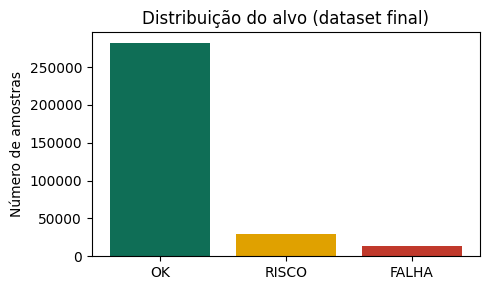

,treino,validacao,teste,nao_visto
alvo,,,,
OK,0.8641,0.8740,0.8598,0.8950
RISCO,0.0888,0.0884,0.1047,0.0968
FALHA,0.0472,0.0376,0.0354,0.0082


In [5]:
# ---- 2.5-B · distribuição das classes (desbalanceamento) ----
def preparar_graficos():
    """Para rodar SÓ as células de gráfico: carrega do Drive o que ainda não está na memória
    (dataset final, modelos .joblib, grade_busca.csv, teste_unico.json). Numa execução completa não carrega nada."""
    g = globals()
    if "df_final" not in g:
        g["df_final"] = pd.read_csv(PASTA_PROCESSED / "dataset_final.csv")
    if "arvore_T3" not in g:
        g["arvore_T3"] = joblib.load(PASTA_MODELOS / "arvore_T3.joblib")["modelo"]
    if "FEATURES" not in g:
        g["FEATURES"] = list(joblib.load(PASTA_MODELOS / "arvore_T3.joblib")["features"])
    if "Xtr" not in g:
        tr_, va_ = (g["df_final"][g["df_final"].split == b] for b in ("treino", "validacao"))
        g["Xtr"], g["ytr"] = tr_[g["FEATURES"]].to_numpy(float), tr_.alvo.astype(str).to_numpy()
        g["Xva"], g["yva"] = va_[g["FEATURES"]].to_numpy(float), va_.alvo.astype(str).to_numpy()
    if "Xte" not in g:
        te_ = g["df_final"][g["df_final"].split == "teste"]
        g["Xte"], g["yte"] = te_[g["FEATURES"]].to_numpy(float), te_.alvo.astype(str).to_numpy()
    if "registros" not in g:
        grade = pd.read_csv(PASTA_PROCESSED / "grade_busca.csv")
        grade["params"] = grade["params"].map(json.loads)
        g["registros"] = grade.to_dict("records")
    if "registros_arv" not in g:
        g["registros_arv"] = [r for r in g["registros"] if r["familia"] == "arvore_decisao"]
    if "pred_va_T3" not in g:
        g["pred_va_T3"] = g["arvore_T3"].predict(g["Xva"])
    if "melhores" not in g:
        def linha_do_modelo(familia, params):
            return next(r for r in g["registros"] if r["familia"] == familia and r["params"] == params)
        pac_arv, pac_t4 = joblib.load(PASTA_MODELOS / "arvore_T3.joblib"), joblib.load(PASTA_MODELOS / "modelo_T4.joblib")
        g["melhores"] = {"arvore_decisao": {**linha_do_modelo("arvore_decisao", pac_arv["params"]), "modelo": pac_arv["modelo"]},
                         pac_t4["familia"]: {**linha_do_modelo(pac_t4["familia"], pac_t4["params"]), "modelo": pac_t4["modelo"]}}
    if "teste_unico" not in g and (PASTA_PROCESSED / "teste_unico.json").exists():
        g["teste_unico"] = json.loads((PASTA_PROCESSED / "teste_unico.json").read_text(encoding="utf-8"))
    if "congelado" not in g and (PASTA_PROCESSED / "modelo_final_congelado.json").exists():
        g["congelado"] = json.loads((PASTA_PROCESSED / "modelo_final_congelado.json").read_text(encoding="utf-8"))

if "df_final" not in globals():          # execução parcial: lê o dataset final já gravado no Drive
    df_final = pd.read_csv(PASTA_PROCESSED / "dataset_final.csv")
contagem_alvo = df_final["alvo"].value_counts().reindex(CLASSES)
print(pd.DataFrame({"n": contagem_alvo, "%": (contagem_alvo / contagem_alvo.sum() * 100).round(2)}))

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(CLASSES, contagem_alvo.values, color=["#0f6e56", "#e0a100", "#c0392b"])
ax.set_ylabel("Número de amostras")
ax.set_title("Distribuição do alvo (dataset final)")
plt.tight_layout()
fig.savefig(PASTA_FIGURAS / "distribuicao_classes.jpg", dpi=150)
plt.show()

# Proporção das classes em cada bloco
display(pd.DataFrame({b: df_final.loc[df_final.split == b, "alvo"].value_counts(normalize=True)
                      for b in ("treino", "validacao", "teste", "nao_visto")}).reindex(CLASSES).round(4))

## 2.6 Dicionário de dados v0.2

| Coluna | Papel | Significado |
|---|---|---|
| `perda_pct` | variável | perda da medição atual (0, 33, 67, 100) |
| `rtt_ausente` | variável | 1 se não houve RTT utilizável |
| `razao_rtt_p95`, `razao_rtt_p99` | variável | RTT atual dividido pelo P95/P99 do próprio fluxo no período A |
| `razao_jitter_p95` | variável | jitter atual dividido pelo P95 do jitter do fluxo |
| `amplitude_rtt_rel` | variável | `(rtt_max − rtt_min) / rtt_avg` |
| `delta_ttl_clip` | variável | TTL atual menos a mediana do A, limitado a ±16 |
| `ttl_reset` | variável | 1 se o TTL mudou 64 ou mais |
| `perdas_consecutivas` | variável | medições seguidas com perda maior que zero, até a atual |
| `perda_media_wN`, `rtt_p95_max_wN`, `jitter_p95_max_wN`, `n_rtt_acima_p95_wN` (N = 3, 6, 12) | variável | estatísticas das últimas N medições do fluxo (`-1` = sem RTT utilizável) |
| `classe_atual` | **só auditoria** | classe da medição atual (nunca variável) |
| `alvo` | **alvo** | classe da próxima medição |
| `split` | controle | treino, validacao, teste ou nao_visto |
| `rtt_ms` | **só auditoria** | RTT absoluto; só na árvore de contraste (3.4) |

---
# Tarefa 3 — Primeira árvore

Segue a etapa 8 do modelo da professora, só com a família **árvore de decisão**.

In [15]:
# ---- Tarefas 3, 4 e 5 · funções do modelo (mesmas da etapa 8 da professora) ----
from sklearn.tree import export_text
GRADES_COMPLETAS = {
    "naive_bayes": {"var_smoothing": (1e-9, 1e-6, 1e-3, 1e-1)},
    "arvore_decisao": {"max_depth": (3, 5, 8, 12, None), "min_samples_leaf": (1, 20, 100), "class_weight": (None, "balanced")},
    "random_forest": {"n_estimators": (100, 200), "max_depth": (6, 12, None), "min_samples_leaf": (5, 50),
                      "max_features": ("sqrt",), "class_weight": (None, "balanced_subsample")},
}
GRADES = GRADES_COMPLETAS
if MODO_RAPIDO:
    GRADES = {"naive_bayes": {"var_smoothing": (1e-9, 1e-1)},
              "arvore_decisao": {"max_depth": (5, None), "min_samples_leaf": (20,), "class_weight": (None,)},
              "random_forest": {"n_estimators": (30,), "max_depth": (6, None), "min_samples_leaf": (5,),
                                "max_features": ("sqrt",), "class_weight": (None,)}}
ALGORITMOS = ("naive_bayes", "arvore_decisao", "random_forest")

def fatia_metricas(y_verdadeiro, y_previsto):
    """Precisão, recall, F1, macro-F1 e matriz 3x3. Classe ausente sai da média (nunca vira zero)."""
    v, p = np.asarray(y_verdadeiro).astype(str), np.asarray(y_previsto).astype(str)
    por_classe, f1s, matriz = {}, [], []
    for c in CLASSES:
        real, prev = v == c, p == c
        sup, tp, fp = int(real.sum()), int((real & prev).sum()), int((~real & prev).sum())
        matriz.append([int(((v == c) & (p == o)).sum()) for o in CLASSES])
        if sup == 0:
            por_classe[c] = {"precisao": None, "recall": None, "f1": None, "suporte": 0}
            continue
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / sup
        f1 = 0.0 if prec + rec == 0 else 2 * prec * rec / (prec + rec)
        por_classe[c] = {"precisao": prec, "recall": rec, "f1": f1, "suporte": sup}
        f1s.append(f1)
    return {"n": int(len(v)), "por_classe": por_classe, "macro_f1": float(np.mean(f1s)) if f1s else None,
            "acuracia": float((v == p).mean()) if len(v) else None, "matriz": matriz,
            "recall_falha": por_classe["FALHA"]["recall"], "recall_risco": por_classe["RISCO"]["recall"], "f1_falha": por_classe["FALHA"]["f1"]}

def avaliar_fatias(y_verdadeiro, y_previsto, classe_atual, anchor):
    """Geral, transições (classe muda), início de falha e sem a âncora que concentra as FALHA."""
    v, p, a, an = (np.asarray(x).astype(str) for x in (y_verdadeiro, y_previsto, classe_atual, anchor))
    saida = {"geral": fatia_metricas(v, p)}
    tr_ = a != v
    saida["transicoes"] = fatia_metricas(v[tr_], p[tr_])
    ini = (a != "FALHA") & (v == "FALHA")
    saida["inicio_falha"] = fatia_metricas(v[ini], p[ini])
    falha = v == "FALHA"
    if falha.any():
        val, cont = np.unique(an[falha], return_counts=True)
        dom = val[sorted(range(len(val)), key=lambda i: (-cont[i], val[i]))[0]]
        saida["sem_ancora_dominante"] = fatia_metricas(v[an != dom], p[an != dom])
    else:
        saida["sem_ancora_dominante"] = saida["geral"]
    return saida

def criar_modelo(familia, params):
    if familia == "naive_bayes":
        return GaussianNB(var_smoothing=params["var_smoothing"])
    if familia == "arvore_decisao":
        return DecisionTreeClassifier(max_depth=params["max_depth"], min_samples_leaf=params["min_samples_leaf"],
                                      class_weight=params["class_weight"], random_state=SEED)
    return RandomForestClassifier(n_estimators=params["n_estimators"], max_depth=params["max_depth"], min_samples_leaf=params["min_samples_leaf"],
                                  max_features=params["max_features"], class_weight=params["class_weight"], random_state=SEED, n_jobs=-1)

def candidatos_da_grade(familia):
    g = GRADES[familia]; chaves = list(g)
    for ordem, comb in enumerate(itertools.product(*(g[k] for k in chaves))):
        yield ordem, dict(zip(chaves, comb))

def chave_desempate(item):
    """Maior macro-F1 na validação; depois menor gap treino-validação; depois a família e o modelo mais simples."""
    prof = item["params"].get("max_depth", 0)
    prof = 10**9 if prof is None else prof
    return (-item["macro_f1_validacao"], item["gap"], ALGORITMOS.index(item["familia"]), prof, int(item["params"].get("n_estimators", 0)), item["ordem"])

def treinar_familia(familia):
    """Treina cada candidato da grade SÓ no treino e escolhe o melhor pela validação."""
    registros, melhor = [], None
    for ordem, params in candidatos_da_grade(familia):
        m = criar_modelo(familia, params).fit(Xtr, ytr)
        f_tr, f_va = fatia_metricas(ytr, m.predict(Xtr)), avaliar_fatias(yva, m.predict(Xva), atual_va, anchor_va)
        item = {"familia": familia, "ordem": ordem, "params": params, "macro_f1_treino": f_tr["macro_f1"],
                "macro_f1_validacao": f_va["geral"]["macro_f1"], "gap": f_tr["macro_f1"] - f_va["geral"]["macro_f1"],
                "recall_falha_validacao": f_va["geral"]["recall_falha"], "recall_risco_validacao": f_va["geral"]["recall_risco"], "validacao": f_va}
        registros.append(item)
        if melhor is None or chave_desempate(item) < chave_desempate(melhor):
            melhor = {**item, "modelo": m}
    print(f"  {familia}: {len(registros)} candidatos | melhor {melhor['params']} | macro-F1 validação {melhor['macro_f1_validacao']:.4f}")
    return registros, melhor

def regras_em_portugues(modelo, colunas, quantas=3):
    """Lê da própria árvore as folhas com mais amostras e escreve o caminho em português."""
    t = modelo.tree_
    folhas = []
    def descer(no, caminho):
        if t.children_left[no] == -1:
            folhas.append((int(t.n_node_samples[no]), CLASSES_ARVORE[int(np.argmax(t.value[no][0]))], caminho)); return
        nome, lim = colunas[t.feature[no]], t.threshold[no]
        descer(t.children_left[no], caminho + [f"{nome} <= {lim:.3g}"]); descer(t.children_right[no], caminho + [f"{nome} > {lim:.3g}"])
    CLASSES_ARVORE = list(modelo.classes_)
    descer(0, [])
    return [f"SE {' E '.join(c) if c else '(sem condição)'} ENTÃO prevê {cl} ({n} amostras de treino)"
            for n, cl, c in sorted(folhas, key=lambda x: -x[0])[:quantas]]

def mostrar_matriz(metricas, titulo):
    print(titulo)
    display(pd.DataFrame(metricas["matriz"], index=[f"real {c}" for c in CLASSES], columns=[f"previsto {c}" for c in CLASSES]))
    display(pd.DataFrame(metricas["por_classe"]).T[["precisao", "recall", "f1", "suporte"]].round(4))
print("Funções do modelo definidas")

Funções do modelo definidas


In [16]:
# ---- Tarefas 3, 4 e 5 · carregar o dataset final ----
AUTOR_T3 = AUTOR_T4 = AUTOR_T5 = AUTOR
df_modelo = pd.read_csv(PASTA_PROCESSED / "dataset_final.csv")
corte_json = json.loads((PASTA_PROCESSED / "corte_temporal.json").read_text(encoding="utf-8"))
assert not (set(FEATURES) & COLS_PROIBIDAS) and len(FEATURES) == 21
# Treino e validação. O bloco de TESTE só é aberto na seção 5.2.
tr = df_modelo[df_modelo.split == "treino"].reset_index(drop=True)
va = df_modelo[df_modelo.split == "validacao"].reset_index(drop=True)
Xtr, ytr = tr[FEATURES].to_numpy(float), tr.alvo.astype(str).to_numpy()
Xva, yva = va[FEATURES].to_numpy(float), va.alvo.astype(str).to_numpy()
atual_va, anchor_va = va.classe_atual.astype(str).to_numpy(), va.anchor_id.astype(str).to_numpy()


print(f"Treino: {milhar(len(tr))} linhas | validação: {milhar(len(va))} linhas | variáveis: {len(FEATURES)} | grades: {'reduzidas (MODO_RAPIDO)' if MODO_RAPIDO else 'completas'}")

Treino: 211.040 linhas | validação: 40.651 linhas | variáveis: 21 | grades: completas


## 3.0 Métricas e como a árvore aprende

### Métricas de avaliação

Cada **linha** da matriz de confusão é a classe **real** e cada **coluna** a classe **prevista**; a diagonal são os acertos. Para uma classe (ex.: `FALHA` contra o resto): **VP** = era FALHA e previu FALHA; **FP** = previu FALHA sem ser (**alarme falso**); **FN** = era FALHA e previu outra coisa (**falha não detectada**).

| Métrica | Fórmula | Pergunta que responde |
| --- | --- | --- |
| Acurácia | acertos ÷ total | Quanto acertou no geral? **Enganosa** com ~87% de `OK` |
| Precisão | VP ÷ (VP + FP) | Dos alertas emitidos, quantos estavam certos? |
| Recall (revocação) | VP ÷ (VP + FN) | Das ocorrências reais, quantas foram detectadas? |
| F1 | 2·P·R ÷ (P + R) | Equilíbrio entre precisão e recall |
| **F1 macro** | média simples do F1 das 3 classes | Cada classe pesa igual: é a **métrica de seleção** |

O **recall de FALHA** é sempre informado à parte, porque deixar passar uma FALHA é o erro mais caro.

### Como a árvore aprende (CART)

A árvore faz perguntas do tipo `variável <= limiar`. Em cada nó, testa todas as variáveis e limiares e escolhe a divisão que mais “purifica” os filhos (construção **recursiva e gulosa**). A impureza padrão é a de **Gini**: $G = 1-\sum_k p_k^2$ (0 = nó puro; 0,667 = três classes iguais). O ganho de uma divisão é $\Delta G = G_{pai} - \left(\frac{n_E}{n}G_E+\frac{n_D}{n}G_D\right)$. Para classificar, a medição **desce da raiz até uma folha**.

| Hiperparâmetro | Valores testados | Por quê |
| --- | --- | --- |
| `max_depth` | 3, 5, 8, 12, None | Profundidade máxima: raso demais não aprende (*underfitting*), fundo demais decora (*overfitting*) |
| `min_samples_leaf` | 1, 20, 100 | Mínimo de amostras por folha: folhas maiores generalizam melhor |
| `class_weight` | None, balanced | `balanced` dá mais peso às classes raras (RISCO e FALHA) |

A figura abaixo é uma árvore **ilustrativa** (`max_depth=3`), só para ver como as perguntas se encadeiam. Ela **não é o modelo**.

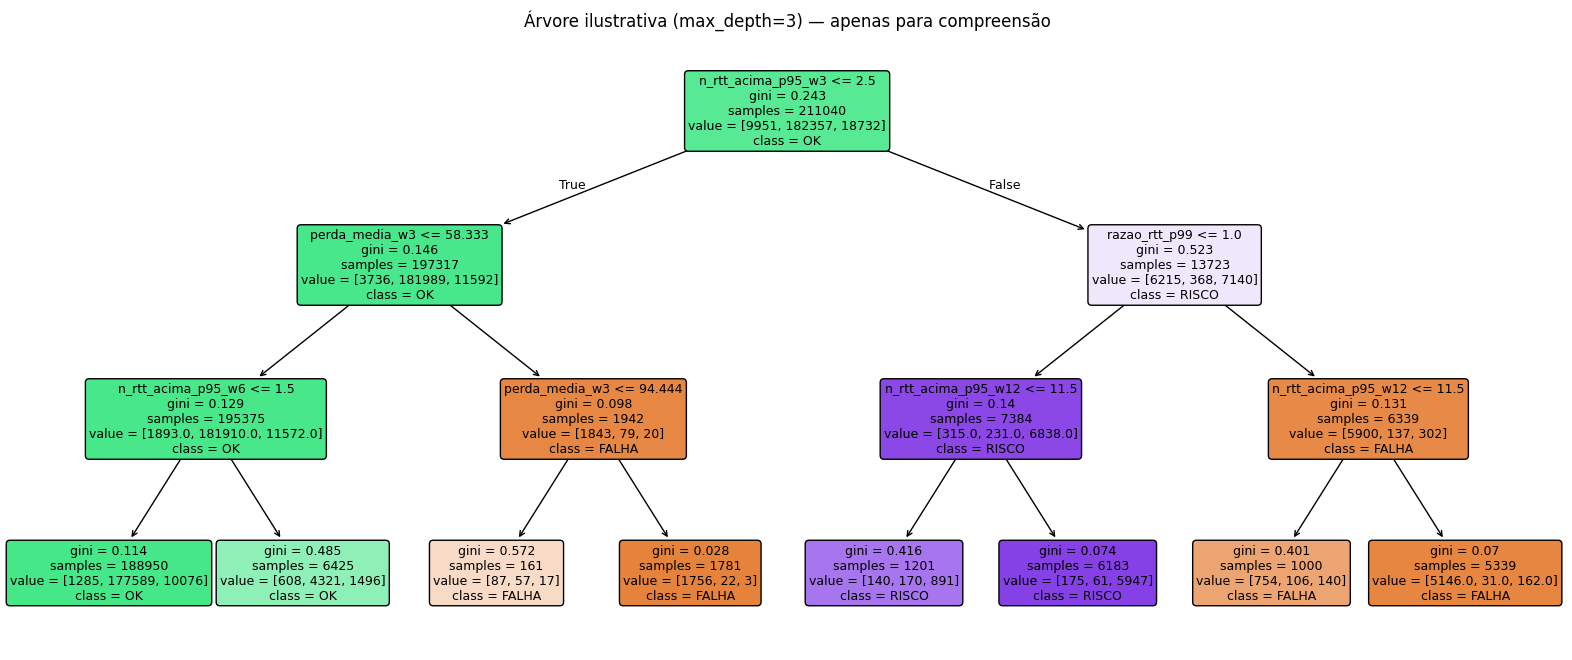

Ordem das classes no scikit-learn (alfabética): ['FALHA', 'OK', 'RISCO'] -> nas métricas usamos a ordem OK, RISCO, FALHA.


In [17]:
# ---- 3.0 · árvore ilustrativa (max_depth=3), só para compreensão — NÃO é o modelo ----
if "Xtr" not in globals():           # só carrega do Drive se as Tarefas 3-5 não tiverem rodado
    preparar_graficos()
if "sem_fluxo" not in globals() and "df_fluxos" in globals():   # execução parcial (sem a Tarefa 1): usado no texto da 5.4
    sem_fluxo = sorted(set(df_fluxos.anchor_id) - {int(f.split("_")[1]) for f in fluxos_modelo})
arvore_didatica = DecisionTreeClassifier(max_depth=3, min_samples_leaf=100, random_state=SEED).fit(Xtr, ytr)
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(arvore_didatica, feature_names=FEATURES, class_names=list(arvore_didatica.classes_),
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Árvore ilustrativa (max_depth=3) — apenas para compreensão")
fig.savefig(PASTA_FIGURAS / "arvore_ilustrativa.jpg", dpi=120, bbox_inches="tight")
plt.show()
print("Ordem das classes no scikit-learn (alfabética):", list(arvore_didatica.classes_),
      "-> nas métricas usamos a ordem OK, RISCO, FALHA.")

def rotulo_combinacao(params):
    prof = params.get("max_depth"); prof = "livre" if prof is None else prof
    peso = params.get("class_weight"); peso = "nenhum" if peso is None else str(peso)[:8]
    base = f"d={prof}\nleaf={params.get('min_samples_leaf')}\n{peso}"
    return f"n={params['n_estimators']}\n{base}" if "n_estimators" in params else base

def grafico_busca(registros_familia, pred_validacao, titulo, arquivo):
    """Esquerda: as 4 melhores combinações (macro-F1 na validação). Direita: matriz de confusão na validação."""
    top4 = sorted(registros_familia, key=lambda r: -r["macro_f1_validacao"])[:4]
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
    eixos[0].bar([rotulo_combinacao(r["params"]) for r in top4], [r["macro_f1_validacao"] for r in top4], color="#0f6e56")
    eixos[0].set_ylim(0, 1); eixos[0].set_ylabel("Macro-F1 (validação)"); eixos[0].set_title(f"{titulo}: quatro melhores combinações")
    ConfusionMatrixDisplay(confusion_matrix(yva, pred_validacao, labels=CLASSES), display_labels=CLASSES).plot(ax=eixos[1], colorbar=False)
    eixos[1].set_title(f"{titulo}: matriz na validação")
    plt.tight_layout(); fig.savefig(PASTA_FIGURAS / arquivo, dpi=150); plt.show()

## 3.1 e 3.2 A árvore oficial

CART treinada **só no bloco de treino**, com a grade e o desempate do modelo da professora (`max_depth`, `min_samples_leaf`, `class_weight`; maior macro-F1 na validação, depois menor gap treino-validação, depois a árvore mais simples). A referência é a **persistência** (repetir a classe atual).

**Corrigido (C12):** antes a árvore usava a classe da mesma linha como alvo e grade própria. **Fonte:** `08_treino/src/treinar_modelos.py: criar_modelo(), candidatos_da_grade(), chave_desempate()`.

In [18]:
# ---- 3.1 e 3.2 · a árvore oficial (CART): grade e desempate escolhidos só na validação ----
persist_va = fatia_metricas(yva, atual_va)                           # referência: repetir a classe atual
registros_arv, melhor_arv = treinar_familia("arvore_decisao")
arvore_T3 = melhor_arv["modelo"]
pred_va_T3 = arvore_T3.predict(Xva)
metricas_T3 = avaliar_fatias(yva, pred_va_T3, atual_va, anchor_va)
print(f"\nÁrvore T3: {melhor_arv['params']} | profundidade obtida {arvore_T3.get_depth()} | {arvore_T3.get_n_leaves()} folhas | semente {SEED}")
print(f"Persistência na validação: macro-F1 {persist_va['macro_f1']:.4f}  |  árvore T3: {metricas_T3['geral']['macro_f1']:.4f}")
print("\nPrimeiras divisões lidas da própria árvore:")
print(export_text(arvore_T3, feature_names=FEATURES, max_depth=2))
print("Três regras em português (folhas com mais amostras):")
for r in regras_em_portugues(arvore_T3, FEATURES, 3):
    print(" -", r)
joblib.dump({"modelo": arvore_T3, "features": FEATURES, "params": melhor_arv["params"]}, PASTA_MODELOS / "arvore_T3.joblib")
registrar_evidencia("3.2", f"Árvore CART treinada só no treino: {melhor_arv['params']}, {arvore_T3.get_n_leaves()} folhas; macro-F1 validação {metricas_T3['geral']['macro_f1']:.4f} vs persistência {persist_va['macro_f1']:.4f}", AUTOR_T3)

  arvore_decisao: 30 candidatos | melhor {'max_depth': 12, 'min_samples_leaf': 100, 'class_weight': None} | macro-F1 validação 0.7691

Árvore T3: {'max_depth': 12, 'min_samples_leaf': 100, 'class_weight': None} | profundidade obtida 12 | 220 folhas | semente 42
Persistência na validação: macro-F1 0.7261  |  árvore T3: 0.7691

Primeiras divisões lidas da própria árvore:
|--- n_rtt_acima_p95_w3 <= 2.50
|   |--- perda_media_w3 <= 58.33
|   |   |--- n_rtt_acima_p95_w6 <= 1.50
|   |   |   |--- truncated branch of depth 10
|   |   |--- n_rtt_acima_p95_w6 >  1.50
|   |   |   |--- truncated branch of depth 10
|   |--- perda_media_w3 >  58.33
|   |   |--- jitter_p95_max_w3 <= -0.50
|   |   |   |--- truncated branch of depth 5
|   |   |--- jitter_p95_max_w3 >  -0.50
|   |   |   |--- class: FALHA
|--- n_rtt_acima_p95_w3 >  2.50
|   |--- razao_rtt_p99 <= 1.00
|   |   |--- n_rtt_acima_p95_w12 <= 11.50
|   |   |   |--- truncated branch of depth 5
|   |   |--- n_rtt_acima_p95_w12 >  11.50
|   |   |  

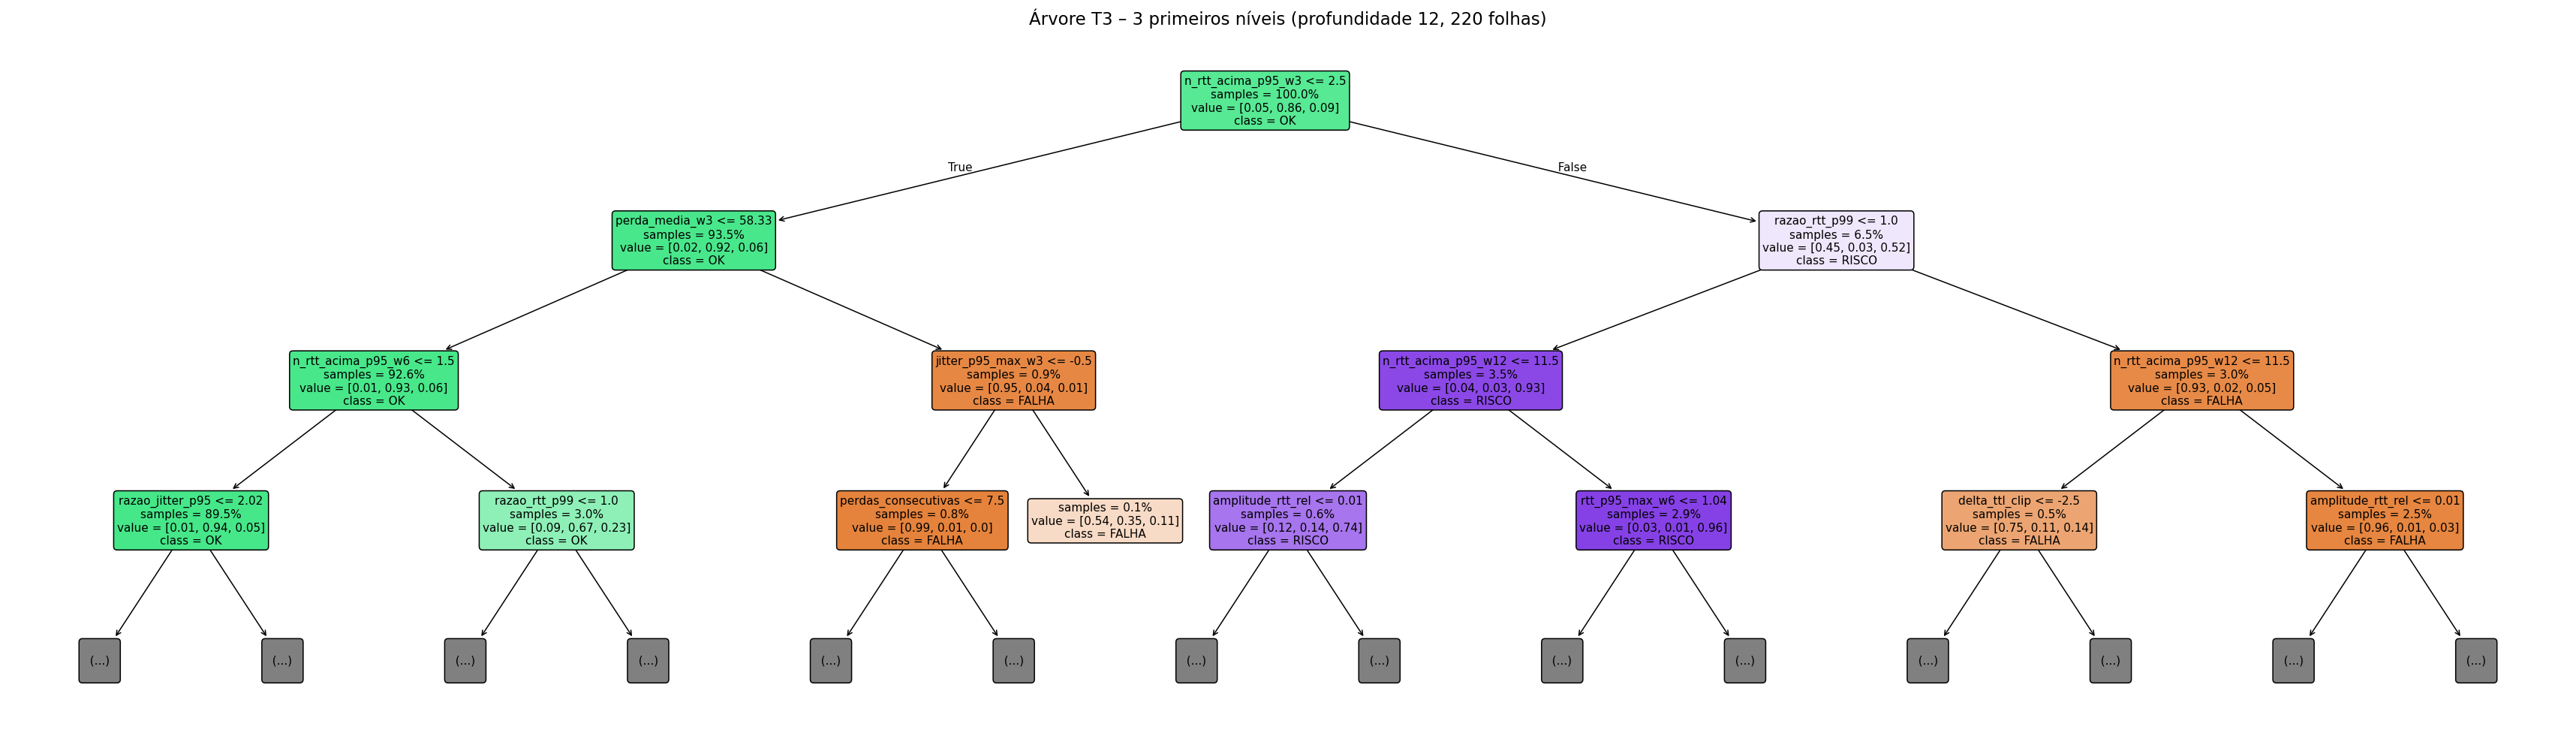

Regras completas da árvore T3 em modelos/arvore_T3_regras.txt (658 linhas)


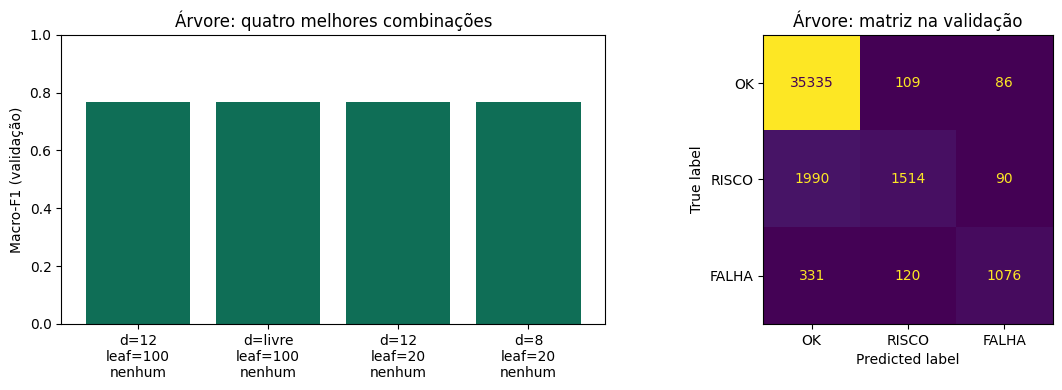

              precision    recall  f1-score   support

          OK       0.94      0.99      0.97     35530
       RISCO       0.87      0.42      0.57      3594
       FALHA       0.86      0.70      0.77      1527

    accuracy                           0.93     40651
   macro avg       0.89      0.71      0.77     40651
weighted avg       0.93      0.93      0.92     40651



In [19]:
# ---- 3.2-B · árvore T3 desenhada, regras completas, melhores combinações e matriz (validação) ----
from sklearn.tree import export_text
if "pred_va_T3" not in globals():     # só carrega do Drive se a Tarefa 3 não tiver rodado
    preparar_graficos()
fig, ax = plt.subplots(figsize=(40, 11), dpi=110)
plot_tree(arvore_T3, feature_names=FEATURES, class_names=list(arvore_T3.classes_), max_depth=3, filled=True, rounded=True,
          impurity=False, proportion=True, precision=2, fontsize=10, ax=ax)
ax.set_title(f"Árvore T3 – 3 primeiros níveis (profundidade {arvore_T3.get_depth()}, {arvore_T3.get_n_leaves()} folhas)", fontsize=15)
fig.savefig(PASTA_FIGURAS / "arvore_T3_niveis_1a3.jpg", bbox_inches="tight")
plt.show()
regras_T3 = export_text(arvore_T3, feature_names=FEATURES, show_weights=True, decimals=3, max_depth=arvore_T3.get_depth())
(PASTA_MODELOS / "arvore_T3_regras.txt").write_text(regras_T3, encoding="utf-8")
print(f"Regras completas da árvore T3 em modelos/arvore_T3_regras.txt ({len(regras_T3.splitlines())} linhas)")

grafico_busca(registros_arv, pred_va_T3, "Árvore", "busca_arvore.jpg")
print(classification_report(yva, pred_va_T3, labels=CLASSES, zero_division=0))

## 3.3 Leitura do erro (validação)

Matriz 3×3, precisão, recall e F1 por classe, F1 macro, as fatias *transições* e *início de falha* e casos concretos de erro.

In [20]:
# ---- 3.3 · leitura do erro na validação ----
g = metricas_T3["geral"]
mostrar_matriz(g, "Matriz 3x3 da árvore T3 (validação). Linha = classe real do PRÓXIMO instante; coluna = prevista:")
print(f"F1 macro: {g['macro_f1']:.4f} | recall FALHA: {g['recall_falha']} | recall RISCO: {g['recall_risco']}")
for nome in ("transicoes", "inicio_falha", "sem_ancora_dominante"):
    f = metricas_T3[nome]
    print(f"fatia {nome}: n={f['n']}  macro-F1={f['macro_f1']}  recall FALHA={f['recall_falha']}")
erros = va.assign(previsto=pred_va_T3)[lambda d: d.previsto != d.alvo]
print(f"\nErros na validação: {milhar(len(erros))} de {milhar(len(va))} ({len(erros)/len(va)*100:.2f}%) | "
      f"em transições (a classe muda): {(erros.classe_atual != erros.alvo).mean()*100:.1f}% dos erros")
display(erros[["id_fluxo", "timestamp", "classe_atual", "alvo", "previsto", "perda_pct", "razao_rtt_p99"]].head(5))
registrar_evidencia("3.3", f"Leitura do erro: F1 macro {g['macro_f1']:.4f}, recall FALHA {g['recall_falha']}, {len(erros)} erros na validação ({(erros.classe_atual != erros.alvo).mean()*100:.1f}% em transições)", AUTOR_T3)

Matriz 3x3 da árvore T3 (validação). Linha = classe real do PRÓXIMO instante; coluna = prevista:


,previsto OK,previsto RISCO,previsto FALHA
real OK,35335,109,86
real RISCO,1990,1514,90
real FALHA,331,120,1076


,precisao,recall,f1,suporte
OK,0.9384,0.9945,0.9656,35530.0
RISCO,0.8686,0.4213,0.5674,3594.0
FALHA,0.8594,0.7046,0.7744,1527.0


F1 macro: 0.7691 | recall FALHA: 0.704649639816634 | recall RISCO: 0.42125765164162493
fatia transicoes: n=4121  macro-F1=0.2122097622748854  recall FALHA=0.0049261083743842365
fatia inicio_falha: n=406  macro-F1=0.00980392156862745  recall FALHA=0.0049261083743842365
fatia sem_ancora_dominante: n=38942  macro-F1=0.7488006400929592  recall FALHA=0.6252144082332761

Erros na validação: 2.726 de 40.651 (6.71%) | em transições (a classe muda): 87.4% dos erros


,id_fluxo,timestamp,classe_atual,alvo,previsto,perda_pct,razao_rtt_p99
13,6351_4837,1791057498,OK,RISCO,OK,0.0,0.887889
39,6351_4837,1791063970,OK,RISCO,OK,0.0,0.891258
68,6351_4837,1791071175,OK,RISCO,OK,0.0,0.888332
83,6351_4837,1791074765,OK,RISCO,OK,0.0,0.888022
112,6351_4837,1791081737,OK,RISCO,OK,0.0,0.889012


Evidência já registrada em 2026-10-11T13:55:46+00:00 | não repetida: 3.3


## 3.4 Árvore de contraste (não é o modelo)

Treinada só com **RTT absoluto e rota**, para mostrar o atalho da distância. É descartada da entrega.

In [21]:
# ---- 3.4 · árvore de contraste (NÃO é o modelo): só RTT absoluto e rota ----
rota = (AUDITORIA.probe_pais.fillna("?") + ">" + AUDITORIA.anchor_pais.fillna("?"))
codigos = {r: i for i, r in enumerate(sorted(rota.unique()))}
def X_contraste(d):
    return np.c_[d.rtt_ms.fillna(-1).to_numpy(float), d.id_fluxo.map(rota).map(codigos).to_numpy(float)]
profundidade = melhor_arv["params"]["max_depth"] or 8
contraste = DecisionTreeClassifier(max_depth=profundidade, min_samples_leaf=melhor_arv["params"]["min_samples_leaf"], random_state=SEED).fit(X_contraste(tr), ytr)
f_contraste = fatia_metricas(yva, contraste.predict(X_contraste(va)))
print(export_text(contraste, feature_names=["rtt_ms (absoluto)", "rota (código)"], max_depth=1))
print(f"Contraste (RTT absoluto + rota): macro-F1 validação {f_contraste['macro_f1']:.4f}  vs  árvore oficial {g['macro_f1']:.4f}  vs  persistência {persist_va['macro_f1']:.4f}")
print("Leitura: sem as variáveis relativas ao baseline do próprio fluxo, o corte vira distância/rota. A árvore de contraste é descartada da entrega.")
registrar_evidencia("3.4", f"Árvore de contraste (RTT absoluto + rota) descartada: macro-F1 {f_contraste['macro_f1']:.4f} contra {g['macro_f1']:.4f} da árvore oficial", AUTOR_T3)
registrar_correcao("3.2", "C12", "CART treinada com a grade e o desempate do modelo da professora (max_depth, min_samples_leaf, class_weight; maior macro-F1 na validação, depois menor gap) e comparada com a persistência")

|--- rtt_ms (absoluto) <= -0.15
|   |--- rota (código) <= 120.00
|   |   |--- truncated branch of depth 5
|   |--- rota (código) >  120.00
|   |   |--- truncated branch of depth 2
|--- rtt_ms (absoluto) >  -0.15
|   |--- rota (código) <= 8.50
|   |   |--- truncated branch of depth 11
|   |--- rota (código) >  8.50
|   |   |--- truncated branch of depth 11

Contraste (RTT absoluto + rota): macro-F1 validação 0.5279  vs  árvore oficial 0.7691  vs  persistência 0.7261
Leitura: sem as variáveis relativas ao baseline do próprio fluxo, o corte vira distância/rota. A árvore de contraste é descartada da entrega.
Evidência já registrada em 2026-10-11T13:55:48+00:00 | não repetida: 3.4
Evidência já registrada em 2026-10-11T02:33:49+00:00 | não repetida: 3.2


---
# Tarefa 4 — Ajuste do modelo

Segue a etapa 8 do modelo da professora: três famílias, grade completa, escolha só na validação.

## 4.1 O que o erro pediu

A tabela abaixo é gerada dos números do erro da Tarefa 3 e liga cada erro à mudança testada.

In [22]:
# ---- 4.1 · o que o erro da Tarefa 3 pediu (números gerados do próprio erro) ----
mat = np.array(g["matriz"]); fora = mat.copy(); np.fill_diagonal(fora, 0)
i, j = np.unravel_index(fora.argmax(), fora.shape)
frac_trans = (erros.classe_atual != erros.alvo).mean() if len(erros) else 0.0
diagnostico = pd.DataFrame([
    {"erro observado (validação, árvore T3)": f"confusão mais comum: real {CLASSES[i]} previsto {CLASSES[j]} ({fora[i, j]} casos)", "mudança testada": "class_weight balanced e folha mínima maior"},
    {"erro observado (validação, árvore T3)": f"recall RISCO {g['recall_risco']}, recall FALHA {g['recall_falha']}", "mudança testada": "critério entropia e mais profundidade"},
    {"erro observado (validação, árvore T3)": f"{frac_trans*100:.1f}% dos erros ocorrem quando a classe muda de t para t+1", "mudança testada": "modelos de outras famílias (Naive Bayes e Random Forest) que usam as janelas 3/6/12 de forma diferente"},
    {"erro observado (validação, árvore T3)": f"gap treino-validação da T3 = {melhor_arv['gap']:.4f}", "mudança testada": "poda por ccp_alpha"}])
display(diagnostico)
registrar_evidencia("4.1", f"Diagnóstico do erro da T3: confusão dominante real {CLASSES[i]}->previsto {CLASSES[j]}; {frac_trans*100:.1f}% dos erros em transições", AUTOR_T4)

,"erro observado (validação, árvore T3)",mudança testada
0,confusão mais comum: real RISCO previsto OK (1...,class_weight balanced e folha mínima maior
1,"recall RISCO 0.42125765164162493, recall FALHA...",critério entropia e mais profundidade
2,87.4% dos erros ocorrem quando a classe muda d...,modelos de outras famílias (Naive Bayes e Rand...
3,gap treino-validação da T3 = 0.0233,poda por ccp_alpha


Evidência já registrada em 2026-10-11T02:35:13+00:00 | não repetida: 4.1


## 4.2 Experimentos e modelo ajustado

Primeiro, **uma mudança por vez** na árvore (entropia, folha maior, mais profundidade, poda, `class_weight`). Depois, a grade completa de **Naive Bayes, árvore e Random Forest**, e o modelo é escolhido pelo maior macro-F1 na validação (desempate: menor gap, família mais simples).

**Corrigido (C13):** antes só havia a árvore CART. **Fonte:** `treinar_modelos.py: treinar_familia(), fatia_metricas(), avaliar_fatias()`.

In [23]:
# ---- 4.2 · experimentos (uma mudança por vez) e busca nas três famílias ----
base = dict(melhor_arv["params"]); refer = g["macro_f1"]
def rodar_arvore(nome, mudanca, criterio="gini", ccp=0.0):
    p = {**base, **mudanca}
    m = DecisionTreeClassifier(criterion=criterio, ccp_alpha=ccp, random_state=SEED, **p).fit(Xtr, ytr)
    f = fatia_metricas(yva, m.predict(Xva))
    return {"experimento": nome, "macro_f1_val": f["macro_f1"], "delta_vs_T3": f["macro_f1"] - refer,
            "recall_falha": f["recall_falha"], "recall_risco": f["recall_risco"], "folhas": m.get_n_leaves()}
exps = [rodar_arvore("critério entropia", {}, criterio="entropy"),
        rodar_arvore("folha mínima maior", {"min_samples_leaf": max(base["min_samples_leaf"] * 5, 20)}),
        rodar_arvore("mais profundidade", {"max_depth": None}),
        rodar_arvore("poda ccp_alpha=0,0005", {}, ccp=0.0005),
        rodar_arvore("class_weight balanced", {"class_weight": "balanced"})]
df_exp = pd.DataFrame(exps).round(4)
display(df_exp)

print("\nBusca com a grade completa de cada família (treino -> validação):")
registros = list(registros_arv); melhores = {"arvore_decisao": melhor_arv}
for fam in ("naive_bayes", "random_forest"):
    reg, mel = treinar_familia(fam)
    registros += reg; melhores[fam] = mel
escolhido = min(melhores.values(), key=chave_desempate)
modelo_T4 = escolhido["modelo"]
pd.DataFrame([{k: (json.dumps(v) if k == "params" else v) for k, v in r.items() if k not in ("validacao", "modelo")} for r in registros]).to_csv(PASTA_PROCESSED / "grade_busca.csv", index=False)
joblib.dump({"modelo": modelo_T4, "features": FEATURES, "familia": escolhido["familia"], "params": escolhido["params"]}, PASTA_MODELOS / "modelo_T4.joblib")
print(f"\nModelo escolhido pela validação: {escolhido['familia']} {escolhido['params']} | macro-F1 validação {escolhido['macro_f1_validacao']:.4f} | gap {escolhido['gap']:.4f}")
registrar_evidencia("4.2", f"Experimentos T3->T4 e grade das 3 famílias; escolhido {escolhido['familia']} {escolhido['params']} com macro-F1 de validação {escolhido['macro_f1_validacao']:.4f}", AUTOR_T4)
registrar_correcao("4.2", "C13", "três famílias (Naive Bayes, árvore, Random Forest) com a grade da professora; escolha pelo maior macro-F1 na validação, desempate por menor gap e modelo mais simples; fatias de avaliação")

,experimento,macro_f1_val,delta_vs_T3,recall_falha,recall_risco,folhas
0,critério entropia,0.7675,-0.0016,0.7099,0.4160,295
1,folha mínima maior,0.7671,-0.0020,0.7079,0.4293,107
2,mais profundidade,0.7691,0.0000,0.7046,0.4213,1453
3,"poda ccp_alpha=0,0005",0.7602,-0.0090,0.7079,0.3901,7
4,class_weight balanced,0.6828,-0.0863,0.7616,0.5657,299



Busca com a grade completa de cada família (treino -> validação):
  naive_bayes: 4 candidatos | melhor {'var_smoothing': 0.001} | macro-F1 validação 0.5223
  random_forest: 24 candidatos | melhor {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': None} | macro-F1 validação 0.7702

Modelo escolhido pela validação: random_forest {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': None} | macro-F1 validação 0.7702 | gap 0.0521
Evidência já registrada em 2026-10-11T14:35:49+00:00 | não repetida: 4.2
Evidência já registrada em 2026-10-11T03:23:37+00:00 | não repetida: 4.2


## 4.3 Comparação na validação (Tarefa 3 → Tarefa 4)

In [24]:
# ---- 4.3 · comparação na validação (Tarefa 3 -> Tarefa 4) ----
def linha(nome, f):
    return {"modelo": nome, "F1 macro": f["geral"]["macro_f1"], "recall FALHA": f["geral"]["recall_falha"], "recall RISCO": f["geral"]["recall_risco"],
            "F1 macro (transições)": f["transicoes"]["macro_f1"], "recall FALHA (início de falha)": f["inicio_falha"]["recall_falha"]}
pers_fatias = avaliar_fatias(yva, atual_va, atual_va, anchor_va)
metricas_T4 = avaliar_fatias(yva, modelo_T4.predict(Xva), atual_va, anchor_va)
tabela_T3_T4 = pd.DataFrame([linha("Persistência (classe atual)", pers_fatias), linha(f"T3: árvore", metricas_T3), linha(f"T4: {escolhido['familia']}", metricas_T4)]).round(4)
display(tabela_T3_T4)
ganho = metricas_T4["geral"]["macro_f1"] - metricas_T3["geral"]["macro_f1"]
print(f"Ganho T3 -> T4 em F1 macro: {ganho:+.4f}  |  T4 contra a persistência: {metricas_T4['geral']['macro_f1'] - pers_fatias['geral']['macro_f1']:+.4f}")
mostrar_matriz(metricas_T4["geral"], "Matriz 3x3 do modelo da Tarefa 4 (validação):")
tabela_T3_T4.to_csv(PASTA_PROCESSED / "tabela_T3_T4.csv", index=False)
registrar_evidencia("4.3", f"Tabela T3->T4 gravada: ganho de F1 macro {ganho:+.4f}; modelo T4 = {escolhido['familia']}", AUTOR_T4)

,modelo,F1 macro,recall FALHA,recall RISCO,F1 macro (transições),recall FALHA (início de falha)
0,Persistência (classe atual),0.7261,0.7341,0.4975,0.0000,0.0000
1,T3: árvore,0.7691,0.7046,0.4213,0.2122,0.0049
2,T4: random_forest,0.7702,0.7073,0.4190,0.2192,0.0074


Ganho T3 -> T4 em F1 macro: +0.0011  |  T4 contra a persistência: +0.0441
Matriz 3x3 do modelo da Tarefa 4 (validação):


,previsto OK,previsto RISCO,previsto FALHA
real OK,35367,83,80
real RISCO,1991,1506,97
real FALHA,335,112,1080


,precisao,recall,f1,suporte
OK,0.9383,0.9954,0.9660,35530.0
RISCO,0.8854,0.4190,0.5688,3594.0
FALHA,0.8592,0.7073,0.7759,1527.0


Evidência já registrada em 2026-10-11T14:35:50+00:00 | não repetida: 4.3


### Random Forest: como funciona

Uma árvore profunda tem baixo viés e **alta variância**. A floresta combina muitas árvores diferentes:

- **Bagging:** cada árvore treina numa amostra *bootstrap* (sorteio com reposição, ~63,2% das linhas distintas).
- **Aleatoriedade de atributos (`max_features`):** a cada divisão só um subconjunto de variáveis é considerado (`sqrt` → ~4 a 5 das 21), o que **decorrelaciona** as árvores.
- **Agregação:** as probabilidades das árvores são promediadas e vence a classe mais provável.

| Hiperparâmetro | Valores testados | Por quê |
| --- | --- | --- |
| `n_estimators` | 100, 200 | Número de árvores; mais árvores estabilizam, com custo maior |
| `max_depth` | 6, 12, None | Profundidade de cada árvore |
| `min_samples_leaf` | 5, 50 | Tamanho mínimo das folhas |
| `max_features` | sqrt | Variáveis sorteadas por divisão |
| `class_weight` | None, balanced_subsample | Peso das classes raras, recalculado em cada amostra *bootstrap* |

> Diferenças de milésimos de F1 macro (por exemplo, 100 × 200 árvores) estão dentro do ruído do sorteio. Compare também o F1 de treino com o de validação: um abismo grande indica *overfitting*.

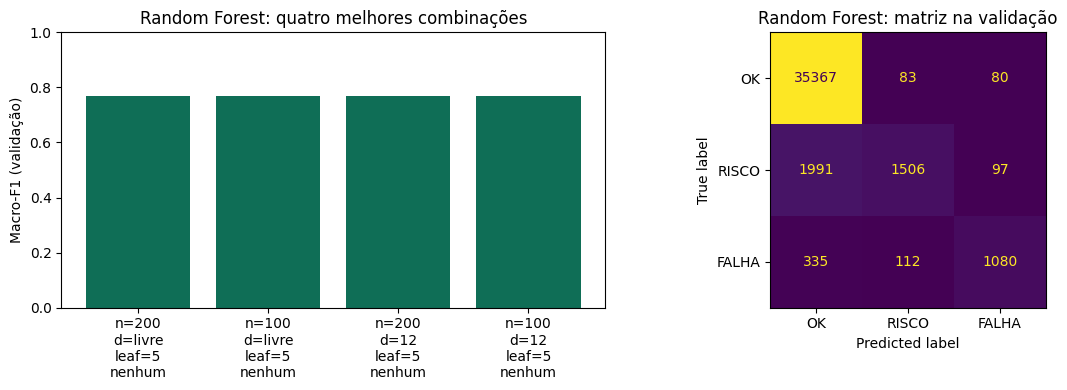

In [25]:
# ---- 4.3-B · Random Forest: melhores combinações e matriz de confusão (validação) ----
if "melhores" not in globals():       # só carrega do Drive se a Tarefa 4 não tiver rodado
    preparar_graficos()
if "random_forest" not in melhores:
    print("O modelo final não é Random Forest; gráfico da floresta não gerado.")
else:
    grafico_busca([r for r in registros if r["familia"] == "random_forest"], melhores["random_forest"]["modelo"].predict(Xva),
                  "Random Forest", "busca_random_forest.jpg")

### Dicionário de dados v0.3

As **variáveis não mudam** (as mesmas 21 da v0.2). O que entra são os artefatos do modelo:

| Artefato | Conteúdo |
|---|---|
| `grade_busca.csv` | uma linha por candidato: família, parâmetros, macro-F1 de treino e validação, gap |
| `modelo_T4.joblib` | modelo escolhido, lista de variáveis, família e parâmetros |
| `tabela_T3_T4.csv` | persistência, T3 e T4 lado a lado (F1 macro, recall de FALHA e RISCO, fatias) |

---
# Tarefa 5 — Modelo final e teste único

## 5.1 Modelo que será medido

O modelo e as variáveis são **congelados** antes do teste, e o notebook confere que país, IP, rota e RTT absoluto não estão entre as variáveis.

In [26]:
# ---- 5.1 · congelar o modelo final ANTES de abrir o teste ----
congelado = {"familia": escolhido["familia"], "params": escolhido["params"], "features": FEATURES, "seed": SEED,
             "macro_f1_validacao": escolhido["macro_f1_validacao"], "congelado_em_utc": agora_iso()}
arq_congelado = PASTA_PROCESSED / "modelo_final_congelado.json"
if not arq_congelado.exists():
    arq_congelado.write_text(json.dumps(congelado, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
congelado = json.loads(arq_congelado.read_text(encoding="utf-8"))
assert not (set(FEATURES) & COLS_PROIBIDAS), "Coluna proibida entre as variáveis"
for proibida in ("anchor_pais", "probe_pais", "anchor_ip", "rtt_ms", "rota", "probe_asn", "faixa_distancia"):
    assert proibida not in FEATURES
print(f"Modelo congelado: {congelado['familia']} {congelado['params']} | {len(FEATURES)} variáveis | país, IP, rota e RTT absoluto NÃO estão no modelo")
if congelado["familia"] == "arvore_decisao":
    for r in regras_em_portugues(modelo_T4, FEATURES, 3): print(" -", r)
registrar_evidencia("5.1", f"Modelo final congelado antes do teste: {congelado['familia']} {congelado['params']} ({len(FEATURES)} variáveis; sem país, IP, rota ou RTT absoluto)", AUTOR_T5)

Modelo congelado: random_forest {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': None} | 21 variáveis | país, IP, rota e RTT absoluto NÃO estão no modelo
Evidência já registrada em 2026-10-11T14:35:50+00:00 | não repetida: 5.1


## 5.2 Teste temporal (uma vez)

Matriz 3×3, F1 por classe, F1 macro, balanced accuracy, recall de FALHA, comparação com a **classe majoritária** e com a **persistência**, mais um acerto em caminho longo e um erro relevante.

**Corrigido (C14):** antes não havia trava de reabertura. Agora o resultado é gravado em `teste_unico.json` e as execuções seguintes só o leem. **Fonte:** `08_treino/src/treinar_modelos.py: avaliar_teste(forcar)`.

In [27]:
# ---- 5.2 · teste temporal (UMA vez) ----
arq_teste = PASTA_PROCESSED / "teste_unico.json"
te = df_modelo[df_modelo.split == "teste"].reset_index(drop=True)
Xte, yte = te[FEATURES].to_numpy(float), te.alvo.astype(str).to_numpy()
if arq_teste.exists():
    teste_unico = json.loads(arq_teste.read_text(encoding="utf-8"))
    print("O teste já foi aberto em", teste_unico["aberto_em_utc"], "- as métricas gravadas são mostradas; NÃO são recalculadas.")
else:
    pred_te = modelo_T4.predict(Xte)
    maj = pd.Series(ytr).value_counts().idxmax()                     # classe majoritária do TREINO
    f_te = avaliar_fatias(yte, pred_te, te.classe_atual.to_numpy(), te.anchor_id.astype(str).to_numpy())
    f_pers = avaliar_fatias(yte, te.classe_atual.to_numpy(), te.classe_atual.to_numpy(), te.anchor_id.astype(str).to_numpy())
    f_maj = fatia_metricas(yte, np.repeat(maj, len(yte)))
    longa = te.assign(prev=pred_te).merge(AUDITORIA[["faixa_distancia"]], left_on="id_fluxo", right_index=True)
    acerto = longa[(longa.faixa_distancia == "longa") & (longa.prev == longa.alvo) & (longa.alvo == "OK")].head(1)
    relevante = longa[(longa.alvo == "FALHA") & (longa.prev != "FALHA")].head(1)
    cols_caso = ["id_fluxo", "timestamp", "classe_atual", "alvo", "prev", "faixa_distancia"]
    teste_unico = {"aberto_em_utc": agora_iso(), "modelo": {"familia": congelado["familia"], "params": congelado["params"]},
                   "n": len(te), "metricas": f_te, "persistencia": f_pers["geral"], "classe_majoritaria": {"classe": maj, **f_maj},
                   "balanced_accuracy": float(balanced_accuracy_score(yte, pred_te)),
                   "caso_acerto_longo": acerto[cols_caso].to_dict("records"), "caso_erro_relevante": relevante[cols_caso].to_dict("records")}
    arq_teste.write_text(json.dumps(teste_unico, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    print("Teste aberto e gravado em", arq_teste.name)
m = teste_unico["metricas"]["geral"]
mostrar_matriz(m, "Matriz 3x3 do TESTE (modelo final):")
print(f"F1 macro: {m['macro_f1']:.4f} | recall FALHA: {m['recall_falha']} | balanced accuracy: {teste_unico['balanced_accuracy']:.4f}")
print(f"Classe majoritária ('{teste_unico['classe_majoritaria']['classe']}' sempre): F1 macro {teste_unico['classe_majoritaria']['macro_f1']:.4f} | persistência: F1 macro {teste_unico['persistencia']['macro_f1']:.4f}")
print("Caso de acerto (caminho longo):", teste_unico["caso_acerto_longo"]); print("Caso de erro relevante:", teste_unico["caso_erro_relevante"])
registrar_evidencia("5.2", f"Teste único aberto em {teste_unico['aberto_em_utc']}: F1 macro {m['macro_f1']:.4f}, recall FALHA {m['recall_falha']}; persistência {teste_unico['persistencia']['macro_f1']:.4f}; classe majoritária {teste_unico['classe_majoritaria']['macro_f1']:.4f}", AUTOR_T5)
registrar_correcao("5.2", "C14", "teste avaliado uma única vez e gravado em teste_unico.json (nas execuções seguintes só é lido); modelo escolhido antes, só com treino e validação")

O teste já foi aberto em 2026-10-11T14:35:52+00:00 - as métricas gravadas são mostradas; NÃO são recalculadas.
Matriz 3x3 do TESTE (modelo final):


,previsto OK,previsto RISCO,previsto FALHA
real OK,34632,105,46
real RISCO,2097,1983,156
real FALHA,253,235,946


,precisao,recall,f1,suporte
OK,0.9365,0.9957,0.9652,34783.0
RISCO,0.8536,0.4681,0.6047,4236.0
FALHA,0.8240,0.6597,0.7328,1434.0


F1 macro: 0.7675 | recall FALHA: 0.6596931659693166 | balanced accuracy: 0.7078
Classe majoritária ('OK' sempre): F1 macro 0.3082 | persistência: F1 macro 0.7302
Caso de acerto (caminho longo): [{'id_fluxo': '6380_1880', 'timestamp': 1791140597, 'classe_atual': 'OK', 'alvo': 'OK', 'prev': 'OK', 'faixa_distancia': 'longa'}]
Caso de erro relevante: [{'id_fluxo': '6407_1360', 'timestamp': 1791189944, 'classe_atual': 'OK', 'alvo': 'FALHA', 'prev': 'OK', 'faixa_distancia': 'media'}]
Evidência já registrada em 2026-10-11T14:35:52+00:00 | não repetida: 5.2
Evidência já registrada em 2026-10-11T13:18:45+00:00 | não repetida: 5.2


## 5.2-B Comparação árvore × Random Forest (validação e teste), matrizes no teste e importância das variáveis

Como no notebook didático da professora, a **árvore** e o **Random Forest** são comparados lado a lado na validação **e no teste**. A árvore é medida no teste **uma única vez**, só para a comparação: o modelo final já tinha sido escolhido na validação, e o resultado do Random Forest no teste (`teste_unico.json`) não muda. O resultado da árvore fica gravado em `teste_arvore_comparacao.json`, e as execuções seguintes só o leem.

Diferenças de poucos milésimos podem não ser relevantes. Se a diferença for pequena, o limite do desempenho está nos **dados** (ruído, fronteira difusa de `RISCO`, qualidade dos rótulos), não no algoritmo.

**Importância das variáveis** (`feature_importances_`): redução total de impureza atribuída a cada variável, normalizada para somar 1. Cuidados: é importância **do modelo**, não causalidade; variáveis correlacionadas (`w3`, `w6`, `w12` da mesma grandeza) **dividem** a importância entre si.

Árvore medida no teste (uma vez) e gravada em teste_arvore_comparacao.json
              precision    recall  f1-score   support

          OK       0.94      1.00      0.96     34783
       RISCO       0.85      0.47      0.60      4236
       FALHA       0.83      0.66      0.73      1434

    accuracy                           0.93     40453
   macro avg       0.87      0.71      0.77     40453
weighted avg       0.92      0.93      0.92     40453

Evidência registrada: 2026-10-20T15:19:47+00:00 | 5.2


,Árvore de Decisão,Random Forest
Macro-F1 validação,0.7691,0.7702
Macro-F1 teste,0.7673,0.7675
Recall FALHA teste,0.6604,0.6597
Recall RISCO teste,0.4677,0.4681
Acurácia teste,0.9281,0.9285


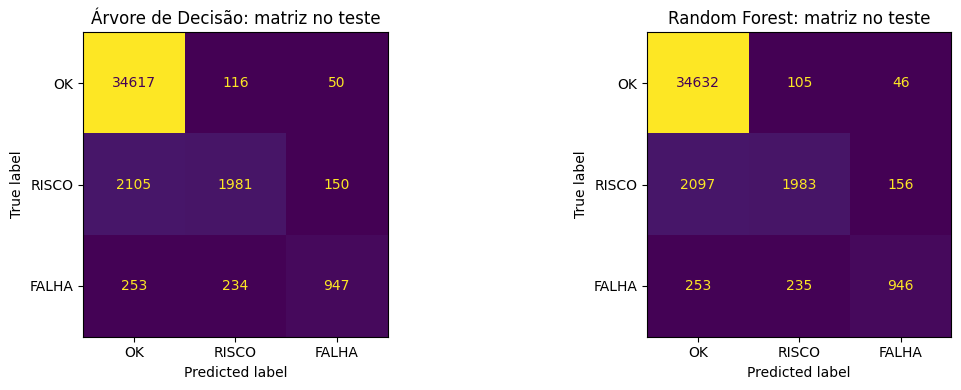

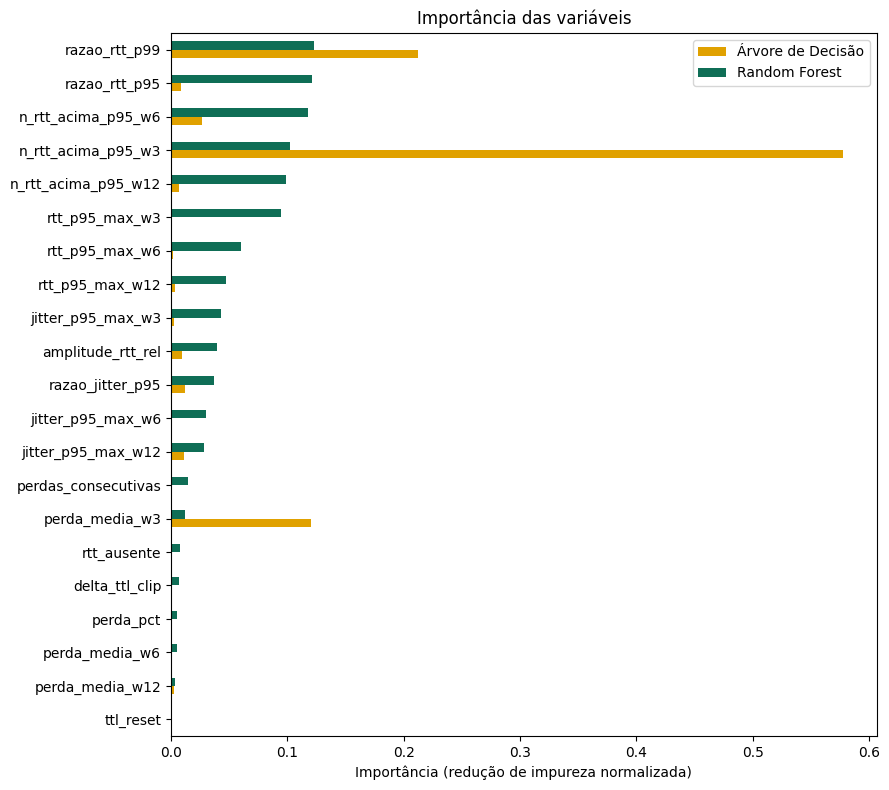

Três variáveis mais importantes (Random Forest): ['razao_rtt_p99', 'razao_rtt_p95', 'n_rtt_acima_p95_w6']
Figuras salvas em modelos/figuras/ | tabela em data/processed/comparacao_arvore_rf.csv


In [28]:
# ---- 5.2-B · comparação árvore x Random Forest (validação e teste), matrizes no teste e importância das variáveis ----
if "melhores" not in globals() or "teste_unico" not in globals():   # só carrega do Drive se as Tarefas 4-5 não tiverem rodado
    preparar_graficos()
nomes = {"arvore_decisao": "Árvore de Decisão", "random_forest": "Random Forest"}

# Árvore no teste: medida UMA vez, só para comparação (a escolha do modelo final já foi feita na validação)
arq_teste_arv = PASTA_PROCESSED / "teste_arvore_comparacao.json"
if arq_teste_arv.exists():
    teste_arvore = json.loads(arq_teste_arv.read_text(encoding="utf-8"))
    print("A árvore já foi medida no teste em", teste_arvore["aberto_em_utc"], "- os números gravados são mostrados; NÃO são recalculados.")
else:
    pred_te_arv = melhores["arvore_decisao"]["modelo"].predict(Xte)
    teste_arvore = {"aberto_em_utc": agora_iso(),
                    "finalidade": "comparação com o modelo final; não altera a escolha feita na validação",
                    "modelo": {"familia": "arvore_decisao", "params": melhores["arvore_decisao"]["params"]},
                    "n": len(yte), "metricas": fatia_metricas(yte, pred_te_arv),
                    "balanced_accuracy": float(balanced_accuracy_score(yte, pred_te_arv))}
    arq_teste_arv.write_text(json.dumps(teste_arvore, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    print("Árvore medida no teste (uma vez) e gravada em", arq_teste_arv.name)
    print(classification_report(yte, pred_te_arv, labels=CLASSES, zero_division=0))
    registrar_evidencia("5.2", f"Árvore T3 medida no teste só para comparação: F1 macro {teste_arvore['metricas']['macro_f1']:.4f}, recall FALHA {teste_arvore['metricas']['recall_falha']:.4f} (modelo final continua {congelado['familia']})", AUTOR_T5)

teste_por_familia = {"arvore_decisao": teste_arvore["metricas"], congelado["familia"]: teste_unico["metricas"]["geral"]}
nomes = {f: n for f, n in nomes.items() if f in teste_por_familia and f in melhores}
comparacao = pd.DataFrame({nomes[f]: {"Macro-F1 validação": melhores[f]["macro_f1_validacao"],
                                      "Macro-F1 teste": teste_por_familia[f]["macro_f1"],
                                      "Recall FALHA teste": teste_por_familia[f]["recall_falha"],
                                      "Recall RISCO teste": teste_por_familia[f]["recall_risco"],
                                      "Acurácia teste": teste_por_familia[f]["acuracia"]} for f in nomes}).round(4)
display(comparacao)
comparacao.to_csv(PASTA_PROCESSED / "comparacao_arvore_rf.csv")

fig, eixos = plt.subplots(1, len(nomes), figsize=(6 * len(nomes), 4), squeeze=False)
for eixo, f in zip(eixos[0], nomes):
    ConfusionMatrixDisplay(np.array(teste_por_familia[f]["matriz"]), display_labels=CLASSES).plot(ax=eixo, colorbar=False)
    eixo.set_title(f"{nomes[f]}: matriz no teste")
plt.tight_layout(); fig.savefig(PASTA_FIGURAS / "matrizes_teste.jpg", dpi=150); plt.show()

imp = pd.DataFrame({nomes[f]: melhores[f]["modelo"].feature_importances_ for f in nomes}, index=FEATURES)
imp = imp.sort_values(imp.columns[-1], ascending=True)
ax = imp.plot(kind="barh", figsize=(9, 8), color=["#e0a100", "#0f6e56"][:len(nomes)])
ax.set_xlabel("Importância (redução de impureza normalizada)"); ax.set_title("Importância das variáveis")
plt.tight_layout(); plt.savefig(PASTA_FIGURAS / "importancia_variaveis.jpg", dpi=150); plt.show()
print(f"Três variáveis mais importantes ({imp.columns[-1]}):", list(imp[imp.columns[-1]].sort_values(ascending=False).index[:3]))
print("Figuras salvas em modelos/figuras/ | tabela em data/processed/comparacao_arvore_rf.csv")

## 5.3 Fluxos que o modelo não viu

Fluxos sorteados com a `SEED` antes do treino, com baseline próprio do Período A.

In [29]:
# ---- 5.3 · fluxos que o modelo não viu (baseline próprio do Período A) ----
nv = df_modelo[df_modelo.split == "nao_visto"].reset_index(drop=True)
if len(nv):
    pred_nv = modelo_T4.predict(nv[FEATURES].to_numpy(float))
    f_nv = avaliar_fatias(nv.alvo.to_numpy(), pred_nv, nv.classe_atual.to_numpy(), nv.anchor_id.astype(str).to_numpy())
    f_nv_p = fatia_metricas(nv.alvo.to_numpy(), nv.classe_atual.to_numpy())
    print(f"{nv.id_fluxo.nunique()} fluxos não vistos | {milhar(len(nv))} linhas | F1 macro do modelo {f_nv['geral']['macro_f1']:.4f} | persistência {f_nv_p['macro_f1']:.4f} | recall FALHA {f_nv['geral']['recall_falha']}")
    tabela_faixa = []
    for faixa, d in nv.assign(prev=pred_nv).merge(AUDITORIA[["faixa_distancia"]], left_on="id_fluxo", right_index=True).groupby("faixa_distancia"):
        deg = d[d.alvo != "OK"]
        tabela_faixa.append({"faixa": faixa, "linhas": len(d), "degradações reais": len(deg), "degradações detectadas (prev != OK)": int((deg.prev != "OK").sum()),
                             "OK mantidos como OK": int(((d.alvo == "OK") & (d.prev == "OK")).sum())})
    display(pd.DataFrame(tabela_faixa))
    registrar_evidencia("5.3", f"{nv.id_fluxo.nunique()} fluxos não vistos: F1 macro {f_nv['geral']['macro_f1']:.4f} (persistência {f_nv_p['macro_f1']:.4f}); fluxos sorteados com a SEED antes do treino", AUTOR_T5)
else:
    print("Poucos fluxos para reservar não vistos nesta execução.")

13 fluxos não vistos | 32.624 linhas | F1 macro do modelo 0.6275 | persistência 0.6207 | recall FALHA 0.26591760299625467


,faixa,linhas,degradações reais,degradações detectadas (prev != OK),OK mantidos como OK
0,curta,4985,270,0,4713
1,longa,15066,2240,1347,12762
2,media,12573,914,108,11640


Evidência já registrada em 2026-10-11T14:35:53+00:00 | não repetida: 5.3


## 5.4 O que declarar

**Corrigido (C15):** antes a comparação era com a classe majoritária. Agora a referência é a persistência, como no modelo da professora (`treinar_modelos.py: conferencia_persistencia()`). O texto abaixo é gerado dos números do teste.

In [30]:
# ---- 5.4 · o que declarar (texto gerado a partir dos números do teste e dos fluxos não vistos) ----
mp, mm = teste_unico["persistencia"]["macro_f1"], teste_unico["metricas"]["geral"]["macro_f1"]
trans_m = teste_unico["metricas"]["transicoes"]["macro_f1"]
ini_f = teste_unico["metricas"]["inicio_falha"]
rec_ini = ini_f["recall_falha"]
ganha = mm > mp + 1e-6
antecipa = rec_ini is not None and rec_ini >= 0.30
print(f"(a) O modelo prevê a classe da PRÓXIMA medição (~{INTERVALO_S//60} min). A classe atual não é variável; as 21 variáveis usam só o presente e o passado do fluxo.")
print(f"(b) Contra a persistência (repetir a classe atual), no teste: F1 macro {mm:.4f} contra {mp:.4f} ({mm - mp:+.4f}).")
print(f"(c) Quando a classe MUDA de t para t+1 (transições): F1 macro {trans_m:.4f}. Nos INÍCIOS de FALHA (estava OK/RISCO e a próxima é FALHA, {ini_f['n']} casos): recall de FALHA {rec_ini if rec_ini is None else round(rec_ini, 4)}.")
if len(nv):
    print(f"(d) Em fluxos NÃO vistos no treino ({nv.id_fluxo.nunique()} fluxos): F1 macro {f_nv['geral']['macro_f1']:.4f} contra {f_nv_p['macro_f1']:.4f} da persistência; recall de FALHA {f_nv['geral']['recall_falha']}.")
conclusao = ("GANHO GERAL sobre a persistência, " if ganha else "SEM GANHO GERAL sobre a persistência, ") + \
            ("e o modelo antecipa parte dos inícios de FALHA." if antecipa else "mas o modelo ANTECIPA POUCO os inícios de FALHA: a maior parte do ganho vem de manter a classe quando ela não muda. Ele funciona mais como um detector suavizado do que como um alerta antecipado.")
print("Conclusão:", conclusao)
print("(e) Limitações: 14 dias de dados (7 de baseline e 7 de dataset); só ICMP/IPv4; a classe é uma política de rótulo relativa ao P95/P99 do próprio fluxo, não uma falha confirmada na rede; "
      "3 pacotes por execução (perda só 0, 33, 67 ou 100%); fluxos com baseline desatualizado ou cobertura baixa ficam de fora; o teste é um único bloco de 1 dia; destinos sem fluxo utilizável: " + str(sem_fluxo or "nenhum") + ".")
registrar_evidencia("5.4", f"Declaração final: modelo {mm:.4f} vs persistência {mp:.4f}; recall de FALHA nos inícios de falha {rec_ini}; conclusão: {conclusao}", AUTOR_T5)
registrar_correcao("5.4", "C15", "comparação com a persistência (classe atual como previsão da próxima) como referência obrigatória, com fatia de transições e de início de falha")

(a) O modelo prevê a classe da PRÓXIMA medição (~4 min). A classe atual não é variável; as 21 variáveis usam só o presente e o passado do fluxo.
(b) Contra a persistência (repetir a classe atual), no teste: F1 macro 0.7675 contra 0.7302 (+0.0373).
(c) Quando a classe MUDA de t para t+1 (transições): F1 macro 0.2344. Nos INÍCIOS de FALHA (estava OK/RISCO e a próxima é FALHA, 411 casos): recall de FALHA 0.0195.
(d) Em fluxos NÃO vistos no treino (13 fluxos): F1 macro 0.6275 contra 0.6207 da persistência; recall de FALHA 0.26591760299625467.
Conclusão: GANHO GERAL sobre a persistência, mas o modelo ANTECIPA POUCO os inícios de FALHA: a maior parte do ganho vem de manter a classe quando ela não muda. Ele funciona mais como um detector suavizado do que como um alerta antecipado.
(e) Limitações: 14 dias de dados (7 de baseline e 7 de dataset); só ICMP/IPv4; a classe é uma política de rótulo relativa ao P95/P99 do próprio fluxo, não uma falha confirmada na rede; 3 pacotes por execução (perda 

## 5.5 Ficha do modelo e dicionário v0.4

A ficha (`ficha_do_modelo.json`) lista o modelo, os parâmetros, as 21 variáveis, os blocos de treino/validação/teste, as métricas e as versões das bibliotecas.

| Coluna da ficha | Significado |
|---|---|
| `modelo`, `parametros` | família e hiperparâmetros congelados |
| `alvo` | classe da próxima medição (t+1) |
| `variaveis` | as 21 variáveis da v0.2 |
| `macro_f1_validacao`, `macro_f1_teste`, `persistencia_macro_f1_teste` | desempenho e referência |

In [31]:
# ---- 5.5 · ficha do modelo e requirements.txt final ----
import importlib.metadata as im
ficha = {"modelo": congelado["familia"], "parametros": congelado["params"], "alvo": "classe da próxima medição (t+1)", "classes": CLASSES,
         "variaveis": FEATURES, "treino": "dias 0-5 do Período B", "validacao": "dia 5-6", "teste": "dia 6-7 (aberto uma vez)",
         "macro_f1_validacao": congelado["macro_f1_validacao"], "macro_f1_teste": mm, "persistencia_macro_f1_teste": mp,
         "seed": SEED, "versoes": {p: im.version(p) for p in ("scikit-learn", "pandas", "numpy")}}
(PASTA_PROCESSED / "ficha_do_modelo.json").write_text(json.dumps(ficha, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
reqs = [f"{p}=={im.version(p)}" for p in ("pandas", "numpy", "requests", "scikit-learn", "joblib")]
(PASTA_PROJETO / "requirements.txt").write_text("\n".join(reqs) + "\n", encoding="utf-8")
print(json.dumps({k: ficha[k] for k in ("modelo", "alvo", "macro_f1_validacao", "macro_f1_teste", "persistencia_macro_f1_teste")}, ensure_ascii=False, indent=2))
print(reqs)
registrar_evidencia("5.5", "Ficha do modelo (ficha_do_modelo.json) e requirements.txt final gravados", AUTOR_T5)

{
  "modelo": "random_forest",
  "alvo": "classe da próxima medição (t+1)",
  "macro_f1_validacao": 0.7702361813999823,
  "macro_f1_teste": 0.7675269287909168,
  "persistencia_macro_f1_teste": 0.7301840752039522
}
['pandas==2.2.3', 'numpy==2.1.3', 'requests==2.32.4', 'scikit-learn==1.6.1', 'joblib==1.6.0']
Evidência já registrada em 2026-10-11T13:18:46+00:00 | não repetida: 5.5


---
# Fechamento

## Teste de equivalência com o modelo da professora

Roda o código **dela** e o deste notebook nos **mesmos dados** (constantes, regra de rótulo, 21 variáveis, descarte, split, seleção de âncoras e sondas, métricas, grades e desempate) e mostra o que é idêntico.

In [ ]:
# ---- Teste de equivalência com o modelo da professora ----
# Importa o código DELA e roda as funções dela e as deste notebook nos MESMOS dados. Mostra o que é idêntico e o que difere.
# Para rodar: deixe a pasta preditor_redes-main (ou o .zip) no Drive, ao lado da pasta do projeto, ou aponte CAMINHO_PROFESSORA.
import importlib.util, inspect, sys, zipfile
CAMINHO_PROFESSORA = Path("/content/drive/MyDrive/preditor_redes-main.zip")
_cands = [CAMINHO_PROFESSORA] if CAMINHO_PROFESSORA else []
_cands += [PASTA_PROJETO.parent / n for n in ("preditor_redes-main", "preditor_redes-main.zip", "preditor_redes")] + [Path("/content/preditor_redes-main"), Path("/content/preditor_redes-main.zip")]
RAIZ_PROF = None
for _c in _cands:
    if _c and Path(_c).exists():
        _c = Path(_c)
        if _c.suffix == ".zip":
            _dest = Path("/tmp/professora"); _dest.mkdir(exist_ok=True)
            zipfile.ZipFile(_c).extractall(_dest)
            _c = next(_dest.glob("*/pipeline")).parent
        RAIZ_PROF = _c; break

def carregar_prof(pasta, arquivo):
    src = str((RAIZ_PROF / "pipeline" / pasta / "src").resolve()); sys.path.insert(0, src); sys.modules.pop("config", None)
    try:
        spec = importlib.util.spec_from_file_location(f"prof_{arquivo}", f"{src}/{arquivo}.py")
        mod = importlib.util.module_from_spec(spec); sys.modules[spec.name] = mod; spec.loader.exec_module(mod)
        return mod, sys.modules["config"]
    finally:
        sys.path.remove(src); sys.modules.pop("config", None)

EQUIV = []
def conferir(item, mine, theirs, tol=1e-9):
    """Compara dois valores (escalares, listas, dicts, DataFrames/arrays) e guarda o resultado."""
    try:
        if isinstance(mine, (pd.DataFrame, pd.Series)):
            ok = bool(np.allclose(pd.DataFrame(mine).to_numpy(float), pd.DataFrame(theirs).to_numpy(float), atol=tol, equal_nan=True))
        elif isinstance(mine, np.ndarray) and mine.dtype != object and mine.dtype.kind in "fiu":
            ok = bool(np.allclose(mine, theirs, atol=tol, equal_nan=True))
        else:
            ok = bool(mine == theirs)
    except Exception as exc:
        ok = False; theirs = f"erro ao comparar: {exc}"
    EQUIV.append({"item": item, "identico": ok, "detalhe": "" if ok else f"notebook={str(mine)[:70]} | professora={str(theirs)[:70]}"})

if RAIZ_PROF is None:
    print("Repositório da professora não encontrado. Coloque 'preditor_redes-main' (pasta ou .zip) no Drive, ao lado da pasta do projeto, ou defina CAMINHO_PROFESSORA. Teste ignorado.")
else:
    m1, c1 = carregar_prof("01_anchors", "selecionar_anchors"); m3, c3 = carregar_prof("03_probes", "selecionar_probes")
    m5, c5 = carregar_prof("05_periodos", "coletar_periodos"); m5b, c5b = carregar_prof("05_periodos", "processar_dataset")
    m6, c6 = carregar_prof("06_baseline", "construir_baseline"); m7, c7 = carregar_prof("07_rotulagem", "rotular_e_gerar_final")
    m8, c8 = carregar_prof("08_treino", "treinar_modelos")
    rs = np.random.default_rng(123)

    # ---- A) constantes e parâmetros ----
    for nome, meu, dela in [
        ("01 FAIXAS_KM", FAIXAS_KM, c1.FAIXAS_KM), ("01 COTAS_CONTINENTE", COTAS_CONTINENTE, c1.COTAS_CONTINENTE), ("01 MAX_EUROPA", MAX_EUROPA, c1.MAX_EUROPA),
        ("01 MAX_ANCHORS_POR_ASN", MAX_ANCHORS_POR_ASN, c1.MAX_ANCHORS_POR_ASN), ("01 MAX_ANCHORS_POR_ASN_FALLBACK", MAX_ANCHORS_POR_ASN_FALLBACK, c1.MAX_ANCHORS_POR_ASN_FALLBACK),
        ("01 TOTAL_ANCHORS", TOTAL_ANCHORS, c1.TOTAL_ANCHORS), ("01 MIN_POR_FAIXA", MIN_POR_FAIXA, c1.MIN_POR_FAIXA), ("01 SEED", SEED, c1.SEED),
        ("03 MIN_PROBES", MIN_PROBES, c3.MIN_PROBES), ("03 MAX_PROBES", MAX_PROBES, c3.MAX_PROBES), ("03 PROBES_QUANDO_POUCAS", PROBES_QUANDO_POUCAS, c3.PROBES_QUANDO_POUCAS),
        ("03 MIN_PROBES_COMUNS", MIN_PROBES_COMUNS, c3.MIN_PROBES_COMUNS), ("05 COBERTURA_MINIMA_PERCENT", COBERTURA_MINIMA_PERCENT, c5.COBERTURA_MINIMA_PERCENT),
        ("05 INTERVALO_S", INTERVALO_S, 240), ("06 MIN_AMOSTRAS_BASELINE", MIN_AMOSTRAS_BASELINE, c6.MIN_AMOSTRAS_BASELINE), ("06 PERCENTIS", (95, 99), tuple(c6.PERCENTIS)),
        ("07 LIM_PERDA_RISCO", LIM_PERDA_RISCO, c7.LIM_PERDA_RISCO), ("07 LIM_PERDA_FALHA", LIM_PERDA_FALHA, c7.LIM_PERDA_FALHA), ("07 EPS", EPS, c7.EPS),
        ("07 JANELAS", tuple(JANELAS), tuple(c7.JANELAS)), ("07 GAP_MAX_S", GAP_MAX_S, c7.GAP_MAX_S), ("07 HORIZONTE", HORIZONTE, c7.HORIZONTE),
        ("07 TTL_CLIP", TTL_CLIP, c7.TTL_CLIP), ("07 TTL_RESET", TTL_RESET, c7.TTL_RESET), ("07 SENTINELA", SENTINELA, c7.SENTINELA),
        ("07 MAX_FRAC_FALHA_LATENCIA", MAX_FRAC_FALHA_LATENCIA, c7.MAX_FRAC_FALHA_LATENCIA), ("07 CORTE_TREINO_DIAS", CORTE_TREINO_DIAS, c7.CORTE_TREINO_DIAS),
        ("07 CORTE_VAL_DIAS", CORTE_VAL_DIAS, c7.CORTE_VAL_DIAS), ("07 EMBARGO_MIN", EMBARGO_MIN, c7.EMBARGO_MIN),
        ("07 lista de variáveis (nomes e ordem)", FEATURES, list(c7.lista_features())),
        ("08 SEED", SEED, c8.SEED), ("08 ALGORITMOS", tuple(ALGORITMOS), tuple(c8.ALGORITMOS)), ("08 GRADES (completas)", GRADES_COMPLETAS, c8.GRADES)]:
        conferir(nome, meu, dela)

    # ---- B) funções, nos mesmos dados ----
    # B1. métricas: matriz, F1 macro, recall por fatia
    v = rs.choice(CLASSES, 600, p=[.7, .2, .1]); p = np.where(rs.random(600) < .8, v, rs.choice(CLASSES, 600)); at = np.where(rs.random(600) < .7, v, rs.choice(CLASSES, 600)); an = rs.choice(list("abcd"), 600)
    a, b = avaliar_fatias(v, p, at, an), m8.avaliar_fatias(v, p, at, an)
    for fatia in ("geral", "transicoes", "inicio_falha"):
        conferir(f"08 métricas · fatia {fatia}: macro-F1 e matriz 3x3", (a[fatia]["macro_f1"], a[fatia]["matriz"]), (b[fatia]["macro_f1"], b[fatia]["matriz"]))
    conferir("08 métricas · fatia sem âncora dominante", a["sem_ancora_dominante"]["macro_f1"], b["sem_anchor_dominante"]["macro_f1"])
    # B2. desempate e grades
    itens = [{"familia": rs.choice(ALGORITMOS), "params": {"max_depth": rs.choice([3, 5, None]), "n_estimators": int(rs.choice([0, 100, 200]))},
              "macro_f1_validacao": round(float(rs.choice([.5, .6, .7])), 2), "gap": round(float(rs.choice([.01, .05])), 2), "ordem": i} for i in range(300)]
    conferir("08 desempate (chave_desempate): mesmo vencedor", min(itens, key=chave_desempate)["ordem"], min(itens, key=m8.chave_desempate)["ordem"])
    conferir("08 desempate: mesma ordem dos 20 primeiros", [i["ordem"] for i in sorted(itens, key=chave_desempate)[:20]], [i["ordem"] for i in sorted(itens, key=m8.chave_desempate)[:20]])
    _g = GRADES; GRADES = GRADES_COMPLETAS
    for fam in ALGORITMOS:
        conferir(f"08 grade {fam}: mesmos candidatos na mesma ordem", list(candidatos_da_grade(fam)), list(m8.candidatos_da_grade(fam)))
        conferir(f"08 modelo {fam}: mesmos hiperparâmetros", [str(criar_modelo(fam, pr).get_params()) for _, pr in candidatos_da_grade(fam)], [str(m8.criar_modelo(fam, pr).get_params()) for _, pr in m8.candidatos_da_grade(fam)])
    GRADES = _g
    # B3. coleta: jitter, perda, percentil, cobertura
    for rtts in ([], [20.0], [10.0, 12.5], [10.0, 11.0, 15.5]):
        sim = {"timestamp": 1, "sent": 3, "rcvd": len(rtts), "result": [{"rtt": r} for r in rtts] + [{"x": "*"}] * (3 - len(rtts))}
        meu_j = linha_da_execucao(sim, "f")["jitter_ms"]; dela_j = m5b.feature_jitter_ms(rtts, len(rtts) == 0)
        conferir(f"05 jitter com {len(rtts)} RTT", None if np.isnan(meu_j) else round(meu_j, 6), None if dela_j == "" else round(float(dela_j), 6), 1e-5)
    conferir("05 perda_pct: (sent-rcvd)/sent", [linha_da_execucao({"timestamp": 1, "sent": 3, "rcvd": r, "result": []}, "f")["perda_pct"] for r in (0, 1, 2, 3)],
             [float(m5b.feature_perda_pct(3, r)) for r in (0, 1, 2, 3)], 1e-4)
    for esperado, n_l, ttl_v in itertools.product((2520,), (0, 1000, 2015, 2016, 2520), (10, 40)):
        for nome in ("A", "B"):
            x, y = classificar_periodo(nome, n_l, esperado, ttl_v), m5.classificar_periodo(nome, n_l, esperado, ttl_v, None)
            conferir(f"05 cobertura {nome}: {n_l} linhas, {ttl_v} TTL -> usado", (x["usado"], x["cobertura"]), (y["usado"], y["cobertura"]), 1e-3)
    conferir("05 classe do fluxo (A+B / B / A / nenhum)", [classe_do_fluxo(a_, b_) for a_ in (True, False) for b_ in (True, False)], [m5.classe_do_fluxo(a_, b_) for a_ in (True, False) for b_ in (True, False)])
    # B4. baseline por fluxo
    g_ = pd.DataFrame({"rtt_avg": np.r_[rs.uniform(10, 80, 400), [np.nan] * 30], "jitter_ms": np.r_[rs.uniform(0, 5, 400), [np.nan] * 30], "ttl": 54.0})
    f_meu = ficha_do_fluxo("f", g_); f_dela = m6.estatisticas_rtt(g_.rtt_avg.dropna().tolist(), g_.jitter_ms.dropna().tolist(), True)
    for k in ("mediana_rtt_A", "p95_rtt_A", "p99_rtt_A", "mediana_jitter_A", "p95_jitter_A", "p99_jitter_A"):
        conferir(f"06 baseline · {k}", round(f_meu[k], 3), round(float(f_dela[k]), 3), 2e-3)
    # B5. rótulo, variáveis, descarte e split — mesma série sintética nas duas implementações
    linhas = []
    for fl in range(6):
        n = 120; ts = 1_700_000_000 + np.cumsum(rs.choice([240, 240, 240, 240, 480, 900], n))
        perda = rs.choice([0, 0, 0, 0, 0, 100 / 3, 200 / 3, 100.0], n); rtt = np.where(perda >= 100, np.nan, rs.uniform(10, 70, n))
        base = pd.DataFrame({"id_fluxo": f"f{fl}", "timestamp": ts, "perda_num": perda, "rtt_avg_num": rtt, "rtt_min_num": rtt * .9, "rtt_max_num": rtt * 1.2,
                             "jitter_num": np.where(np.isnan(rtt), np.nan, rs.uniform(0, 4, n)), "delta_num": np.where(rs.random(n) < .1, np.nan, rs.choice([0, 0, 1, -2, 80], n)).astype(float),
                             "p95_rtt_num": 55.0, "p99_rtt_num": 65.0, "p95_jitter_num": 3.0, "status_baseline": "VALIDO"})
        linhas.append(base)
    q0 = pd.concat(linhas, ignore_index=True); q0.loc[q0.id_fluxo == "f5", "status_baseline"] = "INSUFICIENTE"
    q_dela = q0.copy(); q_dela["tem_baseline"] = True; q_dela["latencia_num"] = q_dela["rtt_avg_num"]
    cl_d, mo_d = m7.aplicar_regra(q_dela); cl_m, mo_m = aplicar_regra_rotulo(q0)
    conferir("07 regra de rótulo: classe de cada linha", list(cl_m), list(cl_d)); conferir("07 regra de rótulo: motivo de cada linha", list(mo_m), list(mo_d))
    q0["classe"], q0["motivo_rotulagem"] = cl_m, mo_m; q_dela["classe"], q_dela["motivo_rotulagem"] = cl_d, mo_d
    conferir("07 fluxos com baseline desatualizado", fluxos_desatualizados(q0), m7.fluxos_desatualizados(q_dela))
    f_m = aplicar_sentinela(calcular_features(q0.copy())); f_d = m7.aplicar_sentinela(m7.calcular_features(q_dela.copy()))
    f_m["perda_pct"] = f_m["perda_pct_feature"]; f_d["perda_pct"] = pd.to_numeric(f_d["perda_pct_feature"], errors="coerce")
    for nome in FEATURES:
        conferir(f"07 variável {nome}", f_m[nome].to_numpy(float), pd.to_numeric(f_d[nome], errors="coerce").to_numpy(float), 1e-9)
    q_m, q_d = f_m.copy(), f_d.copy(); mm, md_ = motivos_de_descarte(q_m), m7.motivos_de_descarte(q_d)
    conferir("07 descarte de linhas (alvo t+1, gap, rótulo vazio)", list(mm), list(md_)); conferir("07 alvo (classe da próxima medição)", list(q_m["alvo"].fillna("")), list(q_d["alvo"].fillna("")))
    t0_ = int(q_m.timestamp.min()); conferir("07 split temporal com embargo", list(atribuir_split(q_m, t0_)[0]), list(m7.atribuir_split(q_d.assign(timestamp=q_d.timestamp), t0_)[0]["split"]))
    # B6. âncoras e sondas: mesma entrada, mesma SEED -> mesma escolha
    pais_lista = [k for k in PAIS_META][:120]; el = []
    for i, pc in enumerate(pais_lista * 2):
        lon, lat = (-46.6 + rs.normal(0, .3), -23.5 + rs.normal(0, .3)) if pc == PAIS_BRASIL else (rs.uniform(-170, 170), rs.uniform(-45, 62))
        el.append({"id": i + 1, "hostname": f"a{i}", "fqdn": f"a{i}.x", "ip_v4": f"10.0.{i//250}.{i%250}", "city": "c", "country": pc, "company": None, "coordinates": [lon, lat],
                   "asn_v4": 100 + (i % 70), "continent": PAIS_META[pc]["continente"], "region": PAIS_META[pc]["regiao"], "mesh_measurement_ids": [1000 + i], "interval_segundos": 240, "intervalos_observados": [240]})
    sm, jm, lm = selecionar_anchors(el); sd, jd, ld = m1.selecionar(el)
    conferir("01 seleção das 30 âncoras (mesmos ids, mesma ordem)", [x["id"] for x in sm], [x["id"] for x in sd]); conferir("01 faixas e distâncias das âncoras", [(x["faixa_distancia"], x["distancia_km"]) for x in sm], [(x["faixa_distancia"], x["distancia_km"]) for x in sd])
    conferir("01 validação das âncoras (lista de problemas)", validar_anchors(sm, lm), m1.validar(sd, ld))
    for pts in ([[-46.6, -23.5], [2.35, 48.85]], [[139.7, 35.7], [-74.0, 40.7]]):
        conferir("01 haversine_km", round(haversine_km(*pts), 6), round(m1.haversine_km(*pts), 6), 1e-6)
    for d_ in (0, 3999.9, 4000, 9999.9, 10000, 15000):
        conferir(f"01 faixa de distância {d_} km", classificar_faixa(d_), m1.classificar_faixa(d_))
    cand = [{"id": 500 + i, "country_code": rs.choice(["BR", "US", "DE", "JP", "ZA", "AU"]), "is_anchor": bool(i % 4 == 0), "asn_v4": int(rs.integers(1, 12)),
             "distance_band": str(rs.choice(["curta", "media", "longa"])), "continente": str(rs.choice(["Europa", "Ásia", "África"]))} for i in range(40)]
    for n_c in (0, 2, 3, 4, 5, 40):
        sub = cand[:n_c]; rm, rd = random.Random(SEED), random.Random(SEED)
        conferir(f"03 escolha das sondas com {n_c} candidatas", ([x["id"] for x in selecionar_probes(sub, rm)[0]], selecionar_probes(sub, random.Random(SEED))[1]),
                 ([x["id"] for x in m3.selecionar(sub, rd)[0]], m3.selecionar(sub, random.Random(SEED))[1]))
    conferir("03 current_probes em lista de números", ids_participantes({"current_probes": [1, 2]}), m3.ids_participantes({"current_probes": [1, 2]}))
    conferir("03 participantes no campo probes (lista de objetos)", ids_participantes({"probes": [{"id": 1}, {"id": 2}]}), m3.ids_participantes({"probes": [{"id": 1}, {"id": 2}]}))

    df_eq = pd.DataFrame(EQUIV); df_eq.to_csv(PASTA_CONFIG / "teste_equivalencia_professora.csv", index=False)
    n_ok = int(df_eq.identico.sum())
    print(f"Equivalência com o modelo da professora: {n_ok} de {len(df_eq)} verificações idênticas")
    if n_ok < len(df_eq):
        print("DIFERENÇAS:"); display(df_eq[~df_eq.identico])
    else:
        registrar_correcao("Fechamento", "C16", f"{len(df_eq)} verificações automáticas idênticas ao código da professora (constantes, regra de rótulo, 21 variáveis, descarte, split, seleção de âncoras e sondas, métricas, grades e desempate)")
    registrar_evidencia("Fechamento", f"Teste de equivalência: {n_ok} de {len(df_eq)} verificações idênticas ao modelo da professora (detalhe em config/teste_equivalencia_professora.csv)", AUTOR)
    display(df_eq.groupby(df_eq["item"].str[:2]).identico.agg(["sum", "count"]).rename(columns={"sum": "idênticas", "count": "verificações"}))

Equivalência com o modelo da professora: 123 de 123 verificações idênticas
Evidência registrada: 2026-10-11T15:20:59+00:00 | Fechamento
Evidência registrada: 2026-10-11T15:20:59+00:00 | Fechamento


,idênticas,verificações
item,,
01,19,19
03,12,12
05,28,28
06,8,8
07,41,41
08,15,15


## Registro de correções com fonte no modelo da professora

In [ ]:
# ---- Registro de correções com fonte no modelo da professora ----
linhas_ev = [json.loads(l) for l in (PASTA_CONFIG / "evidencias.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()]
corr = [e for e in linhas_ev if e["descricao"].startswith("CORREÇÃO ")]
feitas = {e["descricao"].split()[1].rstrip(":") for e in corr}
faltando = sorted((set(FONTES) - {"C16"}) - feitas)   # C16 só existe se o teste de equivalência foi rodado
tabela_corr = pd.DataFrame([{"codigo": e["descricao"].split()[1].rstrip(":"), "secao": e["secao"], "o que foi corrigido": e["descricao"].split(": ", 1)[1].split(" | Fonte")[0],
                             "fonte no modelo da professora": FONTES[e["descricao"].split()[1].rstrip(":")], "registrado_em_utc": e["quando_utc"]} for e in corr]
                           ).drop_duplicates("codigo", keep="last").sort_values("codigo")
tabela_corr.to_csv(PASTA_CONFIG / "correcoes_com_fonte_professora.csv", index=False)
print(f"Correções registradas: {len(tabela_corr)} de {len(FONTES)} (C16 = equivalência automática, opcional) | faltando: {faltando or 'nenhuma'}")
assert not faltando, f"Correções sem evidência: {faltando}"
pd.set_option("display.max_colwidth", 140); display(tabela_corr)

Correções registradas: 15 de 16 (C16 = equivalência automática, opcional) | faltando: nenhuma


,codigo,secao,o que foi corrigido,fonte no modelo da professora,registrado_em_utc
5,C01,1.1,alvo = classe da próxima medição do fluxo probe_id_anchor_id; classe atual fora das variáveis,pipeline/07_rotulagem/src/rotular_e_gerar_final.py: preparar_serie() (alvo t+1); pipeline/06_baseline/src/config.py: FORMATO_ID_FLUXO = ...,2026-10-11T02:25:46+00:00
6,C02,1.2,"30 âncoras estratificadas (1 BR + 29 países, cotas por continente, máx. por ASN, faixas, SEED) no lugar de 7 países fixos","pipeline/01_anchors/src/selecionar_anchors.py: preparar_anchors(), selecionar(), validar(); pipeline/01_anchors/src/config.py: FAIXAS_KM...",2026-10-11T02:25:46+00:00
7,C03,1.3,"medição mesh achada por /anchor-measurements/ e conferida por fqdn/IP, sem filtrar pela descrição","pipeline/01_anchors/src/selecionar_anchors.py: indexar_medicoes(), medicao_ping_ipv4_publica(); pipeline/02_medicoes/src/buscar_medicoes...",2026-10-11T02:25:46+00:00
2,C04,1.4,"origens escolhidas por diversidade (ASN, faixa de distância, continente, país) com 3 a 5 sondas por destino, sorteio com SEED; sem auto-...","pipeline/03_probes/src/selecionar_probes.py: ids_participantes(), escolher(), selecionar(); pipeline/03_probes/src/config.py: MIN_PROBES...",2026-10-11T01:10:09+00:00
0,C05,Parte 0,get_com_retentativa repete só 429/5xx/rede (404 falha na hora) e obter_json/paginar usam cache de 24 h,pipeline/03_probes/src/selecionar_probes.py: obter_json() com cache e repetição só em 429/5xx; pipeline/03_probes/src/config.py: MAX_TEN...,2026-10-11T01:02:01+00:00
1,C06,Parte 0,janelas fixas em hora cheia UTC: A 21/09 18:00 -> 28/09 18:00; B -> 05/10 18:00,"pipeline/05_periodos/src/config.py: PERIODOS (janelas fixas em hora cheia UTC, A termina onde B começa)",2026-10-11T01:02:01+00:00
3,C07,1.6,a tabela guarda ttl; jitter = desvio-padrão populacional (0 com 1 resposta; vazio sem RTT); perda_pct = (sent-rcvd)/sent,"pipeline/05_periodos/src/processar_dataset.py: feature_jitter_ms() (pstdev), feature_ttl(), feature_perda_pct()",2026-10-11T02:25:11+00:00
4,C08,1.6,o fluxo só entra no período com cobertura >= 80% (2016 de 2520); classes A+B / B / A / nenhum; exclusão registrada em vez de trocar dest...,"pipeline/05_periodos/src/coletar_periodos.py: classificar_periodo(), classe_do_fluxo(); pipeline/05_periodos/src/config.py: COBERTURA_MI...",2026-10-11T02:25:23+00:00
15,C09,2.2,"baseline por fluxo com P95/P99 do RTT, P95/P99 do jitter e TTL de referência, mínimo 30 RTT válidos (substitui mediana/MAD/IQR e o piso ...","pipeline/06_baseline/src/construir_baseline.py: estatisticas_rtt(); pipeline/06_baseline/src/config.py: MIN_AMOSTRAS_BASELINE = 30, PERC...",2026-10-11T13:52:37+00:00
16,C10,2.4,"regra por fluxo: perda 2/3 ou RTT>P99 => FALHA; perda 1/3, RTT>P95 ou jitter>P95 => RISCO; baseline desatualizado fica fora (substitui z...","pipeline/07_rotulagem/src/config.py: LIM_PERDA_RISCO, LIM_PERDA_FALHA, MAX_FRAC_FALHA_LATENCIA; rotular_e_gerar_final.py: juntar_e_rotul...",2026-10-11T13:52:39+00:00


## Contribuições individuais

Uma por integrante, com atividade específica, parte do trabalho, tempo aproximado e **evidência verificável** (commit, histórico de edição do Colab, arquivo, registro de tarefa). Respostas genéricas como "ajudei no trabalho" não valem.

**Integrante:** Isaac William Braz (Scrum Master da Tarefa 1)

- **Atividade realizada:** _Responsável pela coleta e preparação dos dados brutos (Parte 0 e Tarefa 1). Na versão corrigida do notebook segui o modelo da professora (`preditor_redes-main`, etapas 1 a 5): selecionei 30 âncoras de destino (1 no Brasil e 29 países distintos, com cotas por continente, no máximo 1 por ASN e as três faixas de distância); localizei as 61 medições de ping IPv4 Ongoing, com o mesh conferido (30/30); escolhi de 3 a 5 sondas de origem por destino (150 fluxos, 129 sondas); e coletei 14 dias em 420 arquivos JSON brutos, com coleta idempotente e gravação atômica. Construí a tabela de trabalho (695.132 registros, agora com `ttl` e jitter populacional) e o relatório de qualidade. A troca de destinos da primeira versão (Tostado e Nuremberg por Buenos Aires e Mainz) foi substituída pela regra de cobertura mínima de 80% do modelo da professora, que registra a exclusão em vez de trocar o destino depois de coletar: 131 fluxos seguem para o modelo e 19 foram excluídos, com os motivos registrados. Atualizei o dicionário de dados v0.1. Revisei o notebook contra o código da professora, com um teste automático que roda as funções dela e as do notebook nos mesmos dados (123 de 123 verificações idênticas)._

- **Parte do trabalho:** _Parte 0 e seções 1.1 a 1.7 (incluindo a 1.6-A)._

- **Tempo dedicado:** _20 horas._

- **Evidência:** _https://github.com/GzTop1/Redes-Projeto/tree/main/prints/Isaac/Tarefa_1 (prints da execução corrigida e arquivos da pasta `config/`: `evidencia_isaac_tarefa1.md`, `evidencias.jsonl`, `evidencias_individuais.jsonl`, `correcoes_com_fonte_professora.csv` e `teste_equivalencia_professora.csv`)._

- **Explicação da evidência:** _Os prints mostram a estrutura de pastas, o resultado da seleção das 30 âncoras, os 150 fluxos, a tabela de qualidade e o teste de equivalência. O arquivo `evidencia_isaac_tarefa1.md` lista cada correção com o que estava errado, como ficou, o número gerado na execução e a fonte no modelo da professora. As entradas da primeira versão ficaram guardadas em `evidencias_primeira_versao.jsonl`._

**Integrante:** Davi Gabriel Borges dos Santos

- **Atividade realizada:** _Inspeção do bruto da Tarefa 1, com conferência do raw relido contra a tabela de trabalho, ausência de RTT gravado como 0 e ausência de sobreposição entre os Períodos A e B. Cálculo e congelamento da ficha de baseline por fluxo (mediana, MAD, IQR, jitter típico, perda típica e proporção de resposta), só com o Período A e com o piso de 1.500 RTT válidos, conferida com numpy em um fluxo curto e um longo. Cálculo das métricas relativas do Período B (z robusto, aumento percentual, jitter relativo e janelas de 5 medições), com tratamento dos casos especiais (MAD = 0, jitter típico = 0, RTT ausente). Rotulagem OK/RISCO/FALHA na ordem da tabela, com registro da regra que disparou cada classe e três exemplos auditáveis. Recorte temporal 50/20/30 dentro do Período B, com folga de 4 medições entre os blocos e separação prévia dos fluxos não vistos (Tsuchiura e Porto Alegre). Versionamento do corte anterior e dicionário de dados v0.2._
- **Parte do trabalho:** _Parte 0-B; seções 2.1, 2.2, 2.3, 2.4, 2.5 e 2.6._
- **Tempo dedicado:** _Aproximadamente 10 a 14 horas (distribuídas entre o entendimento das fórmulas e casos especiais, elaboração da ficha de baseline, conferência das métricas, análise das janelas do Período B, revisão da tabela e exemplos, além da atualização do dicionário de dados e prints)._
- **Evidência:** _https://github.com/GzTop1/Redes-Projeto/tree/main/prints/Davi/Tarefa_1_
- **Explicação da evidência:** _O repositório contém os prints que comprovam a inspeção do bruto (raw relido igual à tabela da Tarefa 1, 322.016 registros, nenhum RTT gravado como 0 e nenhum timestamp nos dois períodos), a ficha de baseline congelada para os 64 fluxos e a conferência com numpy em um fluxo curto (mediana 9,88 ms) e um longo (mediana 208,50 ms). Mostram também as métricas relativas do Período B, a contagem OK / RISCO / FALHA (130.031 / 15.249 / 15.601) com a regra que disparou cada classe, os três exemplos auditáveis e o corte temporal com datas e N de cada bloco, incluindo a folga e os fluxos não vistos. O arquivo evidencias.jsonl registra, com data e hora UTC, as entradas das seções 2.1 a 2.5, inclusive o versionamento do corte anterior._

**Integrante:** Fernanda Akemi Martins Sanpei

- **Atividade realizada:** _Preparação do treino a partir do dataset rotulado e do corte da Tarefa 2, com conferência de que treino, validação e teste eram os mesmos e de que a ficha não foi recalculada. Definição das colunas permitidas (só métricas relativas) e da lista de colunas proibidas. Busca de profundidade máxima e mínimo de amostras na folha olhando só a validação, e treino da árvore CART (Gini, semente 42) apenas no bloco de treino. Extração das primeiras divisões e de três regras em português lidas da própria árvore. Leitura do erro na validação: matriz 3×3, precisão, recall e F1 por classe, F1 macro e casos concretos de erro por escopo. Árvores de contraste com RTT absoluto e rota, para mostrar o atalho da distância, descartadas da entrega final. Adição dos gráficos e comparação árvore e forest._
- **Parte do trabalho:** _Seções 3.1, 3.2, 3.3 e 3.4._
- **Tempo dedicado:** _Aproximadamente 6 a 9 horas (distribuídas entre o entendimento da árvore CART, definição da escolha pela validação, busca e seleção de hiperparâmetros, treinamento, elaboração das regras em português, desenho da árvore, análise da matriz de confusão e geração de prints)._
- **Evidência:** _https://github.com/GzTop1/Redes-Projeto/tree/main/prints/Fernanda/Tarefa_1_
- **Explicação da evidência:** _O repositório contém quatro prints da Tarefa 3. O primeiro mostra a busca de hiperparâmetros feita na validação e a árvore escolhida: critério Gini, max_depth 6, profundidade obtida 6, 13 folhas e semente 42. Mostra também as primeiras divisões (z_robusto, n5_risco, n5_aumento80 e jitter_relativo) e as três regras em português lidas da própria árvore. O segundo traz o desenho da árvore até o nível 3, com a raiz z_robusto ≤ 3,501 separando as FALHAs das demais medições. O terceiro mostra a matriz 3×3 da validação, com precisão, recall e F1 por classe e F1 macro de 0,9998; os únicos erros foram 2 FALHA previstas como RISCO, e os casos de caminho longo estável caindo em FALHA e de FALHA de caminho curto caindo em OK não apareceram. O quarto mostra as árvores de contraste: com as colunas oficiais disponíveis, a raiz continuou sendo z_robusto e a importância de RTT e rota foi zero. Só com RTT absoluto e rota, a raiz virou um corte fixo de RTT (≤ 141,2 ms), com F1 macro de apenas 0,557, e essa árvore foi descartada da entrega final._

**Integrante:** Hendrick Ambriola

- **Atividade realizada:** _Diagnóstico dos erros da árvore da Tarefa 3 na validação: pares de classes confundidas, erro por linha da tabela de rótulo, erro por escopo, picos isolados e recall de RISCO. Criação de quatro colunas relativas novas, que usam só o passado do próprio fluxo (tendência do z, z máximo em 5 medições, contagem de jitter alto e perda média). Experimentos com uma mudança por vez, cada uma ligada a um erro: critério entropia, folha mínima maior, mais profundidade, poda por ccp_alpha e colunas novas. Em seguida, busca combinada escolhida na validação. Montagem da árvore ajustada com regras em português, da tabela comparativa T3 → T4 (F1 macro, recall de FALHA e recall de RISCO) com a leitura do ganho, e do dicionário de dados v0.3._
- **Parte do trabalho:** _Seções 4.1, 4.2, 4.3 e 4.4._
- **Tempo dedicado:** _Aproximadamente 6 a 8 horas (distribuídas entre o diagnóstico dos erros da T3, análise das colunas relativas novas, realização dos experimentos, busca de causas, atualização da tabela T3 → T4, revisão do dicionário de dados e conferência com o docente)._
- **Evidência:** _https://github.com/GzTop1/Redes-Projeto/tree/main/prints/Hendrick/Tarefa_1_
- **Explicação da evidência:** _O repositório contém três prints da Tarefa 4. O primeiro mostra o diagnóstico dos erros da árvore da Tarefa 3 na validação: os únicos erros foram 2 FALHA previstas como RISCO, ambos na regra 3 (z_robusto ≥ 3,5; 0,06% de erro), um em caminho curto e um em longo, com nenhum pico isolado virando FALHA e recall de RISCO de 1,000. Mostra também a tabela que liga cada erro observado à mudança testada e ao resultado. O segundo mostra os experimentos com uma mudança por vez (entropia, folha mínima maior, mais profundidade, poda por ccp_alpha e quatro colunas relativas novas), cada um com sua variação de F1 macro, e a busca combinada de 288 combinações. Mostra ainda a árvore ajustada (Gini, max_depth 5, 11 folhas, com as colunas novas), suas primeiras divisões e as três regras em português. O terceiro mostra a matriz 3×3 da árvore ajustada na validação e a comparação T3 → T4: mesmo F1 macro (0,9998), mesmo recall de FALHA (0,9994) e mesmo recall de RISCO (1,0). A árvore da Tarefa 4 foi escolhida pela regra de desempate, por ser menor (11 folhas em vez de 13). O print também traz o dicionário de dados v0.3 com as quatro colunas novas._

**Integrante:** Geziel de Andrade

- **Atividade realizada:** _Congelamento da árvore final (parâmetros, colunas e regras da Tarefa 4) antes da abertura do teste, com confirmação de que país, IP, rota e RTT absoluto não estão no modelo. Execução do teste temporal único: matriz 3×3, F1 por classe, F1 macro, balanced accuracy, recall de FALHA e comparação com a classe majoritária. Análise de um acerto em caminho longo estável e de um erro relevante. Avaliação nos fluxos não vistos (BR→JP longo e BR→BR curto), com baseline próprio do Período A. Declaração de que a árvore reproduz a política de rótulo, comparação do preditor de 12 minutos com a regra "repetir a classe atual" (conclusão: detector ou preditor) e registro das limitações. Ficha da árvore, dicionário de dados v0.4 e requirements.txt final._
- **Parte do trabalho:** _Seções 5.1, 5.2, 5.3, 5.4 e 5.5._
- **Tempo dedicado:** _Aproximadamente 7 a 10 horas (distribuídas entre o congelamento da árvore e execução do teste único, análise dos casos de acerto e erro, verificação dos fluxos não vistos, predição dos casos de 12 minutos e persistência, análise das limitações, elaboração da ficha da árvore, atualização do dicionário e geração de prints)._
- **Evidência:** _https://github.com/GzTop1/Redes-Projeto/tree/main/prints/Geziel/Tarefa_1_
- **Explicação da evidência:** _O repositório contém seis prints da Tarefa 5. O primeiro mostra a árvore congelada antes da abertura do teste: parâmetros da Tarefa 4 (Gini, max_depth 5, 11 folhas, semente 42), as doze colunas usadas, a confirmação de que país, IP, rota e RTT absoluto não estão na árvore, e as três regras em português. O segundo mostra o teste único: matriz 3×3 em contagem; F1 macro de 0,9997 contra 0,2949 da regra "sempre OK" (classe majoritária); recall de FALHA de 0,999, com 2 FALHAs previstas como RISCO, 2 como OK e nenhum RISCO previsto como FALHA. Mostra também os dois casos pedidos: um acerto em caminho longo BR→JP (OK previsto como OK) e um erro relevante, uma perda de 33% no fluxo 6349|103.202.216.76 (19/09/2026, 03:03 UTC) prevista como OK. O terceiro mostra o arquivo teste_unico.json, que registra o horário de abertura do teste (07/10/2026, 18:25 UTC), a árvore usada e as métricas, comprovando que o teste foi medido uma única vez. O quarto mostra os 8 fluxos não vistos (BR→JP longo e BR→BR curto), com ficha própria calculada só no Período A, e o resultado: 100% das medições OK do caminho longo continuaram OK, e 100% das 1.117 degradações do caminho curto foram marcadas como RISCO ou FALHA. O quinto mostra que a árvore concorda com a tabela de rótulo em 99,99% do teste e que o preditor de 12 minutos ficou abaixo da regra "repetir a classe atual" (F1 macro 0,5149 contra 0,5409), o que caracteriza o entregável como detector do estado atual. Mostra ainda as limitações declaradas. O sexto mostra a ficha da árvore e o dicionário de dados v0.4, alinhado às colunas da árvore final._

## Checklist da equipe

- [X] Tarefa 1: bruto, config, relatório de qualidade, dicionário v0.1
- [x] Tarefa 2: baseline, rótulos, corte, dicionário v0.2
- [x] Tarefa 3: árvore, matriz, contraste
- [x] Tarefa 4: ajuste e tabela T3 → T4
- [x] Tarefa 5: teste único, fluxo novo, ficha
- [x] Números do texto gerados por código na execução final